In [4]:
import os
import json
import pickle
import numpy as np
import pandas as pd
from scipy import stats
from odrpack import odr_fit
from scipy.stats import wilcoxon
from haptools.data import Genotypes
from sklearn.preprocessing import StandardScaler
from gene_model_pred import GeneExpressionPredictor
import matplotlib as mpl
import matplotlib.pyplot as plt 
import matplotlib.cm as cm
import matplotlib.patches as mpatches
from matplotlib.colors import LogNorm

# Colors for each plot
snp_model_color = (244/256, 179/256, 1/256)
snp_tr_model_color = (219/256, 16/256, 72/256)
snp_color = (46/256, 37/256, 133/256)
tr_color = (51/256, 117/256, 56/256)
eur_color = tr_color
afr_color = (88/256, 9/256, 79/256)

# NOTE Important so when loading figures into illustrator the text is seen as text
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42 

h2_threshold = 0.05/12605 # 12605 is the number of nonzero genes in our Geuvadis expression table
master_table = "/storage/mlamkin/data/GeneExprPredictor/Geuvadis_master_table.txt"
gtex_table = "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/final_results/GTEx_predicted_results.txt"
#master_table = "/expanse/projects/gymreklab/mlamkin/GeneExprPredictor_data/final_results/Geuvadis_master_table.txt"
#gusev_EBV_data = "/storage/mlamkin/data/GeneExprPredictor/gusev_results/Gusev_all_genes_EBV-transformed_lymphocytes.txt"

In [5]:
def create_variance_explained(pd_col):
    pd_col[pd_col < 0] = 0
    pd_col[pd_col > 1] = 1
    return pd_col

def plot_snp_str_comparison(snps, strs, xlabel, ylabel, title, output, lin_reg=False):
    fig = plt.figure()
    ax = fig.add_subplot(1,1,1)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.scatter(snps, strs, color='b', alpha=0.3)
    if lin_reg:
        slope, intercept = np.polyfit(snps, strs, 1)
        x_min = int(min(snps))
        x_max = int(np.ceil(max(snps)))
        x = np.arange(x_min,x_max,1)
        ax.plot(x, slope*x+intercept, 'r')
    else:
        ax.plot(np.linspace(0, 1, 5), np.linspace(0, 1, 5), color='r')
    fig.savefig(output, bbox_inches='tight')
    return

def plot_meandiff_dist(snp_str_diff, xlabel, title, output):
    fig = plt.figure(figsize=(16,12))
    ax = fig.add_subplot(1,1,1)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Counts")
    ax.hist(snp_str_diff, bins=100, color='b')
    print(f"Distribution mean {snp_str_diff.mean()}")
    ax.axvline(snp_str_diff.mean(), color='k', linestyle="dashed")
    fig.savefig(output)
    return

In [15]:
## Create Nonzero coeff Array
coeff_file = "/storage/mlamkin/data/GeneExprPredictor/paper_figures/Trained_models_TR_coeffs.tsv"
gtex_trs_file = "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/final_results/gtex_genes_tr_info.txt"

coeff_df = pd.read_csv(coeff_file, delimiter='\t')
gtex_trs_df = pd.read_csv(gtex_trs_file, names=['Gene', 'Gene_ID', 'Chrom:Start', 'TR_present'], delimiter=' ')
chrom_start = gtex_trs_df['Chrom:Start'].str.split(':', expand=True, n=1)
gtex_trs_df['Chrom'] = chrom_start[0]
gtex_trs_df['Start'] = chrom_start[1].astype(int)

merged_df = coeff_df.merge(gtex_trs_df, left_on=['Gene_Name', 'Gene_ID', 'Chrom', 'Start'], right_on=['Gene', 'Gene_ID', 'Chrom', 'Start'])
merged_df = merged_df[['Gene', 'Gene_ID', 'Chrom', 'Start', 'TR_Model_Coeff', 'TR_present']]

gene_coeff_output = "/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_genes_coeff_trs.csv"
merged_df.to_csv(gene_coeff_output, index=False, sep=',')

Weighted TRs in GTEx: 180.4799363698818
Total Weighted TRs: 285.37712410935455
0.2073784267644886 9.949252478169679e-20
(471, 2)
(471, 2)
(470, 2)
(470, 2)
0.2577130680351514 1.2358253427274537e-24
(383, 2)
(383, 2)
(382, 2)
(382, 2)


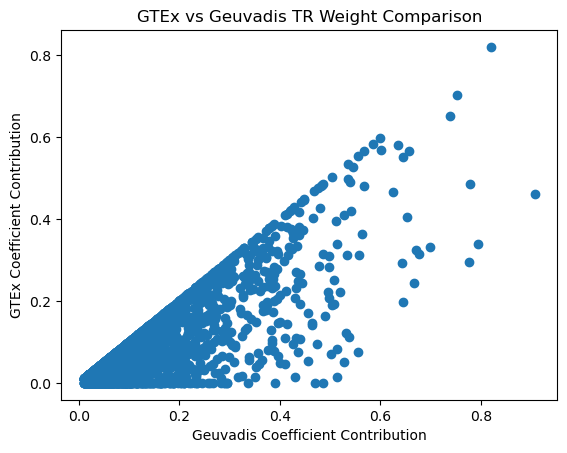

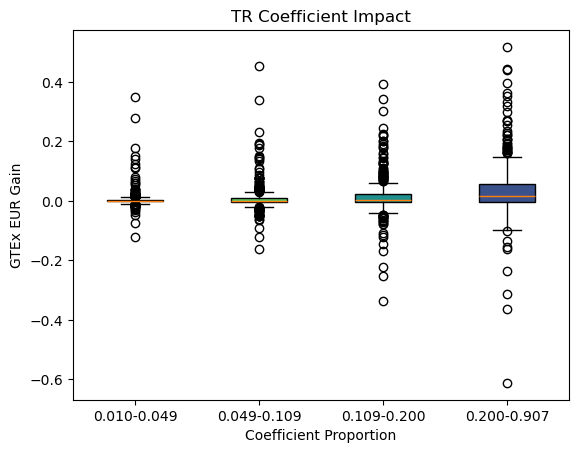

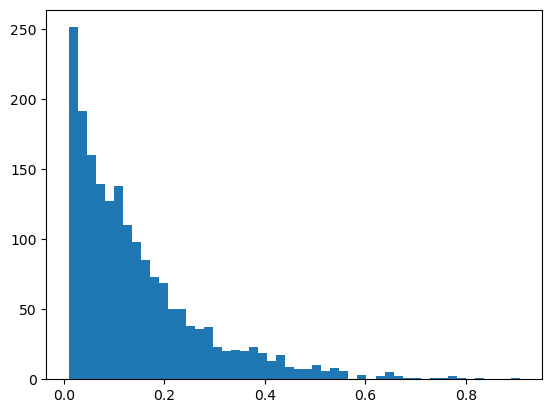

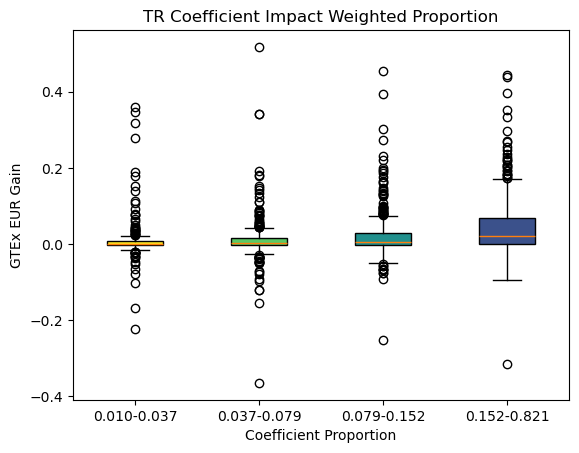

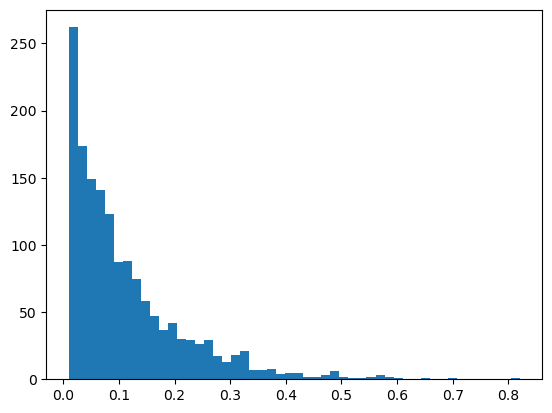

In [12]:
%matplotlib inline

def create_proportion_quantiles(gene_coeffs_gtex, gtex_rsq_df, prop_type='Unweighted', num_quantiles=4):
    strat_info = []
    strat_genes = []

    # First stratify by (Amount of coeff present / total coeff for a gene)
    total_genes = gene_coeffs_gtex.drop_duplicates('Gene_ID')
    for row_ind, row_info in total_genes[['Gene', 'Gene_ID']].iterrows():
        per_gene_info = gene_coeffs_gtex[gene_coeffs_gtex['Gene_ID'] == row_info['Gene_ID']]
        gene_id = row_info['Gene_ID']

        if prop_type == 'Unweighted':
            #proportion = np.sum(per_gene_info['Coeff_Contribution'])/np.sum(np.abs(per_gene_info['TR_Model_Coeff']))
            proportion = np.sum(np.abs(per_gene_info['TR_Model_Coeff']))
        else:
            proportion = np.sum(per_gene_info['Coeff_Contribution'])
        
        if proportion == 0: continue

        try:
            gain = gtex_rsq_df[gtex_rsq_df['gene_id'] == row_info['Gene_ID']]['EUR_Gain'].values[0]
        except:
            continue

        strat_info.append(np.array([proportion, gain]))
        strat_genes.append(gene_id)

    # Sort info
    strat_info = np.array(strat_info)
    gene_ids = np.array(strat_genes)
    sorted_strat_info = strat_info[strat_info[:,0].argsort()]
    sorted_gene_ids = gene_ids[strat_info[:,0].argsort()]
    strat_results = stats.spearmanr(sorted_strat_info, axis=0)
    print(f"{strat_results.statistic} {strat_results.pvalue}")
        
    # Splint into quartiles
    quantiles = np.array_split(sorted_strat_info, num_quantiles)
    print(quantiles[0].shape)
    print(quantiles[1].shape)
    print(quantiles[2].shape)
    print(quantiles[3].shape)

    x_ticks = [
        f'{quantiles[0][0,0]:.3f}-{quantiles[0][-1,0]:.3f}', 
        f'{quantiles[1][0,0]:.3f}-{quantiles[1][-1,0]:.3f}',
        f'{quantiles[2][0,0]:.3f}-{quantiles[2][-1,0]:.3f}',
        f'{quantiles[3][0,0]:.3f}-{quantiles[3][-1,0]:.3f}'
    ]

    quantiles = np.array_split(sorted_strat_info[:,1], num_quantiles)
    return quantiles, x_ticks, sorted_strat_info, sorted_gene_ids
    
def proportion_stratified_boxplot(gene_coeffs_gtex, gtex_rsq_df, title, prop_type='Unweighted'):
    # Calculate quantiles and get the ticks for box plots
    quantiles, x_ticks, sorted_strat_info, sorted_gene_ids = create_proportion_quantiles(gene_coeffs_gtex, gtex_rsq_df, prop_type=prop_type)

    fig = plt.figure()
    ax = fig.add_subplot(1,1,1)
    ax.set_title(title)
    ax.set_xlabel("Coefficient Proportion")
    ax.set_ylabel("GTEx EUR Gain")
    bplot = ax.boxplot(quantiles, patch_artist=True)
    cmap = plt.cm.viridis_r
    for patch, i in zip(bplot['boxes'], range(len(bplot['boxes']))):
        color = cmap(i/len(bplot['boxes']))
        patch.set_facecolor(color)

    ax.set_xticklabels(x_ticks)
    fig.show()

    fig = plt.figure()
    ax = fig.add_subplot(1,1,1)
    ax.hist(sorted_strat_info[:,0], bins=50)
    fig.show()


# Load models with nonzero TRs and their weights as well as if they are present in GTEx
gtex_gene_coeff_file = "/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_genes_coeff_trs.csv"

gene_coeffs_gtex = pd.read_csv(gtex_gene_coeff_file, delimiter=',')
gene_coeffs_gtex['Coeff_Contribution'] = np.abs(gene_coeffs_gtex['TR_Model_Coeff'] * gene_coeffs_gtex['TR_present'])
total_present_tr_weights = np.sum(gene_coeffs_gtex['Coeff_Contribution'])
total_tr_weights = np.sum(np.abs(gene_coeffs_gtex['TR_Model_Coeff']))
print(f"Weighted TRs in GTEx: {total_present_tr_weights}")
print(f"Total Weighted TRs: {total_tr_weights}")

# Plot total weights against present weights
gene_coeffs_gtex['TR_Model_Coeff'] = np.abs(gene_coeffs_gtex['TR_Model_Coeff'])
gtex_coeffs = gene_coeffs_gtex[['Gene_ID', 'TR_Model_Coeff', 'Coeff_Contribution']].groupby('Gene_ID').sum()

fig = plt.figure()
ax = fig.add_subplot(1,1,1)
ax.set_title("GTEx vs Geuvadis TR Weight Comparison")
ax.set_xlabel("Geuvadis Coefficient Contribution")
ax.set_ylabel("GTEx Coefficient Contribution")
ax.scatter(gtex_coeffs['TR_Model_Coeff'], gtex_coeffs['Coeff_Contribution'])
fig.show()

# Stratification by Coeff Weights and whether the TR was present in GTEx data

# Load GTEx R-squared table
gtex_rsq_df = pd.read_csv(
    gtex_table,
    delimiter='\t'
)
gtex_rsq_df.fillna(0, inplace=True)
gtex_rsq_df['EUR_Gain'] = gtex_rsq_df['eur_sample_snp_tr_r2'] - gtex_rsq_df['eur_sample_snp_r2']

# Plot with proportions of TRs present and removing all genes with proportion 0
proportion_stratified_boxplot(gene_coeffs_gtex, gtex_rsq_df, "TR Coefficient Impact")

# Second stratify by (proportion from above * amount of coeff present to weight the proportion by the impact of the trs)
proportion_stratified_boxplot(gene_coeffs_gtex, gtex_rsq_df, "TR Coefficient Impact Weighted Proportion", prop_type="Weighted")

## 0. Validation

### i. Validate our eSTRs with ensembleTR eSTRs

0.9169870599348979


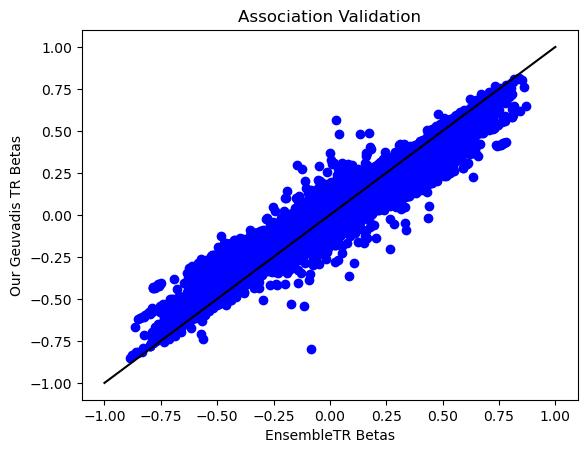

In [10]:
%matplotlib inline

# Load our eTRs
my_geuvadis_df = pd.read_csv(master_table, delimiter='\t', usecols=['gene', 'str.start', 'beta'])

# Load Helia's eTR betas and pvals (should just compare betas) Also compare # of significant TRs
ensembleTR_file = "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/ensembleTR_summstats/1000GenomesH3ARepeats-SuppData16.csv"
ensembleTR_df = pd.read_csv(ensembleTR_file, delimiter=',', usecols=['start', 'ens_gene', 'slope_EUR'])
ensembleTR_df.columns = ['str.start', 'gene', 'ensemble_beta']
ensembleTR_df['gene'] = ensembleTR_df['gene'].str.split('.').str[0]

# Match TR-gene pairs from each study
merged_compare_df = my_geuvadis_df.merge(ensembleTR_df, on=['gene', 'str.start'], how='inner')

# Run a pearson correlation
print(merged_compare_df['beta'].corr(merged_compare_df['ensemble_beta'], method='pearson'))

fig = plt.figure()
ax = fig.add_subplot(1,1,1)
ax.set_title("Association Validation")
ax.set_xlabel("EnsembleTR Betas")
ax.set_ylabel("Our Geuvadis TR Betas")
ax.plot([-1,1], [-1,1], color='black')
ax.scatter(merged_compare_df['beta'], merged_compare_df['ensemble_beta'], color='blue')
fig.show()

### ii. EUR PCs

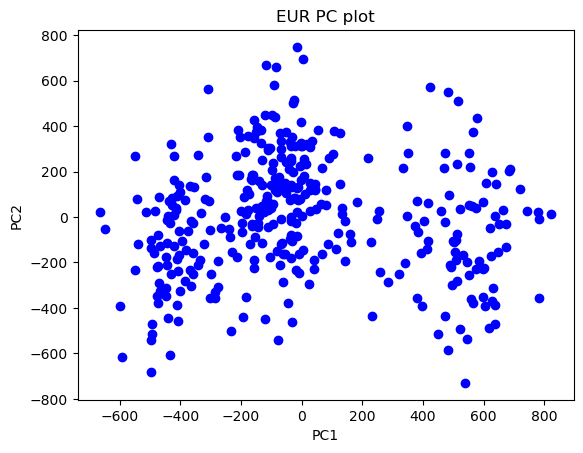

In [3]:
%matplotlib inline
#### PCA Validation 359 EUR samples####
pca_file = '/storage/mlamkin/data/GeneExprPredictor/train_data/EUR_allGT_PCs_hg38.csv'
pca_data = np.loadtxt(pca_file)

fig = plt.figure()
ax = fig.add_subplot(1,1,1)
ax.set_title("EUR PC plot")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.scatter(pca_data[:,0], pca_data[:,1], color='blue')
fig.show()

### iii. Heritability Distribution

                  gene       hsq    hsq_se    hsq.pv
0      ENSG00000236679 -0.002568  0.001709  0.284900
1      ENSG00000236601 -0.001006  0.002660  0.410200
2      ENSG00000237094  0.062504  0.056653  0.046110
3      ENSG00000224813 -0.002232  0.005379  0.395500
4      ENSG00000233653 -0.012242  0.000019  0.016820
...                ...       ...       ...       ...
21257  ENSG00000181090  0.015577  0.015195  0.157500
21258  ENSG00000255585  0.005910  0.014230  0.368100
21259  ENSG00000148408  0.240584  0.087003  0.004597
21260  ENSG00000159247 -0.008883  0.001335  0.105000
21261  ENSG00000233013 -0.005617  0.006506  0.377500

[21262 rows x 4 columns]
(1899, 4)


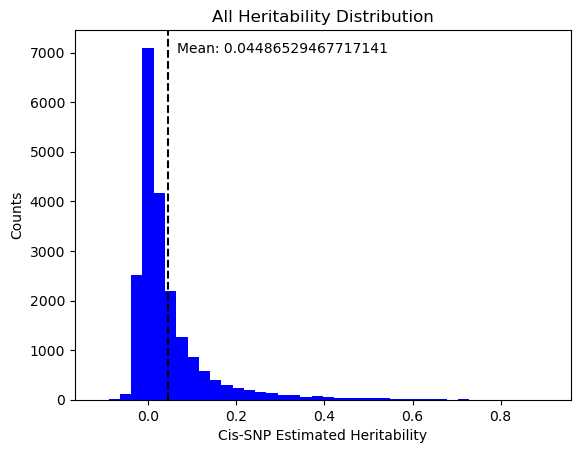

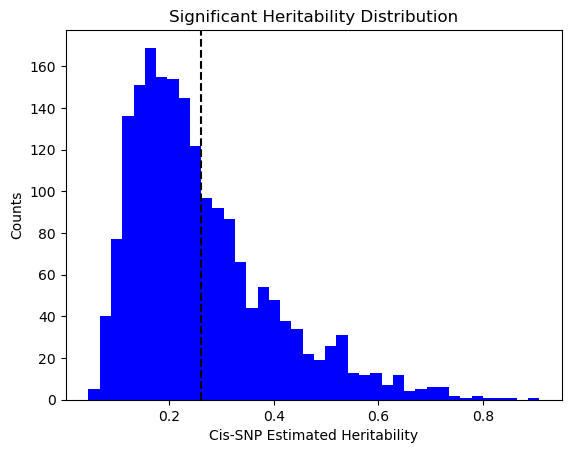

In [3]:
%matplotlib inline

# Load Heritability Data
heritability_file = "/storage/mlamkin/data/GeneExprPredictor/train_data/GEUVADIS_hsq.txt"
h2_df = pd.read_csv(heritability_file, delimiter='\t', comment='#')

print(h2_df)

fig1 = plt.figure()
ax1 = fig1.add_subplot(1,1,1)
ax1.set_title("All Heritability Distribution")
ax1.set_xlabel("Cis-SNP Estimated Heritability")
ax1.set_ylabel("Counts")
ax1.hist(h2_df['hsq'], bins=40, color='blue')
ax1.axvline(h2_df['hsq'].mean(), color='k', linestyle="dashed")
ax1.annotate(f"Mean: {h2_df['hsq'].mean()}", (h2_df['hsq'].mean()+0.02, 7000))
fig1.show()

sig_h2_df = h2_df[h2_df['hsq.pv'] < h2_threshold]
sig_h2_df = sig_h2_df[sig_h2_df['hsq'] > 0]

fig2 = plt.figure()
ax2 = fig2.add_subplot(1,1,1)
ax2.set_title("Significant Heritability Distribution")
ax2.set_xlabel("Cis-SNP Estimated Heritability")
ax2.set_ylabel("Counts")
ax2.hist(sig_h2_df['hsq'], bins=40, color='blue')
ax2.axvline(sig_h2_df['hsq'].mean(), color='k', linestyle="dashed")
ax2.annotate(f"Mean: {sig_h2_df['hsq'].mean()}", (sig_h2_df['hsq'].mean()+0.02, 190))
fig2.show()

### iv. Geuvadis vs GTEx R-squared Validation

Geuvadis vs GTEx EUR SNP Model R-squared
pearson R for Geuvadis vs GTEx: 0.6499449493223651 Pval: 2.3087476340035322e-184 CI:0.6200256345666995-0.6779766962241707
Geuvadis vs GTEx EUR SNP+TR Model R-squared
pearson R for Geuvadis vs GTEx: 0.6711449128354317 Pval: 7.193059450300098e-201 CI:0.6426451189055986-0.6977899551551509
Geuvadis vs GTEx AFR SNP Model R-squared
pearson R for Geuvadis vs GTEx: 0.4525123735279426 Pval: 4.271803426480021e-78 CI:0.41173484954628714-0.4914814445749911
Geuvadis vs GTEx AFR SNP+TR Model R-squared
pearson R for Geuvadis vs GTEx: 0.4602108196174798 Pval: 4.770454704288321e-81 CI:0.41977763817306085-0.4988210003735929
Geuvadis Adjusted R-sq plots
Geuvadis vs GTEx EUR SNP Model R-squared
pearson R for Geuvadis vs GTEx: 0.6508725288343997 Pval: 4.665138502953791e-185 CI:0.621014284175554-0.6788444550121978
Geuvadis vs GTEx EUR SNP+TR Model R-squared
pearson R for Geuvadis vs GTEx: 0.6772250543694616 Pval: 7.344877219326329e-206 CI:0.6491415589974563-0.7034648

/storage/mlamkin/tmp/ipykernel_11851/2859992204.py:82: MatplotlibDeprecationWarning: You have mixed positional and keyword arguments, some input may be discarded.  This is deprecated since 3.9 and will become an error in 3.11.
  fig.legend(handles, labels=['quantile 1','quantile 2','quantile 3','quantile 4'], loc='outside right upper', bbox_to_anchor=(1.05,0.95))


Genes with diff > 0: 737
Genes with diff < 0: 792

pearson R for Geuvadis vs GTEx: 0.23294845832769562 Pval: 2.6644537754939604e-20 CI:0.18499345700235073-0.27979671431156244


'\n\nAFR_gain_sol = odr_fit(\n    f, \n    r2_comparison_df[\'AFR_SNP_STR_R_sq\']- r2_comparison_df[\'AFR_SNP_R_sq\'],\n    r2_comparison_df[\'afr_sample_snp_tr_r2\'] - r2_comparison_df[\'afr_sample_snp_r2\'],\n    [1, 0],\n    bounds=([-20,-1], [20,1])\n)\n\n# NOTE delta = x var error (Geuvadis error) and eps = y var error (GTEx). Doesn\'t output a pval \nprint("AFR Gain Deming Regression")\nprint(f"Beta and intercept: {AFR_gain_sol.beta}")\nprint(f"Geuvadis Error: {AFR_gain_sol.delta}")\nprint(f"GTEx Error: {AFR_gain_sol.eps}")\n\nnum_both_pos = (r2_comparison_df[\'geuv_AFR_gain\'] > 0) & (r2_comparison_df[\'gtex_AFR_gain\'] > 0)\nprint(f"AFR GTEx and Geuvadis Positive Gain:{np.sum(num_both_pos)}")\nscatter_hist_plot(\n    r2_comparison_df[\'geuv_AFR_gain\'], \n    r2_comparison_df[\'gtex_AFR_gain\'], \n    x_label="Geuvadis AFR Gain (Adjusted R-squared)", \n    y_label="GTEx AFR Gain (R-squared)", \n    title="Geuvadis vs GTEx AFR Gain", \n    color=afr_color,\n    scatter_color=r2_

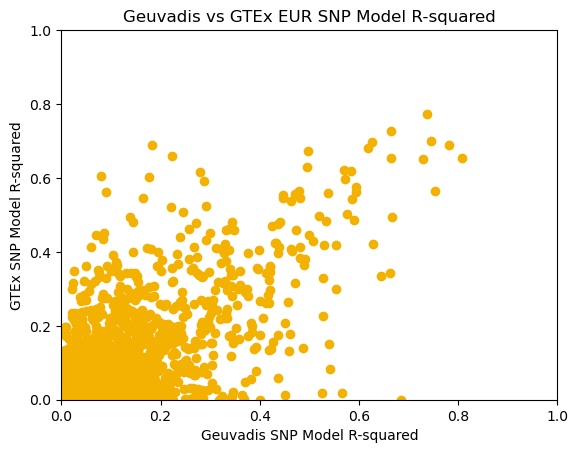

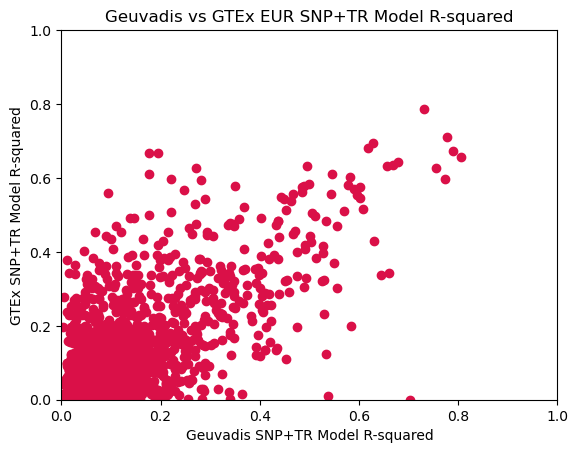

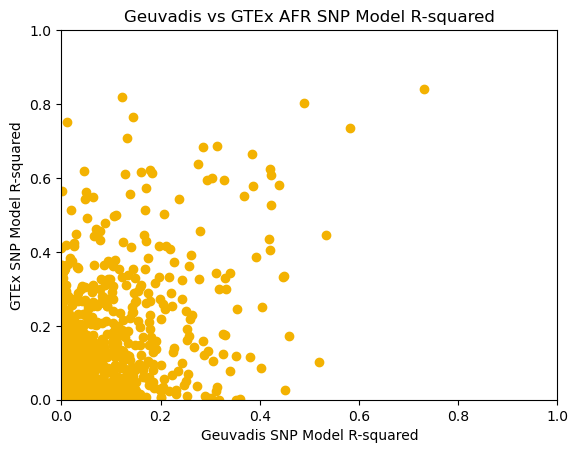

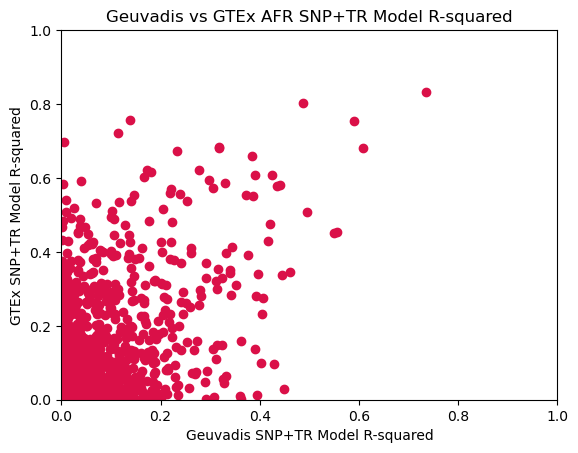

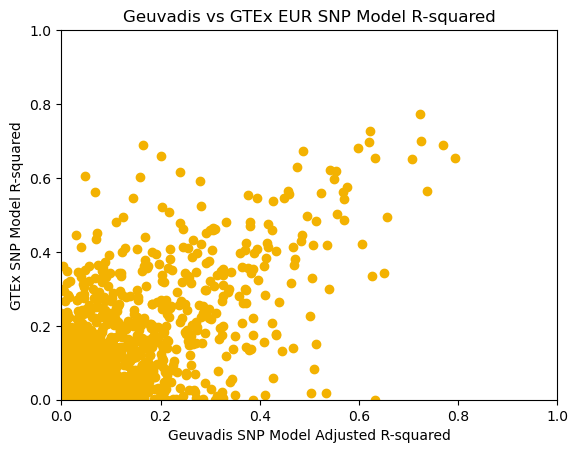

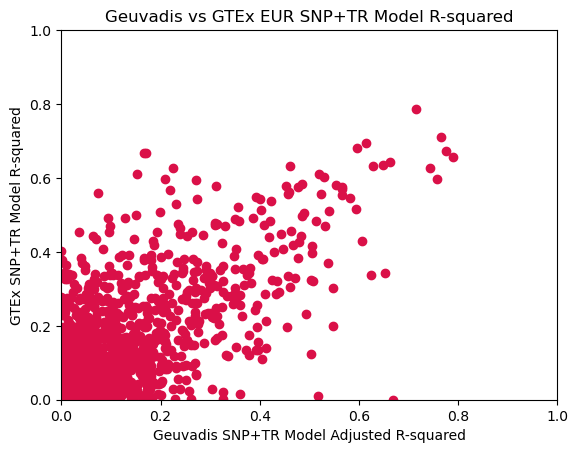

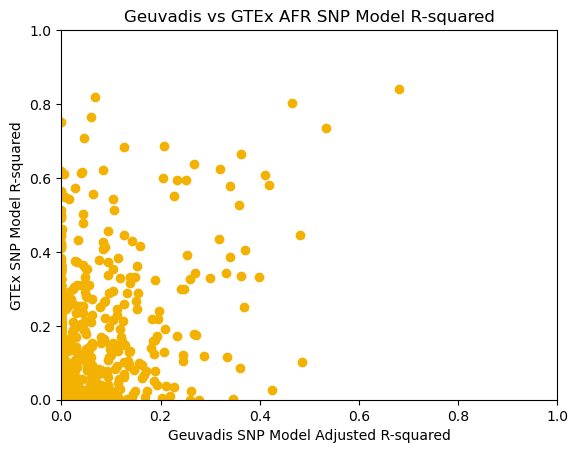

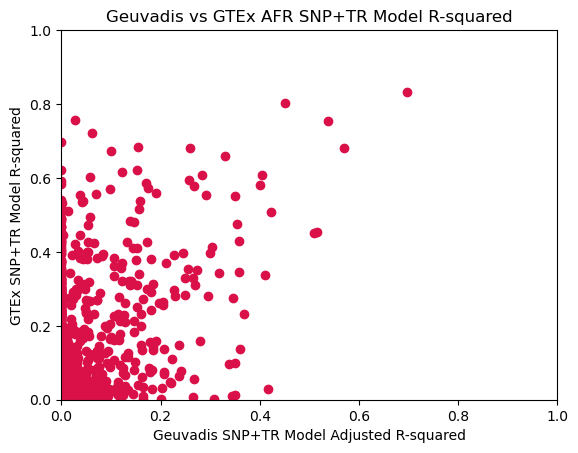

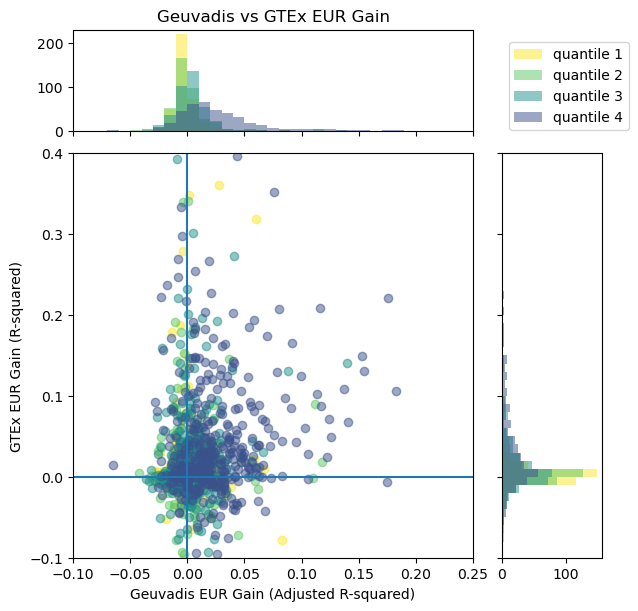

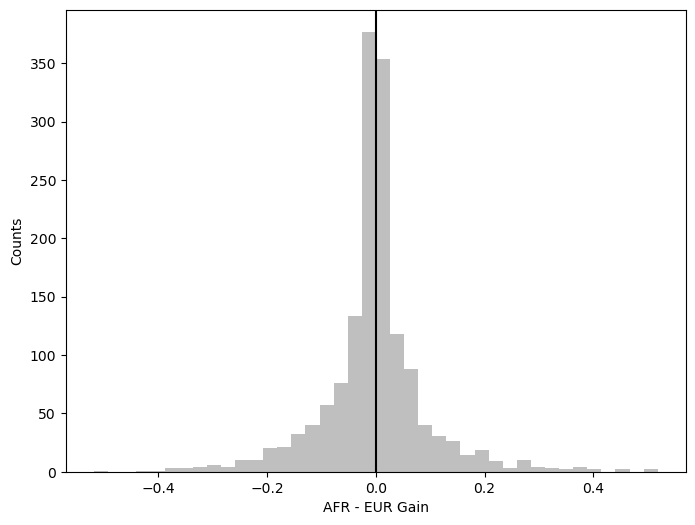

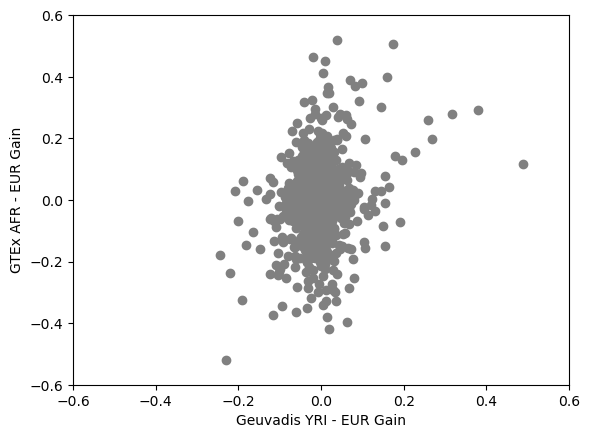

In [13]:
%matplotlib inline

def scatter_hist(x, y, x_hist, y_hist, xlim, ylim, ax, ax_histx, ax_histy, color, scatter_color):
    # no labels
    ax_histx.tick_params(axis="x", labelbottom=False)
    ax_histy.tick_params(axis="y", labelleft=False)

    # now determine nice limits by hand:
    binwidth = 0.01
    xymax = max(np.max(np.abs(x)), np.max(np.abs(y)))
    lim = (int(xymax/binwidth) + 1) * binwidth

    bins = np.arange(-lim, lim + binwidth, binwidth)

    # Plot scatter and hists individually for coloring
    for i in range(len(x_hist)):
        cmap = plt.cm.viridis_r
        color = cmap(i/len(x_hist))
        im = ax.scatter(x_hist[i], y_hist[i], color=color, alpha=0.5)
        ax_histx.hist(x_hist[i], bins=bins, color=color, alpha=0.5, histtype='stepfilled')
        ax_histy.hist(y_hist[i], bins=bins, orientation='horizontal', color=color, alpha=0.5, histtype='stepfilled')

        # Print pearson R for quantiles
        result = stats.pearsonr(x_hist[i], y_hist[i])
        ci = result.confidence_interval(confidence_level=0.95)
        print(f"Pearson R for Geuv vs GTEx Gain Quantile {i+1}")
        print(f"pearson R for Geuvadis vs GTEx: {result.statistic} Pval: {result.pvalue} CI:{ci.low}-{ci.high}")
    ax_histx.set_xlim(xlim)
    ax_histy.set_ylim(ylim)
    return im

def scatter_plot(x_data, y_data, x_label, y_label, title, color, output, xlim=(0,1), ylim=(0,1), draw_axes=False):
    # Calculate pearson correlation for each plot
    result = stats.pearsonr(x_data, y_data)
    ci = result.confidence_interval(confidence_level=0.95)
    print(title)
    print(f"pearson R for Geuvadis vs GTEx: {result.statistic} Pval: {result.pvalue} CI:{ci.low}-{ci.high}")

    fig = plt.figure()
    ax = fig.add_subplot(1,1,1)
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_xlim(xlim[0], xlim[1])
    ax.set_ylim(ylim[0], ylim[1])
    im = ax.scatter(x_data, y_data, color=color)
    if draw_axes:
        ax.vlines(0, ylim[0], ylim[1])
        ax.hlines(0, xlim[0], xlim[1])
    fig.savefig(output)
    fig.show()

    return


def scatter_hist_plot(x_data, y_data, x_hist, y_hist, x_label, y_label, title, color, scatter_color, output, xlim=(-1,1), ylim=(-1,1), draw_axes=False):
    # Calculate pearson correlation for each plot
    result = stats.pearsonr(x_data, y_data)
    ci = result.confidence_interval(confidence_level=0.95)
    print(title)
    print(f"pearson R for Geuvadis vs GTEx: {result.statistic} Pval: {result.pvalue} CI:{ci.low}-{ci.high}")

    fig, ax = plt.subplot_mosaic([['histx', '.'],
                                ['scatter', 'histy']],
                                figsize=(6, 6),
                                width_ratios=(4, 1), height_ratios=(1, 4),
                                layout='constrained')
    im = scatter_hist(x_data, y_data, x_hist, y_hist, xlim, ylim, ax['scatter'], ax['histx'], ax['histy'], color, scatter_color)

    ax['histx'].set_title(title)
    ax['scatter'].set_xlabel(x_label)
    ax['scatter'].set_ylabel(y_label)
    ax['scatter'].set_xlim(xlim[0], xlim[1])
    ax['scatter'].set_ylim(ylim[0], ylim[1])

    if draw_axes:
        ax['scatter'].vlines(0, ylim[0], ylim[1])
        ax['scatter'].hlines(0, xlim[0], xlim[1])

    # Draw colorbar
    handles, labels = ax['histx'].get_legend_handles_labels()
    fig.legend(handles, labels=['quantile 1','quantile 2','quantile 3','quantile 4'], loc='outside right upper', bbox_to_anchor=(1.05,0.95))
    fig.savefig(output, bbox_inches='tight')
    fig.show()

    return

def hist_plot(
    hist_values,
    output
):
    # Plot all genes with eSTRs with color
    # Note use this color if need an inbetween with nonestr and estr genes (246/256, 164/256, 130/256)
    color = (128/256,128/256,128/256)
    fig = plt.figure(figsize=(8,6))
    ax = fig.add_subplot(1,1,1)
    ax.set_xlabel('AFR - EUR Gain')
    ax.set_ylabel('Counts')

    ax.hist(
        hist_values, 
        bins=40,
        alpha=0.5,
        color=color
    )
    # Plot line at 0 to indicate where SNP+TR did better and SNP only did better
    ax.axvline(0, color='k')

    print(f"Genes with diff > 0: {np.sum(hist_values > 0)}")
    print(f"Genes with diff < 0: {np.sum(hist_values < 0)}")

    fig.savefig(output)
    fig.show()


# Load GTEx R-squared table
gtex_rsq_df = pd.read_csv(
    gtex_table,
    delimiter='\t'
)
gtex_rsq_df.fillna(0, inplace=True)

# Filter GTEx table to keep genes that had at least one TR with nonzero coeffs present
valid_genes_df = pd.read_csv(
    '/gymreklab-tscc/mlamkin/GeneExprPredictor_data/final_results/gtex_genes_with_trs.txt',
    names=['gene_name', 'gene_id', 'region', 'has_tr'],
    delimiter=' '
)
valid_genes_df.drop_duplicates(subset=['gene_id'], inplace=True)
gtex_rsq_df = gtex_rsq_df.merge(valid_genes_df, left_on=['gene_name', 'gene_id'], right_on=['gene_name', 'gene_id'])

# Load Master Table (gene, p.linear, EUR_alleles, EUR_het, snp_adj_r_squared, snp_str_adj_r_squared)
validation_rsq_df = pd.read_csv(
    master_table, 
    delimiter='\t', 
    usecols=[
        'gene',
        'hsq', 
        'hsq.pv',
        'EUR_SNP_R_sq_Mean', 
        'EUR_SNP_STR_R_sq_Mean',
        'EUR_SNP_adj_R_sq_Mean', 
        'EUR_SNP_STR_adj_R_sq_Mean',
        'AFR_SNP_R_sq',
        'AFR_SNP_STR_R_sq',
        'AFR_SNP_adj_R_sq',
        'AFR_SNP_STR_adj_R_sq',
    ]
)

# Filter duplicates
validation_rsq_df.drop_duplicates('gene', inplace=True)
validation_rsq_df.fillna(0, inplace=True)
validation_rsq_df.dropna(inplace=True)

#### Genes that trained ####
# NOTE trained_rsq_df is the finalized df we work with for downstream analyses all others are for comparison purposes
# Filter out genes that didnt train (negative for both) and report these updated numbers under the filtering
validation_rsq_df = validation_rsq_df[(validation_rsq_df['EUR_SNP_adj_R_sq_Mean'] > 0) | (validation_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] > 0)]
validation_rsq_df.loc[validation_rsq_df['EUR_SNP_adj_R_sq_Mean'] < 0, 'EUR_SNP_adj_R_sq_Mean'] = 0
validation_rsq_df.loc[validation_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] < 0, 'EUR_SNP_STR_adj_R_sq_Mean'] = 0
validation_rsq_df.loc[validation_rsq_df['AFR_SNP_adj_R_sq'] < 0, 'AFR_SNP_adj_R_sq'] = 0
validation_rsq_df.loc[validation_rsq_df['AFR_SNP_STR_adj_R_sq'] < 0, 'AFR_SNP_STR_adj_R_sq'] = 0

# Filter duplicates
r2_comparison_df = gtex_rsq_df.merge(validation_rsq_df, left_on=['gene_id'], right_on=['gene'])
r2_comparison_df.to_csv("/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_Geuvadis_r2_table.csv", index=False)

# Do comparisons for SNP only model and SNP+TR model

#### Unadjusted R-squared Plots ####
# EUR R-sq plots
scatter_plot(
    r2_comparison_df['EUR_SNP_R_sq_Mean'],
    r2_comparison_df['eur_sample_snp_r2'], 
    x_label="Geuvadis SNP Model R-squared", 
    y_label="GTEx SNP Model R-squared", 
    title="Geuvadis vs GTEx EUR SNP Model R-squared", 
    color=snp_model_color,
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_EUR_snp_rsq.pdf"
)

scatter_plot(
    r2_comparison_df['EUR_SNP_STR_R_sq_Mean'], 
    r2_comparison_df['eur_sample_snp_tr_r2'], 
    x_label="Geuvadis SNP+TR Model R-squared", 
    y_label="GTEx SNP+TR Model R-squared", 
    title="Geuvadis vs GTEx EUR SNP+TR Model R-squared", 
    color=snp_tr_model_color,
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_EUR_snp_tr_rsq.pdf"
)

# AFR R-sq plots 
scatter_plot(
    r2_comparison_df['AFR_SNP_R_sq'], 
    r2_comparison_df['afr_sample_snp_r2'], 
    x_label="Geuvadis SNP Model R-squared", 
    y_label="GTEx SNP Model R-squared", 
    title="Geuvadis vs GTEx AFR SNP Model R-squared", 
    color=snp_model_color,
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_AFR_snp_rsq.pdf"
)

scatter_plot(
    r2_comparison_df['AFR_SNP_STR_R_sq'], 
    r2_comparison_df['afr_sample_snp_tr_r2'], 
    x_label="Geuvadis SNP+TR Model R-squared", 
    y_label="GTEx SNP+TR Model R-squared", 
    title="Geuvadis vs GTEx AFR SNP+TR Model R-squared", 
    color=snp_tr_model_color,
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_AFR_snp_tr_rsq.pdf"
)


#### Adjusted R-squared Plots (Adjusted only for Geuvadis) ####
print("Geuvadis Adjusted R-sq plots")
# EUR R-sq plots
scatter_plot(
    r2_comparison_df['EUR_SNP_adj_R_sq_Mean'], 
    r2_comparison_df['eur_sample_snp_r2'], 
    x_label="Geuvadis SNP Model Adjusted R-squared", 
    y_label="GTEx SNP Model R-squared", 
    title="Geuvadis vs GTEx EUR SNP Model R-squared", 
    color=snp_model_color,
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_EUR_snp_adj_rsq.pdf"
)

scatter_plot(
    r2_comparison_df['EUR_SNP_STR_adj_R_sq_Mean'], 
    r2_comparison_df['eur_sample_snp_tr_r2'], 
    x_label="Geuvadis SNP+TR Model Adjusted R-squared", 
    y_label="GTEx SNP+TR Model R-squared", 
    title="Geuvadis vs GTEx EUR SNP+TR Model R-squared", 
    color=snp_tr_model_color,
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_EUR_snp_tr_adj_rsq.pdf"
)

# AFR R-sq plots 
scatter_plot(
    r2_comparison_df['AFR_SNP_adj_R_sq'], 
    r2_comparison_df['afr_sample_snp_r2'], 
    x_label="Geuvadis SNP Model Adjusted R-squared", 
    y_label="GTEx SNP Model R-squared", 
    title="Geuvadis vs GTEx AFR SNP Model R-squared", 
    color=snp_model_color,
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_AFR_snp_adj_rsq.pdf"
)

scatter_plot(
    r2_comparison_df['AFR_SNP_STR_adj_R_sq'], 
    r2_comparison_df['afr_sample_snp_tr_r2'], 
    x_label="Geuvadis SNP+TR Model Adjusted R-squared", 
    y_label="GTEx SNP+TR Model R-squared", 
    title="Geuvadis vs GTEx AFR SNP+TR Model R-squared", 
    color=snp_tr_model_color,
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_AFR_snp_tr_adj_rsq.pdf"
)

# Plot gain in R-squared comparison
r2_comparison_df['geuv_EUR_gain'] = r2_comparison_df['EUR_SNP_STR_adj_R_sq_Mean'] - r2_comparison_df['EUR_SNP_adj_R_sq_Mean']
r2_comparison_df['geuv_AFR_gain'] = r2_comparison_df['AFR_SNP_STR_R_sq']- r2_comparison_df['AFR_SNP_R_sq']
r2_comparison_df['gtex_EUR_gain'] = r2_comparison_df['eur_sample_snp_tr_r2'] - r2_comparison_df['eur_sample_snp_r2']
r2_comparison_df['gtex_AFR_gain'] = r2_comparison_df['afr_sample_snp_tr_r2'] - r2_comparison_df['afr_sample_snp_r2']

# Use odr_fit (Deming regression because it accounnts for error on x and y variables)
def f(x: np.ndarray, beta: np.ndarray) -> np.ndarray:
    return beta[0]*x + beta[1]

EUR_gain_sol = odr_fit(
    f, 
    r2_comparison_df['geuv_EUR_gain'],
    r2_comparison_df['gtex_EUR_gain'],
    [1, 0],
    bounds=([-20,-1], [20,1])
)
# NOTE delta = x var error (Geuvadis error) and eps = y var error (GTEx). Doesn't output a pval 
print("EUR Gain Deming Regression")
print(f"Beta and intercept: {EUR_gain_sol.beta}")
print(f"Geuvadis Error: {EUR_gain_sol.delta}")
print(f"GTEx Error: {EUR_gain_sol.eps}")

num_both_pos = (r2_comparison_df['geuv_EUR_gain'] > 0 ) & ((r2_comparison_df['gtex_EUR_gain']) > 0)
print(f"EUR GTEx and Geuvadis Positive Gain:{np.sum(num_both_pos)}")

# Load models with nonzero TRs and their weights as well as if they are present in GTEx
gtex_gene_coeff_file = "/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_genes_coeff_trs.csv"
gene_coeffs_gtex = pd.read_csv(gtex_gene_coeff_file, delimiter=',')
gene_coeffs_gtex['TR_Model_Coeff'] = np.abs(gene_coeffs_gtex['TR_Model_Coeff'])
gene_coeffs_gtex['Coeff_Contribution'] = gene_coeffs_gtex['TR_Model_Coeff'] * gene_coeffs_gtex['TR_present']
gtex_coeffs = gene_coeffs_gtex[['Gene_ID', 'TR_Model_Coeff', 'Coeff_Contribution']].groupby('Gene_ID').sum()
gtex_coeffs['Coeff_Proportion'] = gtex_coeffs['Coeff_Contribution']
r2_comparison_df = r2_comparison_df.merge(gtex_coeffs, left_on='gene', right_on='Gene_ID')

# Grab info needed for quantiles
# Load models with nonzero TRs and their weights as well as if they are present in GTEx

# Load GTEx R-squared table
gtex_rsq_df = pd.read_csv(
    gtex_table,
    delimiter='\t'
)
gtex_rsq_df.fillna(0, inplace=True)
gtex_rsq_df['EUR_Gain'] = gtex_rsq_df['eur_sample_snp_tr_r2'] - gtex_rsq_df['eur_sample_snp_r2']

# Collect Quartiles for histograms
quantiles, x_ticks, sorted_strat_info, sorted_gene_ids = create_proportion_quantiles(gene_coeffs_gtex, gtex_rsq_df, prop_type='Weighted', num_quantiles=4)

# Collect histograms separated by quartiles (For both gtex and geuvadis)
gtex_EUR_hist_r2 = []
geuv_EUR_hist_r2 = []
start_ind = 0
for quantile in quantiles:
    quantile_genes = sorted_gene_ids[start_ind:start_ind+quantile.shape[0]]
    matching_quantile_df = r2_comparison_df[r2_comparison_df['gene_id'].isin(quantile_genes)]
    gtex_EUR_quantile = matching_quantile_df['gtex_EUR_gain']
    geuv_EUR_quantile = matching_quantile_df['geuv_EUR_gain']
    gtex_EUR_hist_r2.append(gtex_EUR_quantile)
    geuv_EUR_hist_r2.append(geuv_EUR_quantile)
    start_ind += quantile.shape[0]

scatter_hist_plot(
    r2_comparison_df['geuv_EUR_gain'],
    r2_comparison_df['gtex_EUR_gain'],
    geuv_EUR_hist_r2,
    gtex_EUR_hist_r2,
    x_label="Geuvadis EUR Gain (Adjusted R-squared)", 
    y_label="GTEx EUR Gain (R-squared)", 
    title="Geuvadis vs GTEx EUR Gain", 
    color=eur_color,
    scatter_color=r2_comparison_df['Coeff_Proportion'],
    xlim=(-0.1,0.25), 
    ylim=(-0.1, 0.4),#(-0.6,0.6) for full figure size
    draw_axes=True,
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_EUR_gain.pdf"
)

# AFR - EUR Gain for unadjusted R-squared
hist_plot(
    r2_comparison_df['gtex_AFR_gain'] - r2_comparison_df['gtex_EUR_gain'],
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_AFR_EUR_gain_histogram.pdf"
)

# AFR - EUR gain in Geuvadis vs GTEx
scatter_plot(
    r2_comparison_df['geuv_AFR_gain'] - r2_comparison_df['geuv_EUR_gain'], 
    r2_comparison_df['gtex_AFR_gain'] - r2_comparison_df['gtex_EUR_gain'], 
    x_label="Geuvadis YRI - EUR Gain", 
    y_label="GTEx AFR - EUR Gain", 
    xlim=(-0.6,0.6), 
    ylim=(-0.6,0.6),
    title="", 
    color='gray',
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_AFR_EUR_gain.pdf"
)

"""

AFR_gain_sol = odr_fit(
    f, 
    r2_comparison_df['AFR_SNP_STR_R_sq']- r2_comparison_df['AFR_SNP_R_sq'],
    r2_comparison_df['afr_sample_snp_tr_r2'] - r2_comparison_df['afr_sample_snp_r2'],
    [1, 0],
    bounds=([-20,-1], [20,1])
)

# NOTE delta = x var error (Geuvadis error) and eps = y var error (GTEx). Doesn't output a pval 
print("AFR Gain Deming Regression")
print(f"Beta and intercept: {AFR_gain_sol.beta}")
print(f"Geuvadis Error: {AFR_gain_sol.delta}")
print(f"GTEx Error: {AFR_gain_sol.eps}")

num_both_pos = (r2_comparison_df['geuv_AFR_gain'] > 0) & (r2_comparison_df['gtex_AFR_gain'] > 0)
print(f"AFR GTEx and Geuvadis Positive Gain:{np.sum(num_both_pos)}")
scatter_hist_plot(
    r2_comparison_df['geuv_AFR_gain'], 
    r2_comparison_df['gtex_AFR_gain'], 
    x_label="Geuvadis AFR Gain (Adjusted R-squared)", 
    y_label="GTEx AFR Gain (R-squared)", 
    title="Geuvadis vs GTEx AFR Gain", 
    color=afr_color,
    scatter_color=r2_comparison_df['Coeff_Proportion'],
    xlim=(-0.4,0.6), 
    ylim=(-0.6,0.6),
    draw_axes=True,
    output="/storage/mlamkin/data/GeneExprPredictor/paper_figures/GTEx_vs_Geuvadis_AFR_gain.pdf"
)
"""


## 2. SNP Models R-squared vs SNP + TR Models R-squared

### 0. Create Table of adjusted R-sq, num genes, etc for different sets of genes (non h2, h2, h2 with estr)

In [6]:
def pval_test(h2, non_h2):
    # Get mann whitney between (h2 and non h2) and (estrh2 and non h2)
    res1 = stats.mannwhitneyu(non_h2['adj_rsq_diff'], h2['adj_rsq_diff'], alternative='less')
    print(f"non_h2 vs h2 one-sided mannwhitneyu pval: {res1.pvalue}")
    return

def generate_table(
    all_genes_dfs,
    trained_genes_dfs,
):
    h2 = all_genes_dfs[0]
    non_h2 = all_genes_dfs[1]
    trained_h2 = trained_genes_dfs[0]
    trained_non_h2 = trained_genes_dfs[1]

    df_data = {
        'Delta_adj_r2_mean': [h2['adj_rsq_diff'].mean(), non_h2['adj_rsq_diff'].mean()],
        'Delta_var_explained_mean': [h2['var_explained'].mean(), non_h2['var_explained'].mean()],
        'Num_Genes': [h2.shape[0], non_h2.shape[0]],
        'Num_Genes >= 0.05 R_sq': [np.sum(h2['adj_rsq_diff'] >= 0.05), np.sum(non_h2['adj_rsq_diff'] >= 0.05)],
        'Delta_adj_r2_mean_trained': [trained_h2['adj_rsq_diff'].mean(), trained_non_h2['adj_rsq_diff'].mean()],
        'Delta_var_explained_mean_trained': [trained_h2['var_explained'].mean(), trained_non_h2['var_explained'].mean()],
        'Num_Genes_Trained (Non-negative r2)': [trained_h2.shape[0], trained_non_h2.shape[0]],
        'Num_Genes_Trained >= 0.05 R_sq': [np.sum(trained_h2['adj_rsq_diff'] >= 0.05), np.sum(trained_non_h2['adj_rsq_diff'] >= 0.05)],
    }
    table_df = pd.DataFrame(df_data)
    print(table_df)

    print("All Genes P-value Tests")
    pval_test(h2, non_h2)

    print("Trained Genes P-value Tests")
    pval_test(trained_h2, trained_non_h2)
    return

# Load adjusted Pvalues for eSTRs to use for significance
corrected_pvals_file = "/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_gene_expr_linear_corrected_best_pvals.csv"
corrected_pvals = pd.read_csv(corrected_pvals_file, delimiter=',', usecols=['gene', 'str.start', 'p.linear'])
corrected_pvals_sig = corrected_pvals[corrected_pvals['p.linear'] <= 0.05]  # Filter to only significant p-values
corrected_pvals_sig['gene'] = corrected_pvals_sig['gene'].str.split('.').str[0] # remove everything after '.' in gene

# Load Master Table (gene, p.linear, EUR_alleles, EUR_het, snp_adj_r_squared, snp_str_adj_r_squared)
rsq_df = pd.read_csv(
    master_table, 
    delimiter='\t', 
    usecols=[
        'gene_name',
        'gene',
        'str.start',
        'p.linear',
        'afreq_EUR', 
        'het_EUR',
        'hsq', 
        'hsq.pv',
        'EUR_SNP_R_sq_Mean', 
        'EUR_SNP_STR_R_sq_Mean', 
        'EUR_SNP_adj_R_sq_Mean', 
        'EUR_SNP_STR_adj_R_sq_Mean',
        'EUR_nonlinear_adj_R_sq_Mean',
        'AFR_SNP_R_sq',
        'AFR_SNP_STR_R_sq',
        'AFR_nonlinear_R_sq',
        'AFR_SNP_adj_R_sq',
        'AFR_SNP_STR_adj_R_sq',
        'AFR_nonlinear_adj_R_sq',
        'EUR_SNP_avg_coeff_0.01',
        'EUR_SNP_avg_coeff_0.001',
        'EUR_SNP_avg_coeff_1e-08',
        'EUR_SNP_STR_avg_coeff_0.01',
        'EUR_SNP_STR_avg_coeff_0.001',
        'EUR_SNP_STR_avg_coeff_1e-08',
    ]
)

#### Genes that trained ####
# NOTE trained_rsq_df is the finalized df we work with for downstream analyses all others are for comparison purposes
# Filter out genes that didnt train (negative for both) and report these updated numbers under the filtering
trained_rsq_df = rsq_df[(rsq_df['EUR_SNP_adj_R_sq_Mean'] > 0) | (rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] > 0)]
trained_rsq_df.loc[trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] < 0, 'EUR_SNP_adj_R_sq_Mean'] = 0
trained_rsq_df.loc[trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] < 0, 'EUR_SNP_STR_adj_R_sq_Mean'] = 0
trained_rsq_df.loc[trained_rsq_df['EUR_nonlinear_adj_R_sq_Mean'] < 0, 'EUR_nonlinear_adj_R_sq_Mean'] = 0
trained_rsq_df.loc[trained_rsq_df['AFR_SNP_adj_R_sq'] < 0, 'AFR_SNP_adj_R_sq'] = 0
trained_rsq_df.loc[trained_rsq_df['AFR_SNP_STR_adj_R_sq'] < 0, 'AFR_SNP_STR_adj_R_sq'] = 0
trained_rsq_df.loc[trained_rsq_df['AFR_nonlinear_adj_R_sq'] < 0, 'AFR_nonlinear_adj_R_sq'] = 0
trained_rsq_df['adj_rsq_diff'] = trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] - trained_rsq_df['EUR_SNP_adj_R_sq_Mean']
trained_rsq_df['afr_rsq_diff'] = trained_rsq_df['AFR_SNP_STR_R_sq'] - trained_rsq_df['AFR_SNP_R_sq']
nonlin_max = trained_rsq_df[['EUR_SNP_adj_R_sq_Mean', 'EUR_SNP_STR_adj_R_sq_Mean']].max(axis=1)
afr_nonlin_max = trained_rsq_df[['AFR_SNP_R_sq', 'AFR_SNP_STR_R_sq']].max(axis=1)
trained_rsq_df['nonlin_adj_rsq_overall_diff'] = trained_rsq_df['EUR_nonlinear_adj_R_sq_Mean'] - nonlin_max
trained_rsq_df['nonlin_adj_rsq_snp_diff'] = trained_rsq_df['EUR_nonlinear_adj_R_sq_Mean'] - trained_rsq_df['EUR_SNP_adj_R_sq_Mean']
trained_rsq_df['afr_nonlin_rsq_diff'] = trained_rsq_df['AFR_nonlinear_R_sq'] - afr_nonlin_max
trained_rsq_df['afr_nonlin_rsq_snp_diff'] = trained_rsq_df['AFR_nonlinear_R_sq'] - trained_rsq_df['AFR_SNP_R_sq']
trained_rsq_df['var_explained'] = create_variance_explained(trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean']/trained_rsq_df['hsq']) - \
        create_variance_explained(trained_rsq_df['EUR_SNP_adj_R_sq_Mean']/trained_rsq_df['hsq'])
trained_rsq_df.fillna(0, inplace=True)

# Create different rows of data
# 1. Heritable Genes
trained_h2_rsq_df = trained_rsq_df[(trained_rsq_df['hsq.pv'] < h2_threshold) & (trained_rsq_df['hsq'] > 0)]
trained_h2_rsq_df.dropna(inplace=True)

# 2. Non-heritable Genes
trained_non_h2_rsq_df = trained_rsq_df[~((trained_rsq_df['hsq.pv'] < h2_threshold) & (trained_rsq_df['hsq'] > 0))]
trained_estr_non_h2_rsq_df = trained_non_h2_rsq_df[['gene', 'str.start', 'adj_rsq_diff', 'var_explained', 'hsq', 'hsq.pv', 'EUR_SNP_adj_R_sq_Mean', 'EUR_SNP_STR_adj_R_sq_Mean']].merge(corrected_pvals_sig, on=['gene', 'str.start'], how='inner')
trained_estr_non_h2_rsq_df.drop_duplicates('gene', inplace=True)
trained_estr_non_h2_rsq_df.dropna(inplace=True)
trained_non_h2_rsq_df.drop_duplicates('gene', inplace=True)
trained_non_h2_rsq_df.dropna(inplace=True)

# 3. Heritable with eSTR Genes
trained_estr_h2_rsq_df = trained_h2_rsq_df[['gene', 'str.start', 'adj_rsq_diff', 'var_explained', 'hsq', 'hsq.pv', 'EUR_SNP_adj_R_sq_Mean', 'EUR_SNP_STR_adj_R_sq_Mean']].merge(corrected_pvals_sig, on=['gene', 'str.start'], how='inner')

# Drop gene duplicates now that we've matched variants in estr_h2_rsq_df
trained_h2_rsq_df.drop_duplicates('gene', inplace=True)
trained_estr_h2_rsq_df.drop_duplicates('gene', inplace=True)
trained_rsq_df.drop_duplicates('gene', inplace=True)
trained_rsq_df.dropna(inplace=True)
trained_dfs = [trained_h2_rsq_df, trained_non_h2_rsq_df]

# fisher exact for enrichment of eSTR in heritable genes row = eSTR, no esTR, col = heritable, not heritable
estr_enrichment_table = np.array([
    [trained_estr_h2_rsq_df.shape[0], trained_estr_non_h2_rsq_df.shape[0]], 
    [trained_h2_rsq_df.shape[0] - trained_estr_h2_rsq_df.shape[0], trained_non_h2_rsq_df.shape[0] - trained_estr_non_h2_rsq_df.shape[0]]
])
print("Fisher contingency table: row = eSTR, no esTR, col = heritable, not heritable")
print(estr_enrichment_table)
fisher_res = stats.fisher_exact(estr_enrichment_table, alternative='greater')
print(f"fisher exact odds ratio: {fisher_res[0]}")
print(f"fisher exact one-sided pval: {fisher_res[1]}")

#### All genes ####
# Convert all negative R-squared's to 0 (Otherwise it will infalte the delta R-squared value)
rsq_df.loc[rsq_df['EUR_SNP_adj_R_sq_Mean'] < 0, 'EUR_SNP_adj_R_sq_Mean'] = 0
rsq_df.loc[rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] < 0, 'EUR_SNP_STR_adj_R_sq_Mean'] = 0

# Create adjusted R-sqaured difference col
rsq_df['adj_rsq_diff'] = rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] - rsq_df['EUR_SNP_adj_R_sq_Mean']

# Create variance explained col
rsq_df['var_explained'] = create_variance_explained(rsq_df['EUR_SNP_STR_adj_R_sq_Mean']/rsq_df['hsq']) - \
        create_variance_explained(rsq_df['EUR_SNP_adj_R_sq_Mean']/rsq_df['hsq'])

# Create different rows of data
# 1. Heritable Genes
h2_rsq_df = rsq_df[(rsq_df['hsq.pv'] < h2_threshold) & (rsq_df['hsq'] > 0)]
h2_rsq_df.dropna(inplace=True)

# 2. Non-heritable Genes
non_h2_rsq_df = rsq_df[~((rsq_df['hsq.pv'] < h2_threshold) & (rsq_df['hsq'] > 0))]
non_h2_rsq_df.drop_duplicates('gene', inplace=True)
non_h2_rsq_df.dropna(inplace=True)

# 3. Heritable with an eSTR Genes
estr_h2_rsq_df = h2_rsq_df[['gene', 'str.start', 'adj_rsq_diff', 'var_explained', 'hsq', 'hsq.pv', 'EUR_SNP_adj_R_sq_Mean', 'EUR_SNP_STR_adj_R_sq_Mean']].merge(corrected_pvals_sig, on=['gene', 'str.start'], how='inner')

# Drop gene duplicates now that we've matched variants in estr_h2_rsq_df
h2_rsq_df.drop_duplicates('gene', inplace=True)
estr_h2_rsq_df.drop_duplicates('gene', inplace=True)
rsq_df.drop_duplicates('gene', inplace=True)
rsq_df.fillna(0, inplace=True)

all_gene_dfs = [h2_rsq_df, non_h2_rsq_df]

print(f"Overall genes adj rsq diff for {rsq_df.shape[0]} genes: {rsq_df['adj_rsq_diff'].mean()}")
print(f"Trained genes adj rsq diff for {trained_rsq_df.shape[0]} genes: {trained_rsq_df['adj_rsq_diff'].mean()}")

print(f"Overall genes var_explained diff for {rsq_df.shape[0]} genes: {rsq_df['var_explained'].mean()}")
print(f"Trained genes var_explained diff for {trained_rsq_df.shape[0]} genes: {trained_rsq_df['var_explained'].mean()}")

generate_table(all_gene_dfs, trained_dfs)

/storage/mlamkin/tmp/ipykernel_15997/881830255.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  corrected_pvals_sig['gene'] = corrected_pvals_sig['gene'].str.split('.').str[0] # remove everything after '.' in gene
/storage/mlamkin/tmp/ipykernel_15997/881830255.py:85: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trained_rsq_df['adj_rsq_diff'] = trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] - trained_rsq_df['EUR_SNP_adj_R_sq_Mean']
/storage/mlamkin/tmp/ipykernel_15997/881830255.py:86: SettingWithCopyWarnin

Fisher contingency table: row = eSTR, no esTR, col = heritable, not heritable
[[1186 1167]
 [   9  191]]
fisher exact odds ratio: 21.567742549747692
fisher exact one-sided pval: 1.3473559840565233e-43


/storage/mlamkin/tmp/ipykernel_15997/881830255.py:146: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  h2_rsq_df.dropna(inplace=True)
/storage/mlamkin/tmp/ipykernel_15997/881830255.py:150: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_h2_rsq_df.drop_duplicates('gene', inplace=True)
/storage/mlamkin/tmp/ipykernel_15997/881830255.py:151: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_h2_rsq_df.dropna(inplace=True)
/storage/mlamkin/t

Overall genes adj rsq diff for 12605 genes: 0.0007560803848200713
Trained genes adj rsq diff for 2553 genes: 0.003733017332807285
Overall genes var_explained diff for 12605 genes: 0.003622703652312417
Trained genes var_explained diff for 2553 genes: 0.017886478471366242
   Delta_adj_r2_mean  Delta_var_explained_mean  Num_Genes  \
0           0.006417                  0.024832       1232   
1           0.000203                  0.001887       7622   

   Num_Genes >= 0.05 R_sq  Delta_adj_r2_mean_trained  \
0                      69                   0.006639   
1                      14                   0.001176   

   Delta_var_explained_mean_trained  Num_Genes_Trained (Non-negative r2)  \
0                          0.025781                                 1195   
1                          0.010939                                 1358   

   Num_Genes_Trained >= 0.05 R_sq  
0                              69  
1                              14  
All Genes P-value Tests
non_h2 vs h2 on

In [4]:
# Take a look at genes where SNP trained but SNP+TR didnt
both_trained = only_snp_tr_trained = trained_rsq_df[(trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] > 0) & (rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] > 0)]
only_snp_tr_trained = trained_rsq_df[(trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] == 0) & (rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] > 0)]
only_snp_trained = trained_rsq_df[(trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] > 0) & (rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] == 0)]

print(f"SNP and SNP+TR Nonzero Genes: {both_trained.shape[0]}")
print(f"SNP only Nonzero Genes: {only_snp_trained.shape[0]}")
print(f"SNP+TR only Nonzero Genes: {only_snp_tr_trained.shape[0]}")
print(only_snp_trained[[
    'gene_name', 
    'hsq', 
    'hsq.pv',
    'EUR_SNP_R_sq_Mean', 
    'EUR_SNP_STR_R_sq_Mean', 
    'EUR_SNP_adj_R_sq_Mean', 
    'EUR_SNP_STR_adj_R_sq_Mean',
]].to_string())

# Of the 145 Only one had an EUR_SNP_R_sq > 0.10 which was OAT, but when adjusted for the features it turned into 0.014 and SNP_TR to 0.
# The majority of these genes are low heritability and the increase in features caused the SNP+TR adjusted RSQ to go below 0 but barely allowed the SNP adjusted Rsq to remain.



SNP and SNP+TR Nonzero Genes: 2205
SNP only Nonzero Genes: 145
SNP+TR only Nonzero Genes: 203
             gene_name       hsq        hsq.pv  EUR_SNP_R_sq_Mean  EUR_SNP_STR_R_sq_Mean  EUR_SNP_adj_R_sq_Mean  EUR_SNP_STR_adj_R_sq_Mean
1439           FAM132A  0.014038  2.872000e-01           0.005698               0.004192               0.001238                        0.0
7680             MEGF6  0.015531  3.338000e-01           0.025809               0.022113               0.001820                        0.0
51436            RPL11  0.065008  1.545000e-02           0.009388               0.007545               0.004664                        0.0
118844           TESK2  0.079542  2.777000e-04           0.019983               0.012369               0.010017                        0.0
154683          LRRC8D  0.028996  6.717000e-02           0.015279               0.012503               0.000479                        0.0
158147          CCDC18  0.101534  1.562000e-04           0.013984       

/storage/mlamkin/tmp/ipykernel_28229/1173998214.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  both_trained = only_snp_tr_trained = trained_rsq_df[(trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] > 0) & (rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] > 0)]
/storage/mlamkin/tmp/ipykernel_28229/1173998214.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  only_snp_tr_trained = trained_rsq_df[(trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] == 0) & (rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] > 0)]
/storage/mlamkin/tmp/ipykernel_28229/1173998214.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  only_snp_trained = trained_rsq_df[(trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] > 0) & (rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] == 0)]


In [6]:
### Percentage where SNP adj EUR was > SNP AFR and SNP+TR adj EUR > SNP+TR AFR
print(f"SNP only model adj EUR > AFR: {np.sum(trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] > trained_rsq_df['AFR_SNP_adj_R_sq'])/trained_rsq_df.shape[0]}")
print(f"SNP+TR model adj EUR > AFR: {np.sum(trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] > trained_rsq_df['AFR_SNP_STR_adj_R_sq'])/trained_rsq_df.shape[0]}")

SNP only model adj EUR > AFR: 0.8202115158636898
SNP+TR model adj EUR > AFR: 0.8394046220133177


### Paper Barplots EUR vs AFR and EUR Geuv vs EUR GTEx 

/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Lasso from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


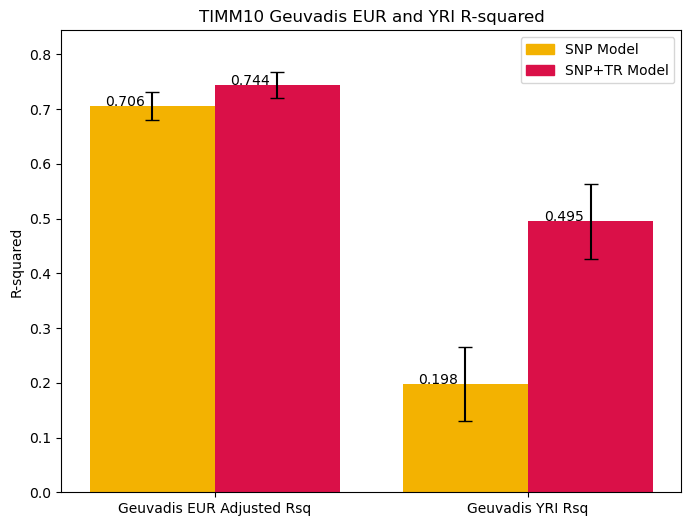

In [9]:
%matplotlib inline

######### copied code to update ##########
def load_model(model_file):
    with open(model_file, 'rb') as f:
        model = pickle.load(f)
    return model

def rsq_confidence_interval(model, r2, n=359):
    p = np.sum(model.coef_ > 1e-8)

    # 95% Confidence Interval
    CI_95 = np.sqrt(4*r2*((1-r2)**2)*((n-p-1)**2)/((n**2-1)*(n+3)))
    return CI_95

def geuv_afr_eur_barplot(
    eur_snp_rsq,
    eur_snp_tr_rsq,
    afr_snp_rsq,
    afr_snp_tr_rsq,
    gene,
    rsq_err,
    ax=None,
):
    old_ax = ax
    if ax == None:
        fig = plt.figure(figsize=(8,6))
        ax = fig.add_subplot(1,1,1)
    
    ax.set_title(f"{gene} Geuvadis EUR and YRI R-squared")
    ax.set_ylabel('R-squared')

    rsq_vals = [
        eur_snp_rsq,
        eur_snp_tr_rsq,
        afr_snp_rsq,
        afr_snp_tr_rsq,
    ]

    # Plot confidence intervals
    snp_boxes = ax.bar(
        [1,1.80,3,3.80],
        rsq_vals,
        yerr=rsq_err,
        color=[snp_model_color, snp_tr_model_color, snp_model_color, snp_tr_model_color],
        capsize=5,
    )
    ax.annotate(eur_snp_rsq, (0.7, eur_snp_rsq))
    ax.annotate(eur_snp_tr_rsq, (1.5, eur_snp_tr_rsq))
    ax.annotate(afr_snp_rsq, (2.7, afr_snp_rsq))
    ax.annotate(afr_snp_tr_rsq, (3.5, afr_snp_tr_rsq))

    handles = [
        mpatches.Patch(color=snp_model_color, label='SNP Model'),
        mpatches.Patch(color=snp_tr_model_color, label='SNP+TR Model')
    ]
    ax.legend(handles=handles)
    ax.set_ylim(0,np.max([eur_snp_rsq, eur_snp_tr_rsq, afr_snp_rsq, afr_snp_tr_rsq])+0.1)
    ax.set_xticks(
        [1.4,3.4], 
        ["Geuvadis EUR Adjusted Rsq", "Geuvadis YRI Rsq"],
        ha='center'
    )
    if old_ax == None:
        fig.savefig(f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/{gene}_rsq_model_comparison_bar_plot.pdf", bbox_inches='tight')
        fig.show()

def create_geuv_afr_eur_gene_barplot(
    gene,
    gene_id,
    geuv_df,
    ax = None,
):
    # Collect R-squared info
    geuvadis_eur_snp_rsq = geuv_df['EUR_SNP_adj_R_sq_Mean'].values[0]
    geuvadis_eur_snp_tr_rsq = geuv_df['EUR_SNP_STR_adj_R_sq_Mean'].values[0]
    geuvadis_afr_snp_rsq = geuv_df['AFR_SNP_R_sq'].values[0]
    geuvadis_afr_snp_tr_rsq = geuv_df['AFR_SNP_STR_R_sq'].values[0]

    # Load snp and snp_tr model with gene_id
    snp_model = load_model(f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs.pkl")
    snp_tr_model = load_model(f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs+STRs.pkl")

    # Grab 95% CI
    geuv_eur_snp_CI = round(rsq_confidence_interval(snp_model, geuvadis_eur_snp_rsq, n=359), 3)
    geuv_eur_snp_tr_CI = round(rsq_confidence_interval(snp_tr_model, geuvadis_eur_snp_tr_rsq, n=359), 3)
    geuv_afr_snp_CI = round(rsq_confidence_interval(snp_model, geuvadis_afr_snp_rsq, n=89), 3)
    geuv_afr_snp_tr_CI = round(rsq_confidence_interval(snp_tr_model, geuvadis_afr_snp_tr_rsq, n=89), 3)

    # Final rsq error collected
    rsq_error = [geuv_eur_snp_CI, geuv_eur_snp_tr_CI, geuv_afr_snp_CI, geuv_afr_snp_tr_CI]

    # Plot results
    geuv_afr_eur_barplot(
        round(geuvadis_eur_snp_rsq, 3),
        round(geuvadis_eur_snp_tr_rsq, 3),
        round(geuvadis_afr_snp_rsq, 3),
        round(geuvadis_afr_snp_tr_rsq, 3),
        gene,
        rsq_error,
        ax,
    )
    return

gene_vals = trained_rsq_df[trained_rsq_df['gene_name'] == 'TIMM10']

create_geuv_afr_eur_gene_barplot(
    gene_vals['gene_name'].values[0],
    gene_vals['gene'].values[0],
    gene_vals,
    ax = None,
)

/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Lasso from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


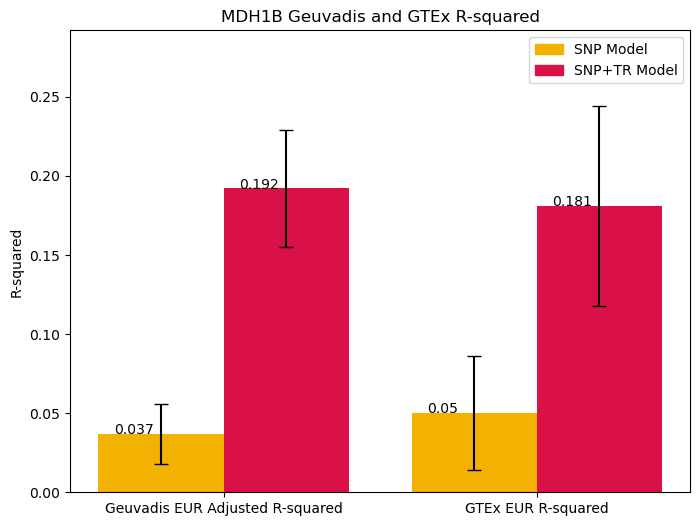

In [7]:
%matplotlib inline

#### Barplot to compare Geuvadis and GTEx R-squared Values ####

def load_model(model_file):
    with open(model_file, 'rb') as f:
        model = pickle.load(f)
    return model

def rsq_confidence_interval(model, r2, n=359):
    p = np.sum(model.coef_ > 1e-8)

    # 95% Confidence Interval
    CI_95 = np.sqrt(4*r2*((1-r2)**2)*((n-p-1)**2)/((n**2-1)*(n+3)))
    return CI_95

def geuv_gtex_top_gene_barplot(
    geuvadis_snp_rsq,
    geuvadis_snp_tr_rsq,
    gtex_snp_rsq,
    gtex_snp_tr_rsq,
    gene,
    rsq_err,
    ax=None,
):
    old_ax = ax
    if ax == None:
        fig = plt.figure(figsize=(8,6))
        ax = fig.add_subplot(1,1,1)
    ax.set_title(f"{gene} Geuvadis and GTEx R-squared")
    ax.set_ylabel('R-squared')

    rsq_vals = [
        geuvadis_snp_rsq,
        geuvadis_snp_tr_rsq,
        gtex_snp_rsq,
        gtex_snp_tr_rsq,
    ]

    # Plot confidence intervals
    snp_boxes = ax.bar(
        [1,1.80,3,3.80],
        rsq_vals,
        yerr=rsq_err,
        color=[snp_model_color, snp_tr_model_color, snp_model_color, snp_tr_model_color],
        capsize=5,
    )
    ax.annotate(geuvadis_snp_rsq, (0.7, geuvadis_snp_rsq))
    ax.annotate(geuvadis_snp_tr_rsq, (1.5, geuvadis_snp_tr_rsq))
    ax.annotate(gtex_snp_rsq, (2.7, gtex_snp_rsq))
    ax.annotate(gtex_snp_tr_rsq, (3.5, gtex_snp_tr_rsq))

    handles = [
        mpatches.Patch(color=snp_model_color, label='SNP Model'),
        mpatches.Patch(color=snp_tr_model_color, label='SNP+TR Model')
    ]
    ax.legend(handles=handles)
    ax.set_ylim(0,np.max([geuvadis_snp_rsq, geuvadis_snp_tr_rsq, gtex_snp_rsq, gtex_snp_tr_rsq])+0.1)
    ax.set_xticks(
        [1.4,3.4], 
        ["Geuvadis EUR Adjusted R-squared", "GTEx EUR R-squared"],
        ha='center'
    )
    if old_ax == None:
        fig.savefig(f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/{gene}_rsq_model_GTEx_Geuvadis_bar_plot.pdf", bbox_inches='tight')
        fig.show()

# MDH1B Barplot (All EUR data)
def create_geuv_gtex_gene_barplot(
    gene,
    gene_id,
    geuv_df,
    gtex_df,
    ax = None,
):
    # Collect R-squared info
    geuvadis_snp_rsq = geuv_df['EUR_SNP_adj_R_sq_Mean'].values[0]
    geuvadis_snp_tr_rsq = geuv_df['EUR_SNP_STR_adj_R_sq_Mean'].values[0]
    gtex_snp_rsq = gtex_df['eur_sample_snp_r2'].values[0]
    gtex_snp_tr_rsq = gtex_df['eur_sample_snp_tr_r2'].values[0]

    # Collect Pre-computed GTEx CI values
    gtex_snp_CI = round(gtex_df['eur_snp_CI'].values[0], 3)
    gtex_snp_tr_CI = round(gtex_df['eur_snp_tr_CI'].values[0], 3)

    # Load snp and snp_tr model with gene_id
    snp_model = load_model(f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs.pkl")
    snp_tr_model = load_model(f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs+STRs.pkl")

    # Grab 95% CI
    geuv_snp_CI = round(rsq_confidence_interval(snp_model, geuvadis_snp_rsq, n=359), 3)
    geuv_snp_tr_CI = round(rsq_confidence_interval(snp_tr_model, geuvadis_snp_tr_rsq, n=359), 3)

    # Final rsq error collected
    rsq_error = [geuv_snp_CI, geuv_snp_tr_CI, gtex_snp_CI, gtex_snp_tr_CI]

    # Plot results
    geuv_gtex_top_gene_barplot(
        round(geuvadis_snp_rsq, 3),
        round(geuvadis_snp_tr_rsq, 3),
        round(gtex_snp_rsq, 3),
        round(gtex_snp_tr_rsq, 3),
        gene,
        rsq_error,
        ax,
    )
    return

# Load GTEx dataframe
gtex_rsq_df = pd.read_csv(
    "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/final_results/GTEx_predicted_results.txt", 
    delimiter='\t', 
    usecols=[
        'gene_name',
        'gene_id',
        'eur_sample_snp_r2',
        'eur_snp_CI',
        'eur_sample_snp_tr_r2',
        'eur_snp_tr_CI',
    ]
)

# MDH1B Example
gene = "MDH1B"
geuv_gene_df = trained_rsq_df[trained_rsq_df['gene_name'] == gene]
gtex_gene_df = gtex_rsq_df[gtex_rsq_df['gene_name'] == gene]
gene_id=geuv_gene_df['gene'].values[0]

create_geuv_gtex_gene_barplot(
    gene,
    gene_id,
    geuv_gene_df,
    gtex_gene_df,
)

Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Lasso from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading the

'\nfor gene, ax in zip(gene_names, flat_axs):\n    geuv_gene_df = trained_rsq_df[trained_rsq_df[\'gene_name\'] == gene]\n    gtex_gene_df = gtex_rsq_df[gtex_rsq_df[\'gene_name\'] == gene]\n    gene_id=geuv_gene_df[\'gene\'].values[0]\n\n    create_geuv_gtex_gene_barplot(\n        gene,\n        gene_id,\n        geuv_gene_df,\n        gtex_gene_df,\n        ax\n    )\n    handles, labels = ax.get_legend_handles_labels()\n    ax.set_ylabel(\'\')\n    ax.get_legend().remove()\n    ax.set_title(f"{gene}")\n    ax.set_xticklabels([\'Geuvadis EUR Adj R-sq\', \'GTEx EUR R-sq\'], rotation=45, ha=\'right\')\n\naxs[0,0].set_ylabel(\'R-squared\')\naxs[1,0].set_ylabel(\'R-squared\')\naxs[2,0].set_ylabel(\'R-squared\')\n\nhandles = [\n    mpatches.Patch(color=snp_model_color, label=\'SNP Model\'),\n    mpatches.Patch(color=snp_tr_model_color, label=\'SNP+TR Model\')\n]\nlabels=[\'SNP Model\', \'SNP+TR Model\']\n\nfig.legend(\n    handles, \n    labels,\n    loc="upper right", \n    bbox_to_anchor=

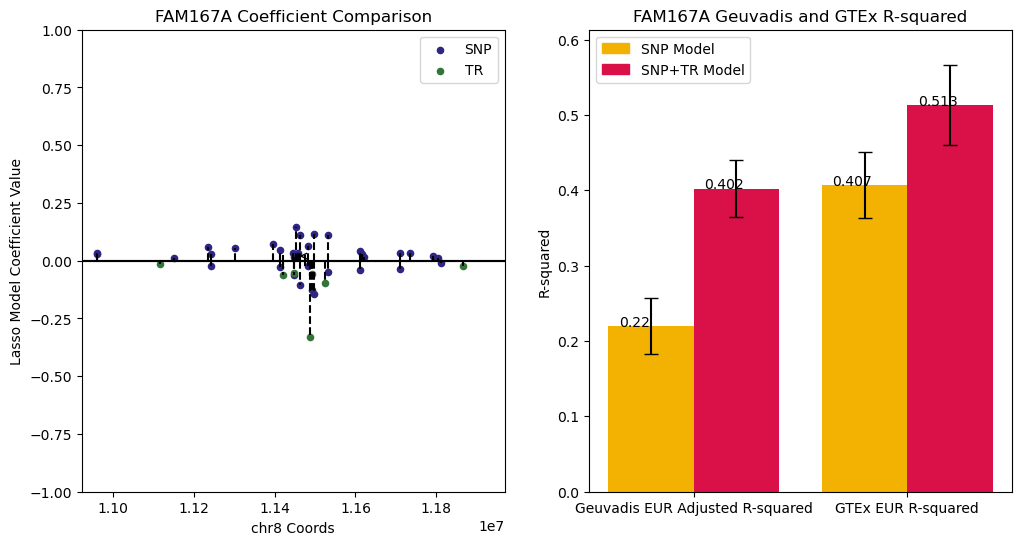

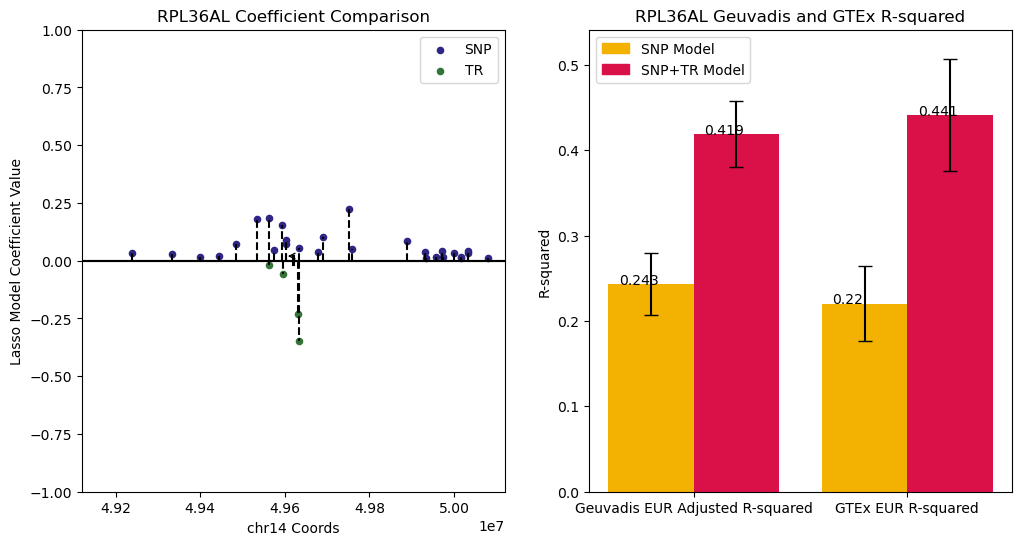

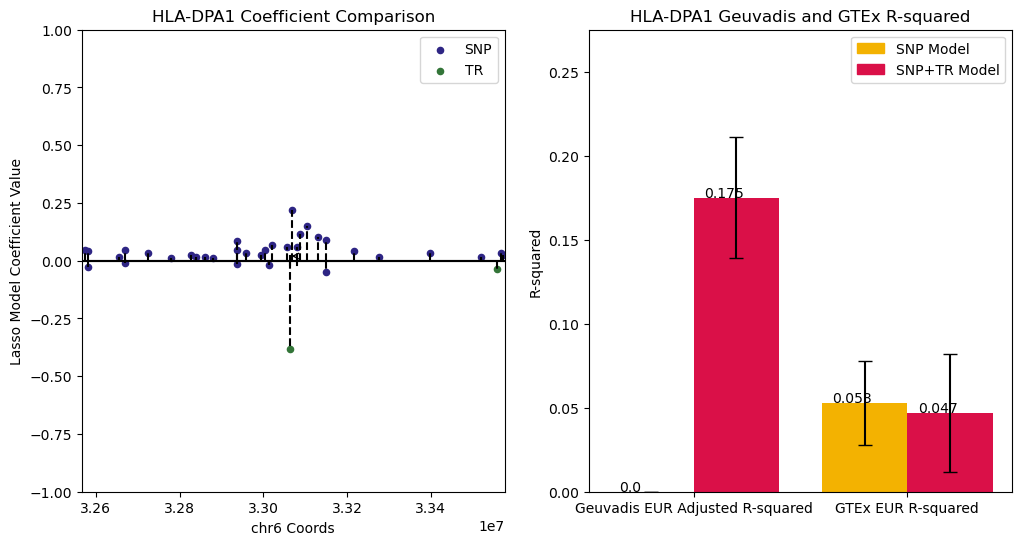

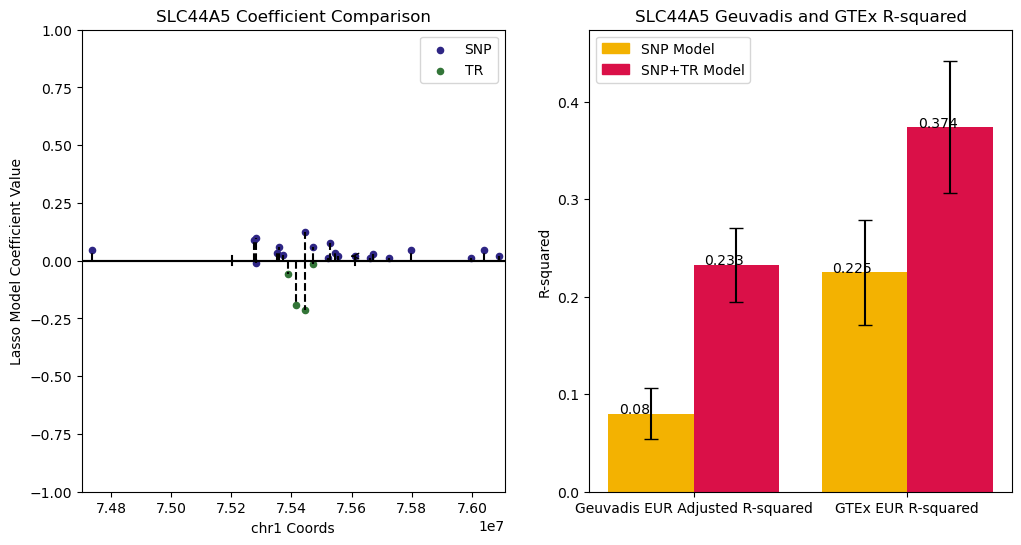

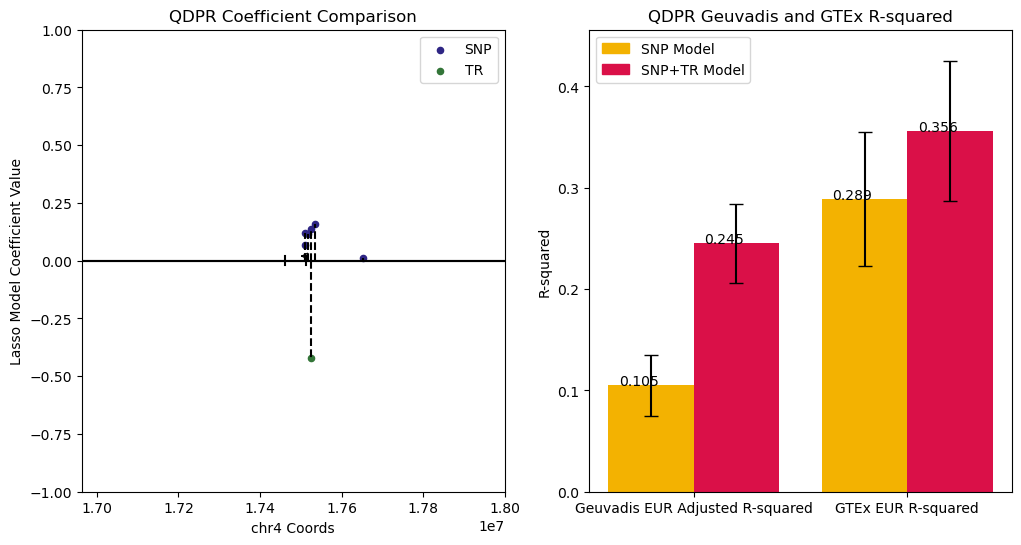

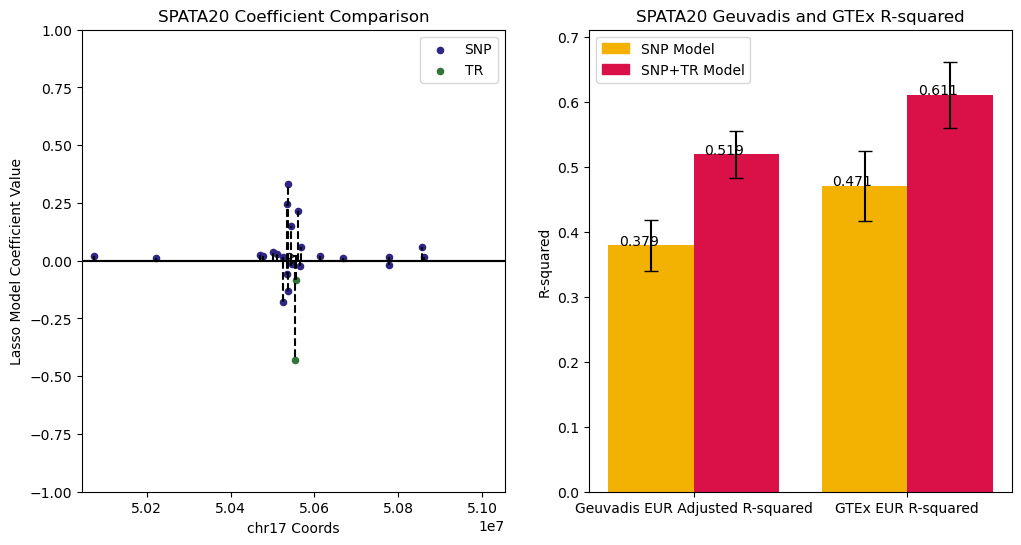

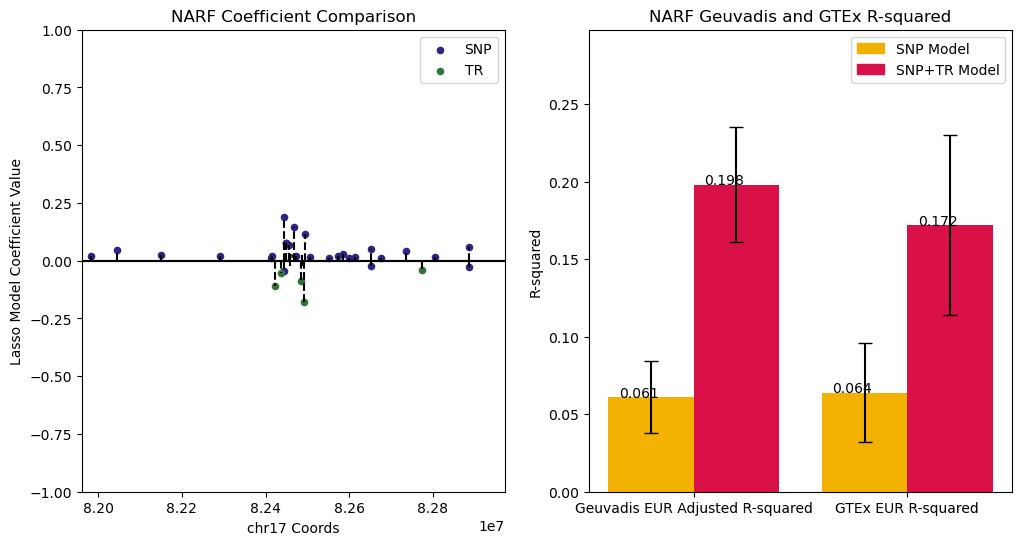

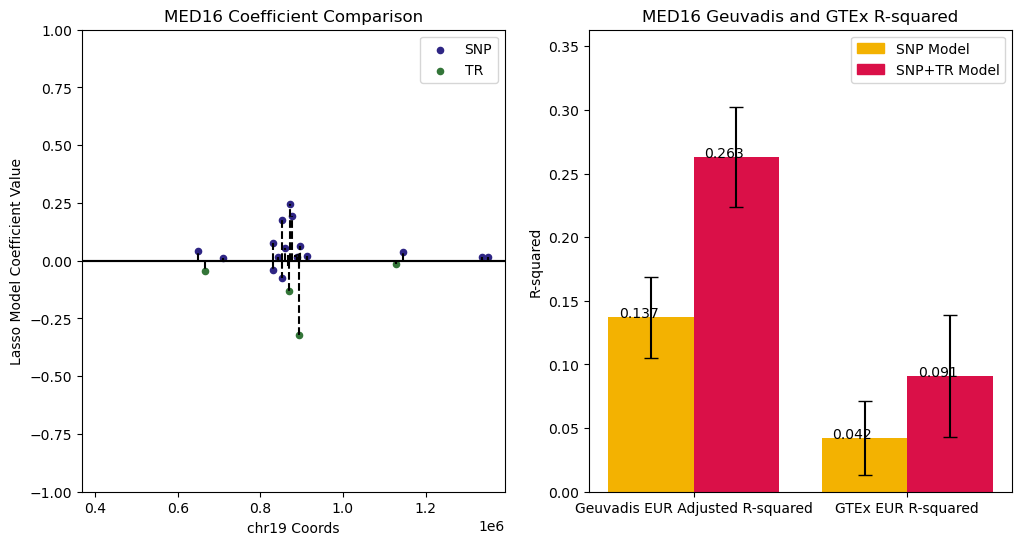

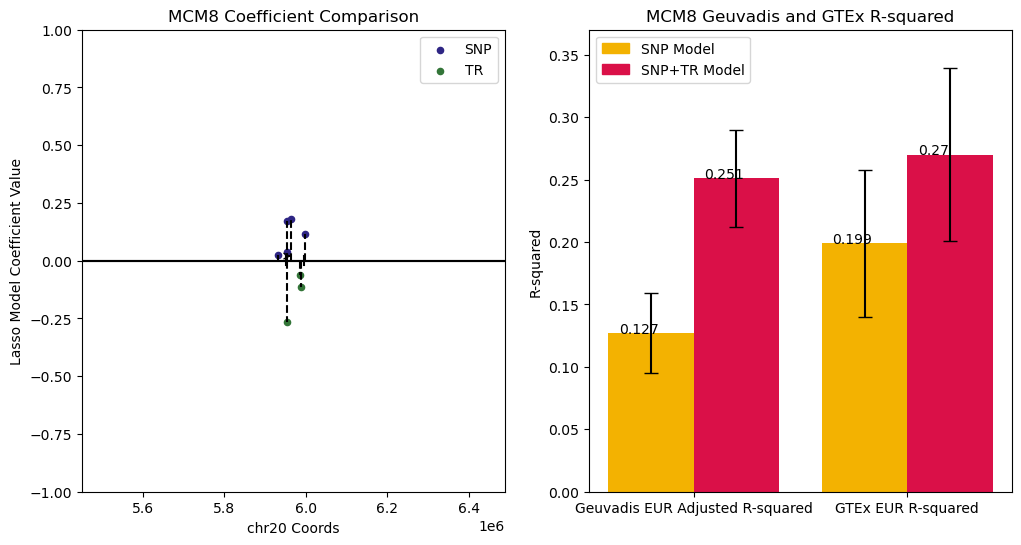

In [23]:
#### Barplots for the Top 10 adj EUR gain Genes ####

def plot_stick_and_bar(
    gene, 
    gene_id,
    geuv_gene_df,
    gtex_gene_df,
    #output
):
    fig, axs = plt.subplots(1, 2, sharey=False, width_ratios=[1,1])
    fig.set_figheight(6)
    fig.set_figwidth(12)
    
    # Ball and stick
    ball_and_stick(gene_id, gene, axs[0])

    # Barplot
    create_geuv_gtex_gene_barplot(
        gene,
        gene_id,
        geuv_gene_df,
        gtex_gene_df,
        axs[1]
    )


    #fig.savefig(output)
    fig.show()
    return

# TODO plot each with ball and stick next to it
# TODO update so ball and stick with each barplot (ball and stick on the left)
gene_names = ["FAM167A", "RPL36AL", "HLA-DPA1", "SLC44A5", "QDPR", "SPATA20", "NARF", "MED16", "MCM8"]

for gene in gene_names:
    geuv_gene_df = trained_rsq_df[trained_rsq_df['gene_name'] == gene]
    gtex_gene_df = gtex_rsq_df[gtex_rsq_df['gene_name'] == gene]
    gene_id=geuv_gene_df['gene'].values[0]
    plot_stick_and_bar(
        gene, 
        gene_id,
        geuv_gene_df,
        gtex_gene_df,
    )

"""
for gene, ax in zip(gene_names, flat_axs):
    geuv_gene_df = trained_rsq_df[trained_rsq_df['gene_name'] == gene]
    gtex_gene_df = gtex_rsq_df[gtex_rsq_df['gene_name'] == gene]
    gene_id=geuv_gene_df['gene'].values[0]

    create_geuv_gtex_gene_barplot(
        gene,
        gene_id,
        geuv_gene_df,
        gtex_gene_df,
        ax
    )
    handles, labels = ax.get_legend_handles_labels()
    ax.set_ylabel('')
    ax.get_legend().remove()
    ax.set_title(f"{gene}")
    ax.set_xticklabels(['Geuvadis EUR Adj R-sq', 'GTEx EUR R-sq'], rotation=45, ha='right')

axs[0,0].set_ylabel('R-squared')
axs[1,0].set_ylabel('R-squared')
axs[2,0].set_ylabel('R-squared')

handles = [
    mpatches.Patch(color=snp_model_color, label='SNP Model'),
    mpatches.Patch(color=snp_tr_model_color, label='SNP+TR Model')
]
labels=['SNP Model', 'SNP+TR Model']

fig.legend(
    handles, 
    labels,
    loc="upper right", 
    bbox_to_anchor=(0.98, 0.98)
)
fig.savefig(f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/top_eur_gain_model_GTEx_Geuvadis_bar_plot.pdf", bbox_inches='tight')
fig.show()
"""

[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13
 0.14 0.15 0.16 0.17 0.18 0.19]
EUR
[np.int64(1150), np.int64(501), np.int64(290), np.int64(182), np.int64(126), np.int64(83), np.int64(56), np.int64(37), np.int64(31), np.int64(25), np.int64(21), np.int64(18), np.int64(11), np.int64(8), np.int64(6), np.int64(5), np.int64(3), np.int64(3), np.int64(1), np.int64(0)]
[np.int64(1144), np.int64(498), np.int64(288), np.int64(178), np.int64(118), np.int64(85), np.int64(63), np.int64(38), np.int64(31), np.int64(26), np.int64(21), np.int64(17), np.int64(13), np.int64(9), np.int64(8), np.int64(4), np.int64(3), np.int64(3), np.int64(0), np.int64(0)]
AFR
[np.int64(1281), np.int64(487), np.int64(294), np.int64(196), np.int64(149), np.int64(119), np.int64(98), np.int64(72), np.int64(58), np.int64(48), np.int64(41), np.int64(39), np.int64(34), np.int64(32), np.int64(25), np.int64(22), np.int64(21), np.int64(19), np.int64(15), np.int64(13)]
[np.int64(1295), np.int64(479), np.int64(

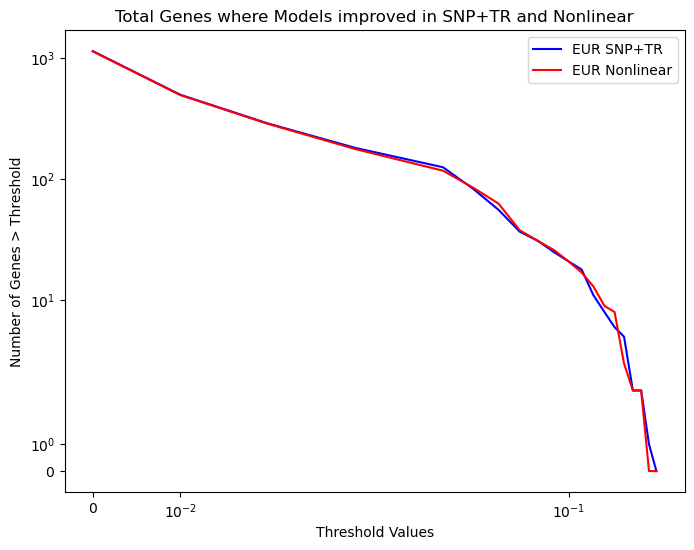

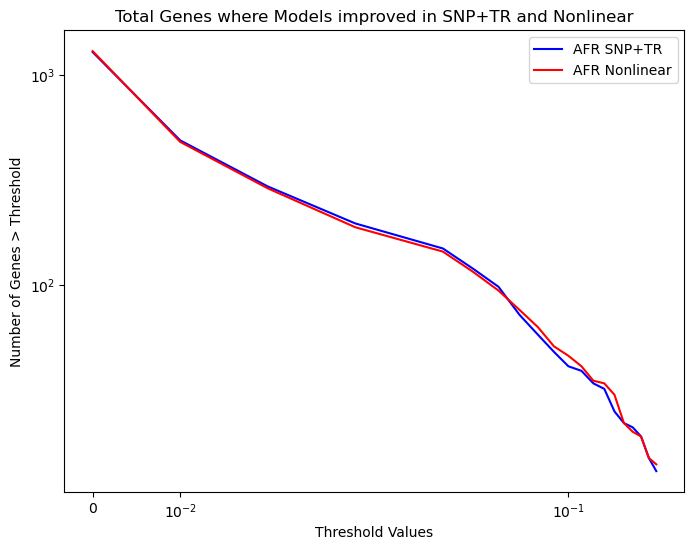

In [30]:
%matplotlib inline

# Make plot where compare the improvement of SNP+TR and nonlinear models in EUR data and AFR data
# Y-axis number of genes > threshold, x-axis Threshold
# TODO AFR data currently have EUR
thresholds = np.arange(0, 0.2, 0.01)
snp_tr_num_genes = []
nonlinear_num_genes = []
afr_snp_tr_num_genes = []
afr_nonlinear_num_genes = []
for thresh in thresholds:
    snp_tr_num_genes.append(np.sum(trained_rsq_df['adj_rsq_diff'] > thresh))
    nonlinear_num_genes.append(np.sum(trained_rsq_df['nonlin_adj_rsq_snp_diff'] > thresh))

    afr_snp_tr_num_genes.append(np.sum(trained_rsq_df['afr_rsq_diff'] > thresh))
    afr_nonlinear_num_genes.append(np.sum(trained_rsq_df['afr_nonlin_rsq_snp_diff'] > thresh))

print(thresholds)
print("EUR")
print(snp_tr_num_genes)
print(nonlinear_num_genes)
print("AFR")
print(afr_snp_tr_num_genes)
print(afr_nonlinear_num_genes)

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title("Total Genes where Models improved in SNP+TR and Nonlinear")
ax.set_ylabel('Number of Genes > Threshold')
ax.set_xlabel('Threshold Values')

ax.plot(thresholds, snp_tr_num_genes, color='b', label='EUR SNP+TR')
ax.plot(thresholds, nonlinear_num_genes, color='r', label='EUR Nonlinear')
ax.set_xscale('symlog', linthresh=0.04)
ax.set_yscale('symlog', linthresh=5)
#ax.set_xticks(thresholds)
#ax.set_yticks(np.arange(0, 1200, 100))
ax.legend()
fig.show()

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title("Total Genes where Models improved in SNP+TR and Nonlinear")
ax.set_ylabel('Number of Genes > Threshold')
ax.set_xlabel('Threshold Values')

ax.plot(thresholds, afr_snp_tr_num_genes, color='b', label='AFR SNP+TR')
ax.plot(thresholds, afr_nonlinear_num_genes, color='r', label='AFR Nonlinear')
ax.set_xscale('symlog', linthresh=0.04)
ax.set_yscale('symlog', linthresh=5)
#ax.set_xticks(thresholds)
#ax.set_yticks(np.arange(0, 1200, 100))
ax.legend()

fig.show()

### i. Delta R-squared and Delta Heriability Explained Distributions

Distribution mean 0.003733017332807285
Distribution mean 0.017886478471366242


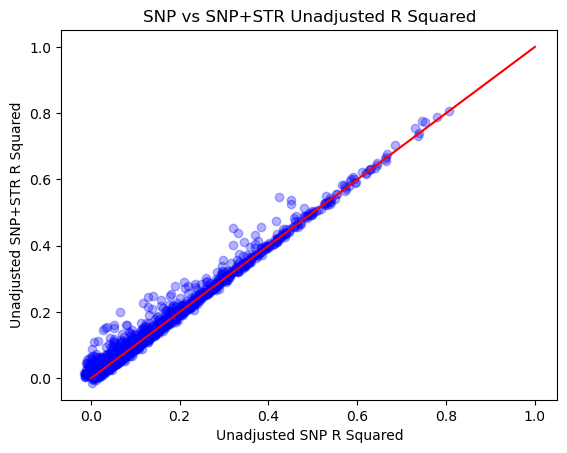

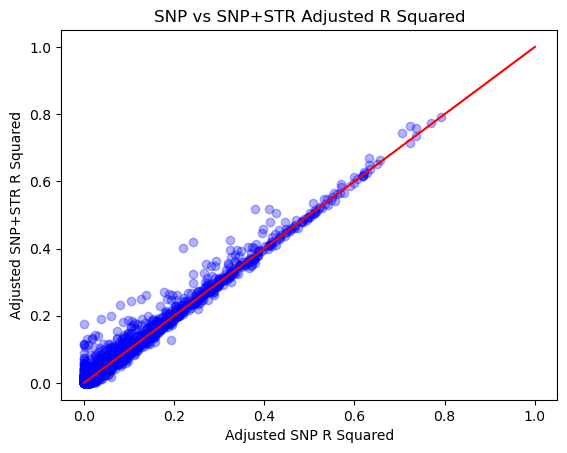

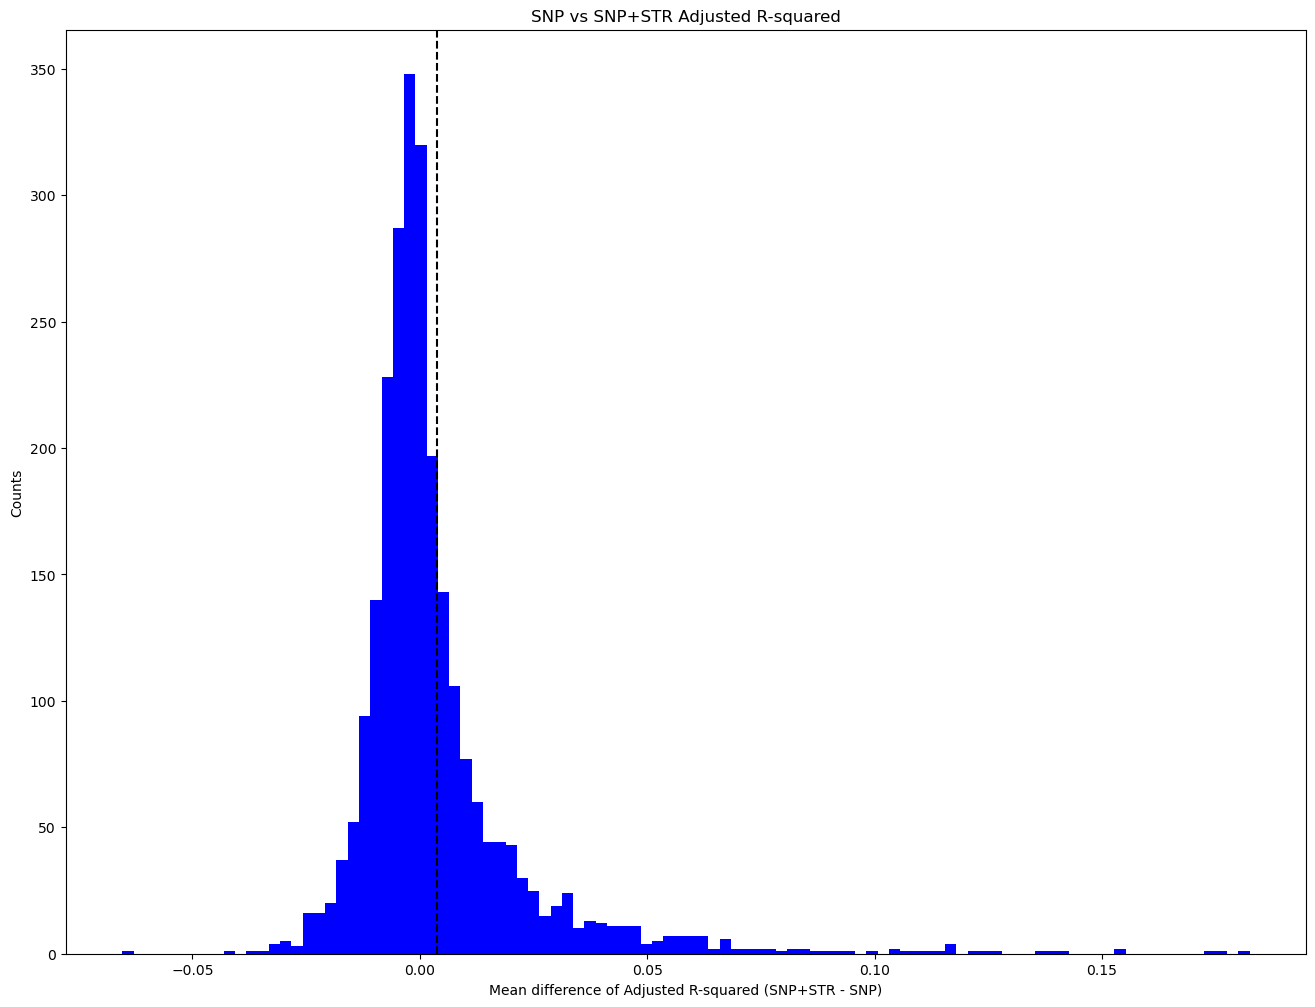

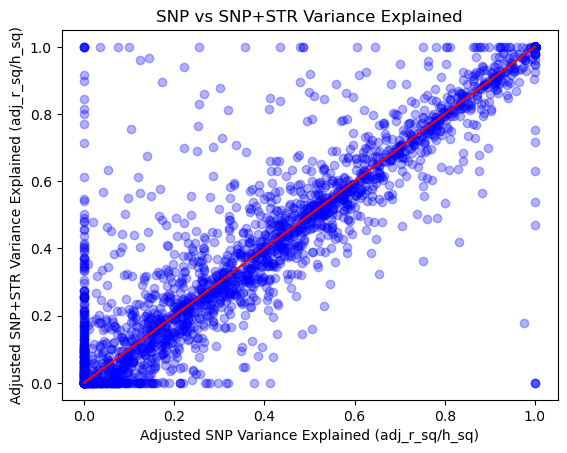

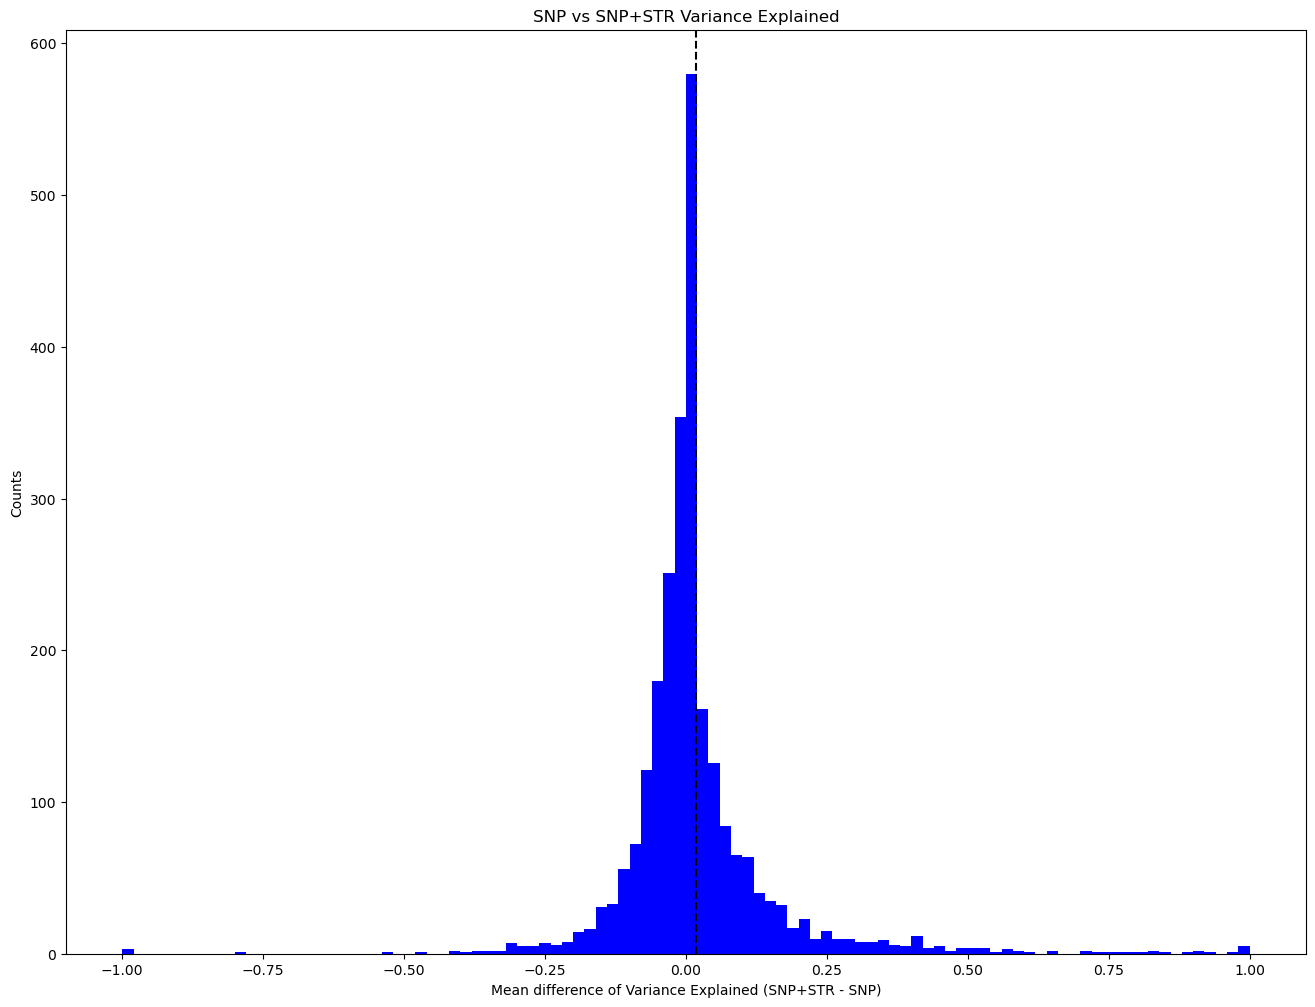

In [62]:
outpath = "/storage/mlamkin/data/GeneExprPredictor/paper_figures/supplementary/" # Use for snorlax
#outpath = "/expanse/projects/gymreklab/mlamkin/GeneExprPredictor_data/paper_figures/"

# Plot SNP vs SNP_STR unadjusted R2 of all heritable models X-axis: SNP, Y-axis:SNP+STR
plot_snp_str_comparison(
    trained_rsq_df['EUR_SNP_R_sq_Mean'], 
    trained_rsq_df['EUR_SNP_STR_R_sq_Mean'], 
    "Unadjusted SNP R Squared", 
    "Unadjusted SNP+STR R Squared", 
    "SNP vs SNP+STR Unadjusted R Squared", 
    outpath + "unadjusted_r2_scatter_trained_genes.png"
) # Unadjusted R2

# Plot SNP vs SNP_STR adjusted R2 of all heritable models X-axis: SNP, Y-axis:SNP+STR 
plot_snp_str_comparison(
    trained_rsq_df['EUR_SNP_adj_R_sq_Mean'], 
    trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'], 
    "Adjusted SNP R Squared",
    "Adjusted SNP+STR R Squared", 
    "SNP vs SNP+STR Adjusted R Squared", 
    outpath + "adjusted_r2_scatter_trained_genes.png"
) # Adjusted R2

# Distribution of r adjusted snp + str vs r adjusted snp
plot_meandiff_dist(
    trained_rsq_df['adj_rsq_diff'], 
    "Mean difference of Adjusted R-squared (SNP+STR - SNP)", 
    "SNP vs SNP+STR Adjusted R-squared",
    outpath + "adjusted_r2_meandiff_dist_trained_genes.png"
)

### Plots for Variance Explained (adj r_squared/heritability) ###

# Plot SNP Model variance explained vs SNP + TR model variance explained
plot_snp_str_comparison(
    create_variance_explained(trained_rsq_df['EUR_SNP_adj_R_sq_Mean']/trained_rsq_df['hsq']), 
    create_variance_explained(trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean']/trained_rsq_df['hsq']), 
    "Adjusted SNP Variance Explained (adj_r_sq/h_sq)",
    "Adjusted SNP+STR Variance Explained (adj_r_sq/h_sq)", 
    "SNP vs SNP+STR Variance Explained", 
    outpath + "var_explained_scatter_trained_genes.png",
) # Adjusted R2

# Variance Explained Distribution
plot_meandiff_dist(
    trained_rsq_df['var_explained'], 
    "Mean difference of Variance Explained (SNP+STR - SNP)", 
    "SNP vs SNP+STR Variance Explained",
    outpath + "var_explained_meandiff_dist_trained_genes.png",
)

### ii. Distribution EUR Adjusted Delta R-squared

Genes with diff > 0: 1150
Genes with diff < 0: 1403


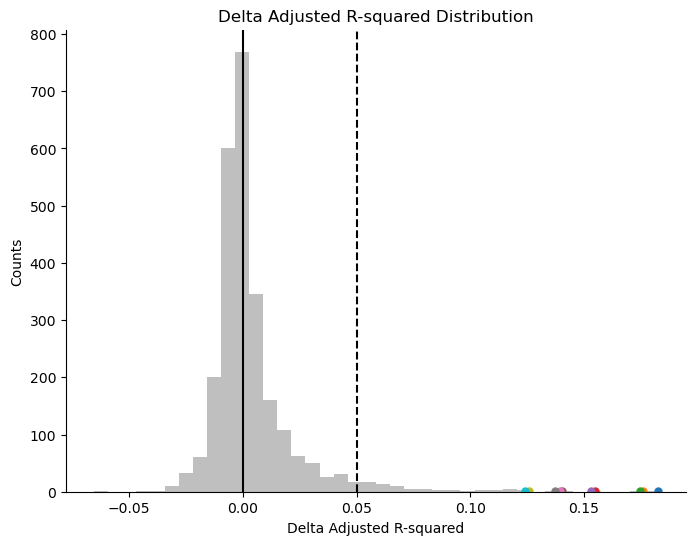

In [8]:
#### Overlayed Distribution #####
%matplotlib inline

# Plot all genes with eSTRs with color
# Note use this color if need an inbetween with nonestr and estr genes (246/256, 164/256, 130/256)
color = (128/256,128/256,128/256)
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title('Delta Adjusted R-squared Distribution')
ax.set_xlabel('Delta Adjusted R-squared')
ax.set_ylabel('Counts')

ax.hist(
    trained_rsq_df['adj_rsq_diff'], 
    bins=40,
    alpha=0.5,
    color=color
)
# Plot threshold line 
ax.axvline(0.05, color='k', linestyle="dashed")

# Plot line at 0 to indicate where SNP+TR did better and SNP only did better
ax.axvline(0, color='k')

# Annotate where MDH1B is
#gene_id = 'ENSG00000138400'
#gene_name = 'MDH1B'
#ax.annotate(gene_name, (trained_rsq_df[trained_rsq_df['gene'] == gene_id]['adj_rsq_diff']-.01, 10), fontsize=8)
#ax.scatter(trained_rsq_df[trained_rsq_df['gene'] == gene_id]['adj_rsq_diff']-.0025,1)
ax.spines[['top', 'right']].set_visible(False)
# Top 10 Genes to annotate
gain_sorted_df = trained_rsq_df.sort_values(by=['adj_rsq_diff'], ascending=False)
top10_gain = gain_sorted_df['gene_name'][:10].values

for gene_ind, gene in enumerate(top10_gain):
    ax.scatter(gain_sorted_df[gain_sorted_df['gene_name'] == gene]['adj_rsq_diff'],2, s=25)
    ax.annotate(gene, (gain_sorted_df[gain_sorted_df['gene_name'] == gene]['adj_rsq_diff']-.03,gene_ind*25+10))

print(f"Genes with diff > 0: {np.sum(trained_rsq_df['adj_rsq_diff'] > 0)}")
print(f"Genes with diff < 0: {np.sum(trained_rsq_df['adj_rsq_diff'] < 0)}")

fig.savefig(f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/delta_rsq_model_comparison_histograms.pdf")
fig.show()

### iii. Distribution EUR H2 Explained

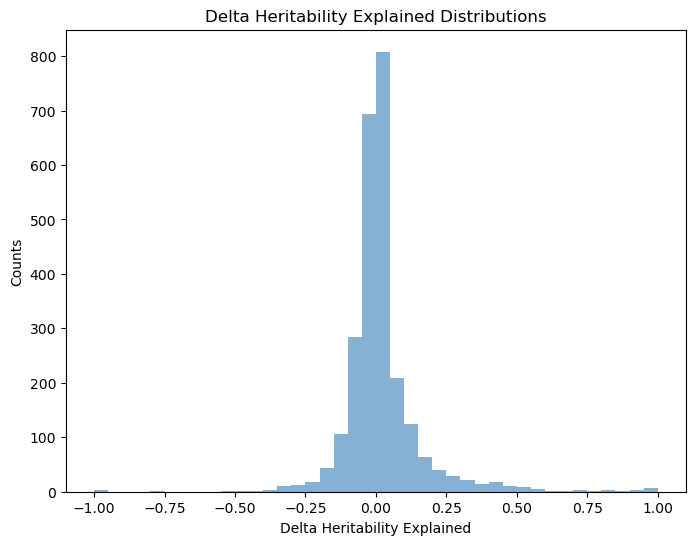

In [27]:
#### Overlayed Distribution #####

# Plot all genes with eSTRs with color
# Note use this color if need an inbetween with nonestr and estr genes (246/256, 164/256, 130/256)
colors = [        
    (179/256, 21/256, 41/256), 
    #(142/256, 196/256, 222/256), Uncomment if we need a third color
    (16/256, 101/256, 171/256),
]
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title('Delta Heritability Explained Distributions')
ax.set_xlabel('Delta Heritability Explained')
ax.set_ylabel('Counts')

ax.hist(
    trained_rsq_df['var_explained'], 
    bins=40,
    alpha=0.5,
    color=colors[1]
)

fig.savefig(f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/heritability_explained_model_comparison_histograms.pdf")
fig.show()

## 3. Genes that significantly improved

### i. European Improvement

In [6]:
# Get genes that improved
improved_genes_df = trained_rsq_df[trained_rsq_df['adj_rsq_diff'] > 0]

### How many genes improved and what were the top genes for SNP vs SNP+STR ###
print(f"Total genes r-sq diff > 0 EUR Adjusted R-squared: {improved_genes_df.shape[0]}")
print("Top differences between adj r-squared of SNP Models and SNP+STRs")
# Sort by delta r-squared and print
sorted_improved_genes_df = improved_genes_df.sort_values(by='adj_rsq_diff', ascending=False)

# Write out all genes sorted by improvement of adj r2 (snp+str - snp)
improved_genes_output = "/storage/mlamkin/data/GeneExprPredictor/paper_figures/EUR_geuvadis_adj_r2_improved_genes.csv"
sorted_improved_genes_df.to_csv(improved_genes_output, index=False, sep=',')

Total genes r-sq diff > 0 EUR Adjusted R-squared: 1150
Top differences between adj r-squared of SNP Models and SNP+STRs


In [65]:
# Output genes that improved for variance explained
# Get genes that improved
improved_genes_df = trained_rsq_df[trained_rsq_df['var_explained'] > 0]

### How many genes improved and what were the top genes for SNP vs SNP+STR ###
print(f"Total genes var explained diff > 0: {improved_genes_df.shape[0]}")
print("Top differences between variance explained of SNP Models and SNP+STRs")
# Sort by delta r-squared and print
sorted_improved_genes_df = improved_genes_df.sort_values(by='var_explained', ascending=False)
print(sorted_improved_genes_df[['gene', 'EUR_SNP_adj_R_sq_Mean', 'EUR_SNP_STR_adj_R_sq_Mean', 'hsq']])

Total genes var explained diff > 0: 1021
Top differences between variance explained of SNP Models and SNP+STRs
                    gene  EUR_SNP_adj_R_sq_Mean  EUR_SNP_STR_adj_R_sq_Mean  \
2690514  ENSG00000141971               0.000000                   0.029617   
1366776  ENSG00000171097               0.000000                   0.003325   
1346485  ENSG00000119403               0.000000                   0.008828   
1669021  ENSG00000110395               0.000000                   0.011049   
202087   ENSG00000143375               0.000000                   0.067356   
...                  ...                    ...                        ...   
2784243  ENSG00000248098               0.151514                   0.151695   
329755   ENSG00000115750               0.100289                   0.100408   
1809736  ENSG00000111666               0.325993                   0.326026   
2510557  ENSG00000141391               0.071083                   0.071085   
1915778  ENSG00000181803       

### ii. Cross Population Improvement (EUR Trained AFR predicted)

In [9]:
#### Genes where the models performed better in African samples than European Samples ####
trained_rsq_df.loc[trained_rsq_df['AFR_SNP_R_sq'] < 0, 'AFR_SNP_R_sq'] = 0
trained_rsq_df.loc[trained_rsq_df['AFR_SNP_STR_R_sq'] < 0, 'AFR_SNP_STR_R_sq'] = 0
eur_max = trained_rsq_df[['EUR_SNP_adj_R_sq_Mean', 'EUR_SNP_STR_adj_R_sq_Mean']].max(axis=1)
afr_better_genes_df = trained_rsq_df[(trained_rsq_df['AFR_SNP_R_sq'] > eur_max) | (trained_rsq_df['AFR_SNP_STR_R_sq'] > eur_max)]

### How many genes improved and what were the top genes for SNP vs SNP+STR ###
print(f"Total genes AFR r-sq (either SNP or SNP+TR) > EUR : {afr_better_genes_df.shape[0]}")
# Sort by delta r-squared and print

# Output how many had AFR SNP+TR greater than all other pop/model pairs
afr_snp_tr_best = trained_rsq_df[(trained_rsq_df['AFR_SNP_STR_R_sq'] > eur_max) & (trained_rsq_df['AFR_SNP_STR_R_sq'] > trained_rsq_df['AFR_SNP_R_sq'])]
print(f"Total genes AFR SNP+TR R-sq best: {afr_snp_tr_best.shape[0]}")

# Write out all genes sorted by improvement of adj r2 (snp+str - snp)
#improved_genes_output = "/storage/mlamkin/data/GeneExprPredictor/paper_figures/AFR_better_than_EUR_geuvadis_adj_r2_improved_genes.csv"
#afr_better_genes_df.to_csv(improved_genes_output, index=False, sep=',')

Total genes AFR r-sq (either SNP or SNP+TR) > EUR : 888
Total genes AFR SNP+TR R-sq best: 455


0.5789009833411232
2.1844991015429324e-228
0.5829590103838269
2.4781271979465344e-232
(2553, 32)
Number below diagonal 1639


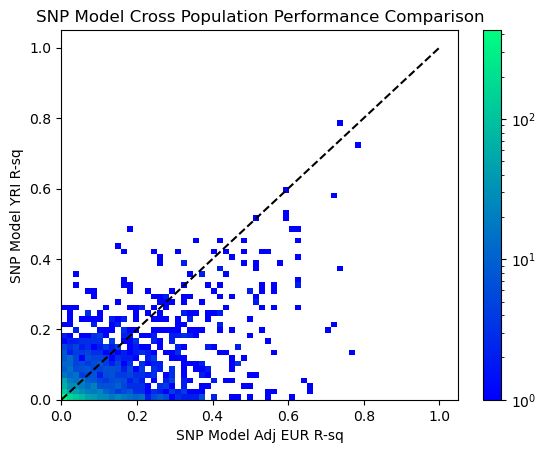

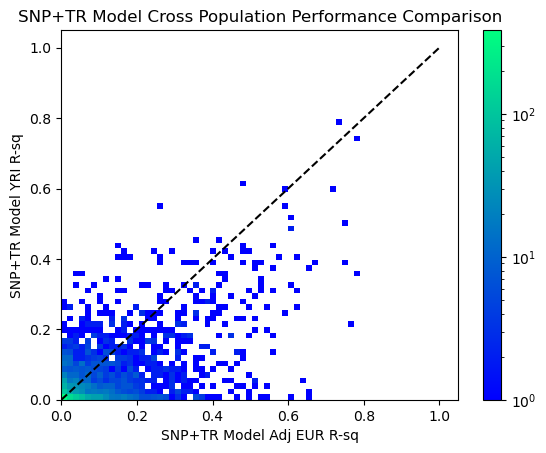

In [4]:
### Show how AFR models performed worse overall on EUR trained by plotting scatter of SNP trained EUR vs AFR and SNP+TR trained EUR vs AFR
%matplotlib inline

fig = plt.figure()
ax = fig.add_subplot(1,1,1)
ax.set_title("SNP Model Cross Population Performance Comparison")
ax.set_xlabel("SNP Model Adj EUR R-sq")
ax.set_ylabel("SNP Model YRI R-sq")
print(stats.pearsonr(trained_rsq_df['EUR_SNP_adj_R_sq_Mean'],trained_rsq_df['AFR_SNP_R_sq']).statistic)
print(stats.pearsonr(trained_rsq_df['EUR_SNP_adj_R_sq_Mean'],trained_rsq_df['AFR_SNP_R_sq']).pvalue)
heatmap, xedges, yedges = np.histogram2d(
    trained_rsq_df['EUR_SNP_adj_R_sq_Mean'], 
    trained_rsq_df['AFR_SNP_R_sq'],
    bins=50
)
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
im = ax.imshow(
    heatmap.T,
    norm="log",
    extent=extent, 
    origin='lower',
    cmap=cm.winter,
    aspect='auto'
)
ax.plot([0,1], [0,1], linestyle='dashed', color='black')
plt.colorbar(im, ax=ax)
#ax.scatter(estr_rsq_h2_df['EUR_SNP_R_sq_Mean'], estr_rsq_h2_df['AFR_SNP_R_sq'], color='blue')
fig.show()

fig = plt.figure()
ax = fig.add_subplot(1,1,1)
ax.set_title("SNP+TR Model Cross Population Performance Comparison")
ax.set_xlabel("SNP+TR Model Adj EUR R-sq")
ax.set_ylabel("SNP+TR Model YRI R-sq")
#ax.plot([0,1], [0,1], color='black')
#ax.scatter(estr_rsq_h2_df['EUR_SNP_STR_R_sq_Mean'], estr_rsq_h2_df['AFR_SNP_STR_R_sq'], color='blue')
print(stats.pearsonr(trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'],trained_rsq_df['AFR_SNP_STR_R_sq']).statistic)
print(stats.pearsonr(trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'],trained_rsq_df['AFR_SNP_STR_R_sq']).pvalue)
nonzero_rsq_df = trained_rsq_df[trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] > 0]
print(trained_rsq_df.shape)
num_below = np.sum(((nonzero_rsq_df['AFR_SNP_STR_R_sq']/nonzero_rsq_df['EUR_SNP_STR_adj_R_sq_Mean']) < 1))
print(f"Number below diagonal {num_below}")
heatmap, xedges, yedges = np.histogram2d(
    trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'], 
    trained_rsq_df['AFR_SNP_STR_R_sq'],
    bins=50
)
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
im = ax.imshow(
    heatmap.T,
    norm="log",
    extent=extent, 
    origin='lower',
    cmap=cm.winter,
    aspect='auto'
)
plt.colorbar(im, ax=ax)
ax.plot([0,1], [0,1], linestyle='dashed', color='black')
fig.show()

In [11]:
# Total genes
total_genes = trained_rsq_df['EUR_SNP_adj_R_sq_Mean'].shape[0]

# What percent of points lie below the x=y line on the above plots
snp_below_line = np.sum((trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] - trained_rsq_df['AFR_SNP_R_sq']) > 0)
snp_pct_below_line = snp_below_line / total_genes * 100

snp_tr_below_line = np.sum((trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] - trained_rsq_df['AFR_SNP_STR_R_sq']) > 0)
snp_tr_pct_below_line = snp_tr_below_line / total_genes* 100

# How many models where both EUR and AFR had 0 and one had 0 in SNP (raw number and percentage)
snp_both_zero = np.sum((trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] == 0) & (trained_rsq_df['AFR_SNP_R_sq'] == 0))
snp_EUR_zero = np.sum((trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] == 0) & (trained_rsq_df['AFR_SNP_R_sq'] != 0))
snp_AFR_zero = np.sum((trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] != 0) & (trained_rsq_df['AFR_SNP_R_sq'] == 0))

snp_tr_both_zero = np.sum((trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] == 0) & (trained_rsq_df['AFR_SNP_STR_R_sq'] == 0))
snp_tr_EUR_zero = np.sum((trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] == 0) & (trained_rsq_df['AFR_SNP_STR_R_sq'] != 0))
snp_tr_AFR_zero = np.sum((trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] != 0) & (trained_rsq_df['AFR_SNP_STR_R_sq'] == 0))

# Output results
print("SNP Models")
print(f"Percentage of genes where EUR rsq > AFR rsq: {snp_pct_below_line:.2f}%")
print(f"Genes where the R-squared was zero in both EUR and AFR {snp_both_zero}/{snp_both_zero/total_genes*100:.2f}%")
print(f"Genes where the R-squared was zero in only EUR {snp_EUR_zero}/{snp_EUR_zero/total_genes*100:.2f}%")
print(f"Models where the R-squared was zero in only AFR {snp_AFR_zero}/{snp_AFR_zero/total_genes*100:.2f}%")


print("SNP+TR Models")
print(f"Percentage of genes where EUR rsq > AFR rsq: {snp_tr_pct_below_line:.2f}%")
print(f"Genes where the R-squared was zero in both EUR and AFR {snp_tr_both_zero}/{snp_tr_both_zero/total_genes*100:.2f}%")
print(f"Genes where the R-squared was zero in only EUR {snp_tr_EUR_zero}/{snp_tr_EUR_zero/total_genes*100:.2f}%")
print(f"Models where the R-squared was zero in only AFR {snp_tr_AFR_zero}/{snp_tr_AFR_zero/total_genes*100:.2f}%")

SNP Models
Percentage of genes where EUR rsq > AFR rsq: 63.57%
Genes where the R-squared was zero in both EUR and AFR 4/0.16%
Genes where the R-squared was zero in only EUR 199/7.79%
Models where the R-squared was zero in only AFR 2/0.08%
SNP+TR Models
Percentage of genes where EUR rsq > AFR rsq: 65.18%
Genes where the R-squared was zero in both EUR and AFR 0/0.00%
Genes where the R-squared was zero in only EUR 145/5.68%
Models where the R-squared was zero in only AFR 2/0.08%


/storage/mlamkin/tmp/ipykernel_31884/1485927236.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trained_rsq_df['adj_EUR_gain'] = trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] - trained_rsq_df['EUR_SNP_adj_R_sq_Mean']
/storage/mlamkin/tmp/ipykernel_31884/1485927236.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trained_rsq_df['adj_AFR_gain'] = trained_rsq_df['AFR_SNP_STR_adj_R_sq'] - trained_rsq_df['AFR_SNP_adj_R_sq']
/storage/mlamkin/tmp/ipykernel_31884/1485927236.py:7: SettingWithCopyWarning: 
A val

Gain plot
Pearson R: 0.22854176449419653
Pearson R pval: 1.319421060533582e-31
Gain Distribution (AFR - Adj EUR)
(2553, 37)
n > 0: 1461
n < 0: 1092
Median AFR - EUR Gain: 0.0017074083051147994


/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/matplotlib/text.py:1475: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  x = float(self.convert_xunits(x))
/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/matplotlib/text.py:762: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  posx = float(self.convert_xunits(x))
/storage/mlamkin/tmp/ipykernel_31884/1485927236.py:82: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trained_rsq_df['Delta_gain'] = trained_rsq_df['AFR_gain'] - trained_rsq_df['EUR_gain']


Gain Distribution (AFR - EUR)
(2553, 37)
n > 0: 1457
n < 0: 1096


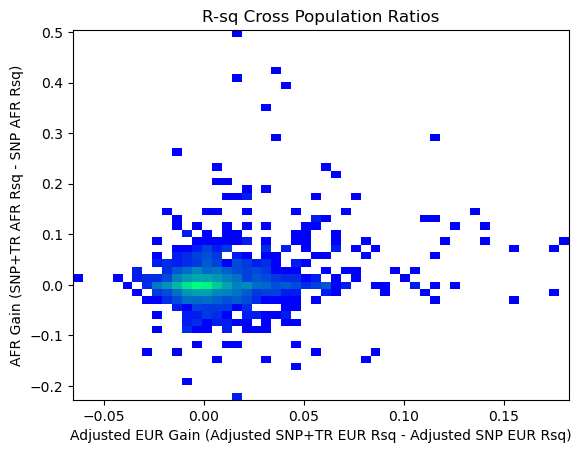

/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/matplotlib/text.py:905: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  x = float(self.convert_xunits(self._x))


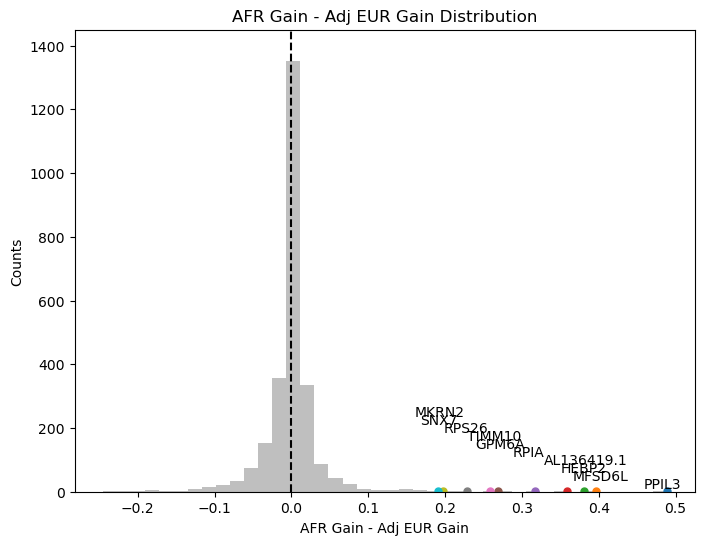

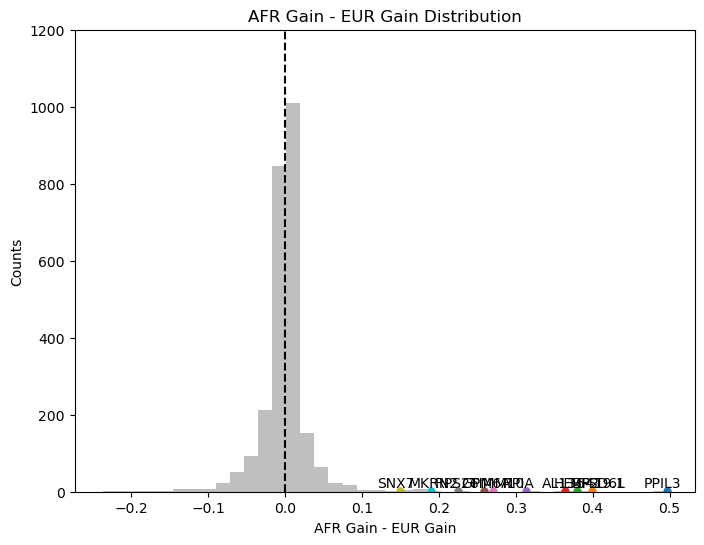

In [6]:
### Scatter plot of ratio between AFR SNP/EUR SNP r2 and AFR SNP+TR/EUR SNP+TR
%matplotlib inline

# Make table of data used for below plots
trained_rsq_df['adj_EUR_gain'] = trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] - trained_rsq_df['EUR_SNP_adj_R_sq_Mean']
trained_rsq_df['adj_AFR_gain'] = trained_rsq_df['AFR_SNP_STR_adj_R_sq'] - trained_rsq_df['AFR_SNP_adj_R_sq']
trained_rsq_df['EUR_gain'] = trained_rsq_df['EUR_SNP_STR_R_sq_Mean'] - trained_rsq_df['EUR_SNP_R_sq_Mean']
trained_rsq_df['AFR_gain'] = trained_rsq_df['AFR_SNP_STR_R_sq'] - trained_rsq_df['AFR_SNP_R_sq']

# Gain plot IE EUR vs AFR in gain
fig = plt.figure()
ax = fig.add_subplot(1,1,1)
ax.set_title("R-sq Cross Population Ratios")
ax.set_xlabel("Adjusted EUR Gain (Adjusted SNP+TR EUR Rsq - Adjusted SNP EUR Rsq)")
ax.set_ylabel("AFR Gain (SNP+TR AFR Rsq - SNP AFR Rsq)")

#ax.scatter(
#    estr_rsq_h2_df['EUR_gain'], 
#    estr_rsq_h2_df['AFR_gain'], 
#    color='blue'
#)
heatmap, xedges, yedges = np.histogram2d(
    trained_rsq_df['adj_EUR_gain'], 
    trained_rsq_df['AFR_gain'],
    bins=50
)
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
ax.imshow(
    heatmap.T,
    norm="log",
    extent=extent, 
    origin='lower',
    cmap=cm.winter,
    aspect='auto'
)

print("Gain plot")
print(f"Pearson R: {stats.pearsonr(trained_rsq_df['EUR_gain'], trained_rsq_df['AFR_gain']).statistic}")
print(f"Pearson R pval: {stats.pearsonr(trained_rsq_df['EUR_gain'],trained_rsq_df['AFR_gain']).pvalue}")

fig.show()

# Delta Gain Distribution
# Filter out where AFR didn't predict 
print("Gain Distribution (AFR - Adj EUR)")
trained_rsq_df['Delta_gain'] = trained_rsq_df['AFR_gain'] - trained_rsq_df['adj_EUR_gain']
gain_dist_df = trained_rsq_df[(trained_rsq_df['AFR_SNP_R_sq'] > 0) | (trained_rsq_df['AFR_SNP_STR_R_sq'] > 0)]

print(gain_dist_df.shape)
print(f"n > 0: {np.sum(gain_dist_df['Delta_gain'] > 0)}")
print(f"n < 0: {np.sum(gain_dist_df['Delta_gain'] < 0)}")

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title('AFR Gain - Adj EUR Gain Distribution')
ax.set_xlabel('AFR Gain - Adj EUR Gain')
ax.set_ylabel('Counts')

ax.hist(
    gain_dist_df['Delta_gain'], 
    bins=40,
    alpha=0.5,
    color='gray'
)
ax.vlines(0,0,1450, color='black', linestyle='dashed')
ax.set_ylim(0,1450)

# Top 10 Genes to annotate
gain_sorted_df = trained_rsq_df.sort_values(by=['AFR_gain', 'adj_EUR_gain'], key=lambda col: trained_rsq_df['AFR_gain'] - trained_rsq_df['adj_EUR_gain'], ascending=False)
top10_gain = gain_sorted_df['gene_name'][:10].values

print(f"Median AFR - EUR Gain: {np.median(gain_dist_df['Delta_gain'])}")

for gene_ind, gene in enumerate(top10_gain):
    ax.scatter(gain_dist_df[gain_dist_df['gene_name'] == gene]['Delta_gain'],2, s=25)
    ax.annotate(gene, (gain_dist_df[gain_dist_df['gene_name'] == gene]['Delta_gain']-.03,gene_ind*25+10))
fig.savefig("/storage/mlamkin/data/GeneExprPredictor/paper_figures/afr_eur_gain_histogram.pdf")
fig.show()

# Gain dist with unadjusted EUR
print("Gain Distribution (AFR - EUR)")
trained_rsq_df['Delta_gain'] = trained_rsq_df['AFR_gain'] - trained_rsq_df['EUR_gain']
gain_dist_df = trained_rsq_df[(trained_rsq_df['AFR_SNP_R_sq'] > 0) | (trained_rsq_df['AFR_SNP_STR_R_sq'] > 0)]

print(gain_dist_df.shape)
print(f"n > 0: {np.sum(gain_dist_df['Delta_gain'] > 0)}")
print(f"n < 0: {np.sum(gain_dist_df['Delta_gain'] < 0)}")

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title('AFR Gain - EUR Gain Distribution')
ax.set_xlabel('AFR Gain - EUR Gain')
ax.set_ylabel('Counts')

ax.hist(
    gain_dist_df['Delta_gain'], 
    bins=40,
    alpha=0.5,
    color='gray'
)
ax.vlines(0,0,1200, color='black', linestyle='dashed')
ax.set_ylim(0,1200)

for gene in top10_gain:
    ax.scatter(gain_dist_df[gain_dist_df['gene_name'] == gene]['Delta_gain'],2, s=25)
    ax.annotate(gene, (gain_dist_df[gain_dist_df['gene_name'] == gene]['Delta_gain']-.03,10))
fig.savefig("/storage/mlamkin/data/GeneExprPredictor/paper_figures/afr_eur_unadj_gain_histogram.pdf")
fig.show()

Total Number of Genes Compared: 2553
Number of Genes where AFR SNP+TR > EUR: 889


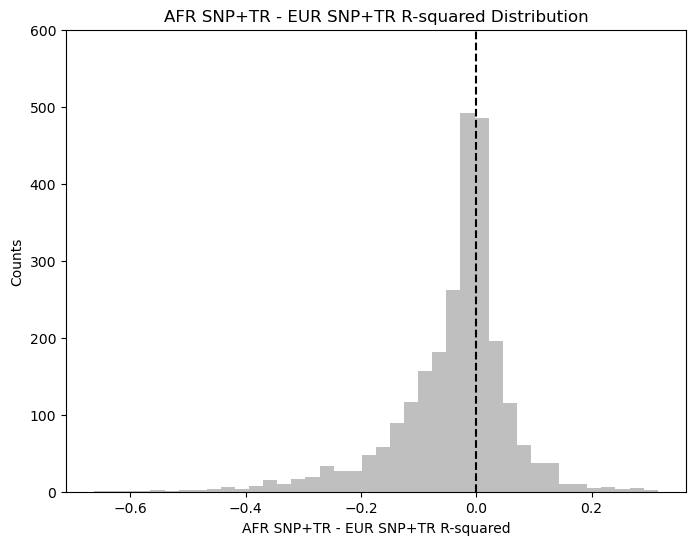

In [12]:
# Distribution of AFR SNP+STR vs EUR SNP+STR
print(f"Total Number of Genes Compared: {gain_dist_df.shape[0]}")
print(f"Number of Genes where AFR SNP+TR > EUR: {np.sum((gain_dist_df['AFR_SNP_STR_R_sq'] - gain_dist_df['EUR_SNP_STR_adj_R_sq_Mean'])>0)}")
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title('AFR SNP+TR - EUR SNP+TR R-squared Distribution')
ax.set_xlabel('AFR SNP+TR - EUR SNP+TR R-squared')
ax.set_ylabel('Counts')

ax.hist(
    gain_dist_df['AFR_SNP_STR_R_sq'] - gain_dist_df['EUR_SNP_STR_adj_R_sq_Mean'], 
    bins=40,
    alpha=0.5,
    color='gray'
)
ax.vlines(0,0,600, color='black', linestyle='dashed')
ax.set_ylim(0,600)

fig.savefig("/storage/mlamkin/data/GeneExprPredictor/paper_figures/afr_vs_eur_snp_tr_r_sq_histogram.pdf")
fig.show()

In [14]:
### Table for top genes with largest AFR Gain
sorted_improved_genes_df = trained_rsq_df.sort_values(by='AFR_gain', ascending=False)
print(sorted_improved_genes_df[['gene_name', 'gene', 'AFR_SNP_R_sq', 'AFR_SNP_STR_R_sq', 'AFR_gain']].to_string())

               gene_name             gene  AFR_SNP_R_sq  AFR_SNP_STR_R_sq      AFR_gain
461523             PPIL3  ENSG00000240344  1.048516e-01      6.085501e-01  5.036985e-01
1034312            HEBP2  ENSG00000051620  1.376327e-01      5.546487e-01  4.170160e-01
2335517           MFSD6L  ENSG00000185156  4.965918e-06      4.135216e-01  4.135166e-01
1930301       AL136419.1  ENSG00000197775  1.018216e-02      4.106419e-01  4.004597e-01
408193              RPIA  ENSG00000153574  1.578122e-03      3.566923e-01  3.551141e-01
2156058           NMRAL1  ENSG00000153406  2.589105e-02      3.255678e-01  2.996767e-01
1568239           TIMM10  ENSG00000134809  1.981763e-01      4.950498e-01  2.968735e-01
755100             GPM6A  ENSG00000150625  8.668693e-02      3.428034e-01  2.561165e-01
1326771           CORO2A  ENSG00000106789  5.361603e-02      2.922136e-01  2.385976e-01
1765522            RPS26  ENSG00000197728  1.278897e-01      3.512834e-01  2.233937e-01
160599              SNX7  ENSG00

In [5]:
# Table for Genes where AFR SNP+TR performed better than EUR
AFR_better_rsq_df = trained_rsq_df[(trained_rsq_df['AFR_SNP_R_sq'] < trained_rsq_df['AFR_SNP_STR_R_sq']) & (trained_rsq_df['EUR_SNP_adj_R_sq_Mean'] < trained_rsq_df['AFR_SNP_STR_R_sq']) & (trained_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] < trained_rsq_df['AFR_SNP_STR_R_sq'])]
sorted_AFR_better_rsq_df = AFR_better_rsq_df.sort_values(by='AFR_SNP_STR_R_sq', ascending=False)
sorted_AFR_better_rsq_df = sorted_AFR_better_rsq_df[['gene_name','gene','EUR_SNP_adj_R_sq_Mean', 'EUR_SNP_STR_adj_R_sq_Mean', 'AFR_SNP_R_sq', 'AFR_SNP_STR_R_sq']]
print(sorted_AFR_better_rsq_df.shape)
#print(sorted_AFR_better_rsq_df.to_string())
#sorted_AFR_better_rsq_df.to_csv('/storage/mlamkin/data/GeneExprPredictor/paper_figures/afr_genes_better_eur.csv', index=False)


allele_df = pd.read_csv('/storage/mlamkin/data/GeneExprPredictor/paper_figures/allele_dist_eur_vs_afr.csv')
allele_df = allele_df.drop_duplicates('gene_name').reset_index(drop=True)

# # Deep dive into genes without TRs that still did better in SNP+TR Model
mask = sorted_AFR_better_rsq_df['gene_name'].isin(allele_df['gene_name'])
tr_AFR_better_df = sorted_AFR_better_rsq_df[mask]
print(f"Num Genes with TR and AFR was better: {tr_AFR_better_df.shape[0]}")
non_tr_AFR_better_df = sorted_AFR_better_rsq_df[~mask]
non_tr_AFR_better_df['AFR_gain'] = non_tr_AFR_better_df['AFR_SNP_STR_R_sq'] - non_tr_AFR_better_df['AFR_SNP_R_sq']

print(non_tr_AFR_better_df.shape)
print(non_tr_AFR_better_df['AFR_gain'].mean())
print(non_tr_AFR_better_df[non_tr_AFR_better_df['AFR_gain'] > 0.01].to_string())

(455, 6)
Num Genes with TR and AFR was better: 341
(114, 7)
0.006043110957927833
        gene_name             gene  EUR_SNP_adj_R_sq_Mean  EUR_SNP_STR_adj_R_sq_Mean  AFR_SNP_R_sq  AFR_SNP_STR_R_sq  AFR_gain
1414318     ARL5B  ENSG00000165997               0.228566                   0.223828  3.074132e-01          0.329722  0.022309
2963380    TOMM34  ENSG00000025772               0.276043                   0.275288  2.966920e-01          0.316789  0.020097
2523595   ST8SIA5  ENSG00000101638               0.068565                   0.053812  2.384574e-01          0.274896  0.036438
1707046   CLEC12A  ENSG00000172322               0.028051                   0.025498  1.568493e-01          0.174810  0.017961
893639     SYCP2L  ENSG00000153157               0.026588                   0.023806  1.241159e-01          0.134138  0.010022
791746       POC5  ENSG00000152359               0.068287                   0.066908  7.534635e-02          0.125626  0.050280
760054   KIAA1430  ENSG0000016

/storage/mlamkin/tmp/ipykernel_15027/888123282.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_tr_AFR_better_df['AFR_gain'] = non_tr_AFR_better_df['AFR_SNP_STR_R_sq'] - non_tr_AFR_better_df['AFR_SNP_R_sq']


In [7]:
# check the allele distribution of each TR in each gene in the AFR population (grab min and max allele and see if the dist is > EUR population)
#   for each gene collect variants from AFR pop and collect nonzero variant info from model coeffs
def compare_tr_allele_distributions(
    gene_id, 
    gene_name,
    eur_gene_expr_predictor,
    afr_gene_expr_predictor,
    model_file,
):
    eur_samples, header_genes = eur_gene_expr_predictor.prepare_header_info(eur_gene_expr_predictor.train_header_file)

    # Collect the variants
    eur_dataset, eur_expr = eur_gene_expr_predictor.collect_gts_gene_expr(
        gene_id,
        500,
        header_genes,
        eur_samples,
        snp_variants=None,
        str_variants=None,
        expr_file=eur_gene_expr_predictor.train_expr_file,
        header_file=eur_gene_expr_predictor.train_header_file,
    )

    eur_gts = eur_dataset[1]
    eur_variants = {}
    eur_vars = eur_gene_expr_predictor.variants[gene_id][:eur_dataset[1].shape[1]]
    for var_ind, var in enumerate(eur_vars):
        id = f"{var[0]}_{var[1]}_{var[2]}"
        eur_variants[id] = var_ind

    afr_samples, afr_header_genes = afr_gene_expr_predictor.prepare_header_info(afr_gene_expr_predictor.train_header_file)
    afr_dataset, afr_expr = afr_gene_expr_predictor.collect_gts_gene_expr(
        gene_id,
        500,
        afr_header_genes,
        afr_samples,
        snp_variants=eur_gene_expr_predictor.snp_variants[gene_id],
        str_variants=eur_gene_expr_predictor.str_variants[gene_id],
        expr_file=afr_gene_expr_predictor.train_expr_file,
        header_file=afr_gene_expr_predictor.train_header_file,
        filter_freq=False
    )

    afr_gts = np.zeros((afr_dataset[1].shape[0], eur_dataset[1].shape[1]))
    afr_variants = afr_gene_expr_predictor.variants[gene_id][:afr_dataset[1].shape[1]]
    for afr_ind, afr_var in enumerate(afr_variants):
        id = f"{afr_var[0]}_{afr_var[1]}_{afr_var[2]}"
        afr_gts[:,eur_variants[id]] = afr_dataset[1][:,afr_ind]
    
    # Load prior trained model
    with open(model_file, 'rb') as f:
        model = pickle.load(f)

    coeff = model.coef_

    # Grab all nonzero coefficients
    coef_filter, var_coef_filter, num_nonzero_coeff = eur_gene_expr_predictor.nonzero_coeff_filter(
        coeff, gene_id, 0.01
    )

    # Filtered variants
    num_snps = len(eur_gene_expr_predictor.snp_variants[gene_id])
    num_trs = len(eur_gene_expr_predictor.str_variants[gene_id])
    wanted_vars = num_snps + num_trs
    var_coef_filter = var_coef_filter[:wanted_vars]
    vars = eur_gene_expr_predictor.variants[gene_id][:wanted_vars]
    #nonzero_vars = vars[var_coef_filter] # print this out to know what the nonzero vars are

    # Filtered Coefficients
    snp_coeffs = coeff[:num_snps]
    snp_coeffs = snp_coeffs[coef_filter[:num_snps]]
    tr_coeffs = coeff[num_snps:]
    tr_coeffs = tr_coeffs[coef_filter[num_snps:]]

    # Plot strongest TR coefficient
    # Find TR using tr_coeffs index and plot
    best_tr_inds = np.arange(coeff[num_snps:].shape[0])
    best_tr_inds = best_tr_inds[np.abs(coeff[num_snps:]) > 0] + num_snps

    gene_gt_df = pd.DataFrame(columns=['gene_name', 'gene', 'chrom', 'tr_start_pos', 'tr_coeff_size', 'eur_min_gt', 'eur_max_gt', 'afr_min_gt', 'afr_max_gt'])
    collected_trs = []
    for best_tr_ind, best_tr_coeff in zip(best_tr_inds, tr_coeffs):
        # Collect EUR GT range
        # Filter out gts > 500 this is an error due to incomplete gts
        eur_tr_gts = eur_gts[:,best_tr_ind]
        filtered_eur_tr_gts = eur_tr_gts[eur_tr_gts < 500]
        eur_min = np.min(filtered_eur_tr_gts)
        eur_max = np.max(filtered_eur_tr_gts)

        afr_tr_gts = afr_gts[:,best_tr_ind]
        filtered_afr_tr_gts = afr_tr_gts[afr_tr_gts < 500]
        if filtered_afr_tr_gts.shape[0] == 0:
            afr_min = 'NA'
            afr_max = 'NA'
        else:
            afr_min = np.min(filtered_afr_tr_gts)
            afr_max = np.max(filtered_afr_tr_gts)

        collected_trs.append({
            'gene_name': gene_name, 
            'gene': gene_id, 
            'chrom': vars[best_tr_ind][1], 
            'tr_start_pos':vars[best_tr_ind][2],
            'tr_coeff_size': best_tr_coeff,
            'eur_min_gt': eur_min, 
            'eur_max_gt': eur_max, 
            'afr_min_gt': afr_min, 
            'afr_max_gt': afr_max,
        })

    gene_gt_df = pd.concat([gene_gt_df, pd.DataFrame(collected_trs, index=np.arange(len(collected_trs)))], ignore_index=True)
    return gene_gt_df


all_genes_gt_df = None
for row_ind, row_info in sorted_AFR_better_rsq_df[['gene_name', 'gene']].iterrows():
    gene_id = row_info['gene']
    gene_name = row_info['gene_name']

    # Load gene start and end coordinates
    # Load required genotypes and gene expression to collect coefficients
    #path = "/expanse/projects/gymreklab/mlamkin/" # Use for Expanse
    path = "/gymreklab-tscc/mlamkin/" # Use for Snorlax
    EUR_header_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_and_filtered_hg38.csv"
    EUR_expr_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_filtered_final_residuals_hg38.csv"
    AFR_header_file = path + "GeneExprPredictor_data/train_data/AFR_normalized_and_filtered_hg38.csv"
    AFR_expr_file = path + "GeneExprPredictor_data/train_data/AFR_normalized_filtered_final_residuals_hg38.csv"
    snp_file = path + "GeneExprPredictor_data/SNP_vcfs/SNP_{}_filtered.vcf.gz"
    str_file = path + "GeneExprPredictor_data/STR_vcfs/ensemble_{}_filtered.vcf.gz"

    # Load gene start and end
    gene_info_df = pd.read_csv(EUR_header_file, delimiter='\t', usecols=['start', 'end', 'gene_id'])
    gene_info_df['gene_id'] = gene_info_df['gene_id'].str.split('.').str[0]
    gene_info = gene_info_df[gene_info_df['gene_id'] == gene_id]
    gene_start = gene_info['start'].iloc[0] 
    gene_end = gene_info['end'].iloc[0] 

    # Load models
    snp_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs.pkl"
    snp_str_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs+STRs.pkl"

    sample_ind = 5 # NOTE for GTEx sample_ind is 4
    gene_id_ind = 3
    gene_chrom_ind = 0
    gene_start_ind = 1
    gene_end_ind = 2

    eur_gene_expr_predictor = GeneExpressionPredictor(
        paramsearchfxn=None,
        model=None,
        model_params=None,
        hyperparams=None,
        gene_names=[gene_name],
        sample_ind=sample_ind,
        gene_id_ind=gene_id_ind,
        gene_chrom_ind=gene_chrom_ind,
        gene_start_ind=gene_start_ind,
        gene_end_ind=gene_end_ind,
        train_header_file=EUR_header_file,
        predict_header_file=None,
        snp_file=snp_file,
        str_file=str_file,
        train_expr_file=EUR_expr_file,
        predict_expr_file=None,
        param_shift=None,
        coeff_thresh=None,
        outpath=None,
        n_jobs=1,
        level="WARNING",
    )

    afr_gene_expr_predictor = GeneExpressionPredictor(
        paramsearchfxn=None,
        model=None,
        model_params=None,
        hyperparams=None,
        gene_names=[gene_name],
        sample_ind=sample_ind,
        gene_id_ind=gene_id_ind,
        gene_chrom_ind=gene_chrom_ind,
        gene_start_ind=gene_start_ind,
        gene_end_ind=gene_end_ind,
        train_header_file=AFR_header_file,
        predict_header_file=None,
        snp_file=snp_file,
        str_file=str_file,
        train_expr_file=AFR_expr_file,
        predict_expr_file=None,
        param_shift=None,
        coeff_thresh=None,
        outpath=None,
        n_jobs=1,
        level="WARNING",
    )

    gene_gt_df = compare_tr_allele_distributions(
        gene_id, 
        gene_name,
        eur_gene_expr_predictor,
        afr_gene_expr_predictor,
        snp_str_model_file, 
    )

    if all_genes_gt_df is None:
        all_genes_gt_df = pd.merge(gene_gt_df, sorted_AFR_better_rsq_df, on=['gene_name', 'gene'])
    else:
        merge_gt_df = pd.merge(gene_gt_df, sorted_AFR_better_rsq_df, on=['gene_name', 'gene'])
        all_genes_gt_df = pd.concat([all_genes_gt_df, merge_gt_df], ignore_index=True)

all_genes_gt_df.to_csv('/storage/mlamkin/data/GeneExprPredictor/paper_figures/allele_dist_eur_vs_afr.csv', sep=',', index=False)
print(all_genes_gt_df.to_string())

Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
The current variant in the VCF only has one allele per sample.
The current variant in the VCF only has one allele per sample.
/storage/mlamkin/anaconda3/envs/nonlinear/li

         gene_name             gene  chrom tr_start_pos  tr_coeff_size  eur_min_gt  eur_max_gt afr_min_gt afr_max_gt  EUR_SNP_adj_R_sq_Mean  EUR_SNP_STR_adj_R_sq_Mean  AFR_SNP_R_sq  AFR_SNP_STR_R_sq
0            PPIL3  ENSG00000240344   chr2    200457223       0.068495        16.0        38.0       30.0       38.0               0.470386                   0.485813  1.048516e-01          0.608550
1            PPIL3  ENSG00000240344   chr2    200866439      -0.195667        38.0        45.0       38.0       45.0               0.470386                   0.485813  1.048516e-01          0.608550
2            PPIL3  ENSG00000240344   chr2    200880410      -0.067408        28.0        44.0       28.0       46.0               0.470386                   0.485813  1.048516e-01          0.608550
3            PPIL3  ENSG00000240344   chr2    200888053       0.107855        41.0        53.0       42.0       52.0               0.470386                   0.485813  1.048516e-01          0.608550
4    

#### AFR - EUR Gain top genes barplot and top TR gene expression boxplot

/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Lasso from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading the

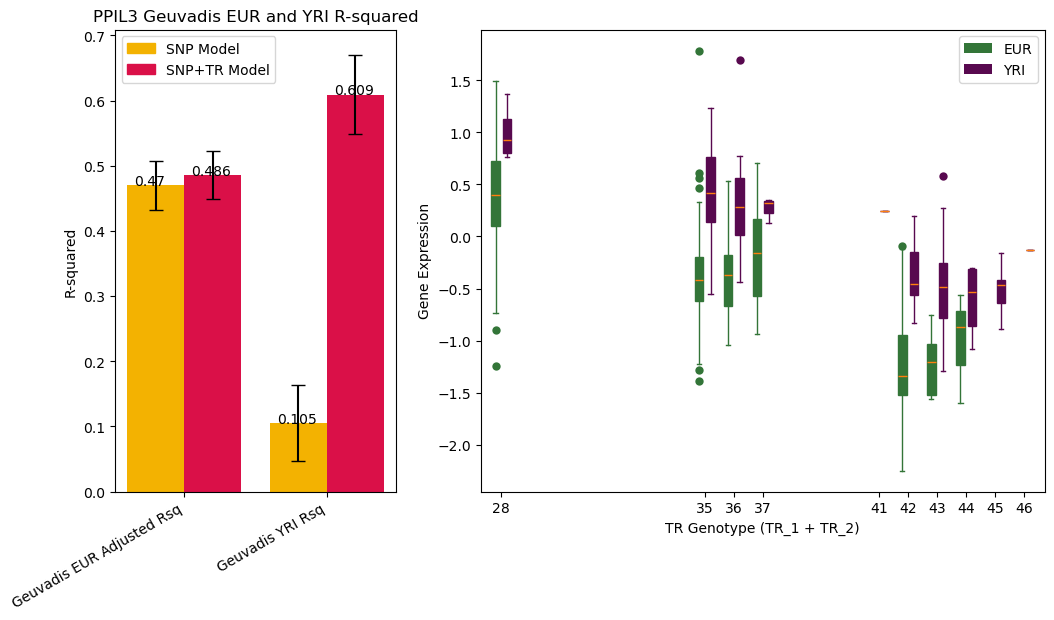

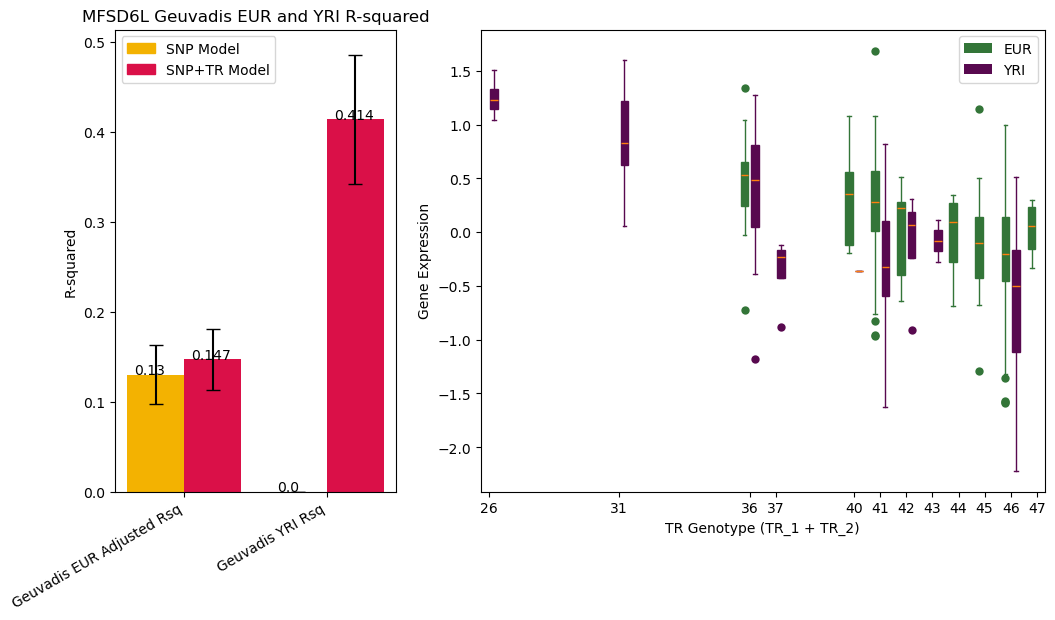

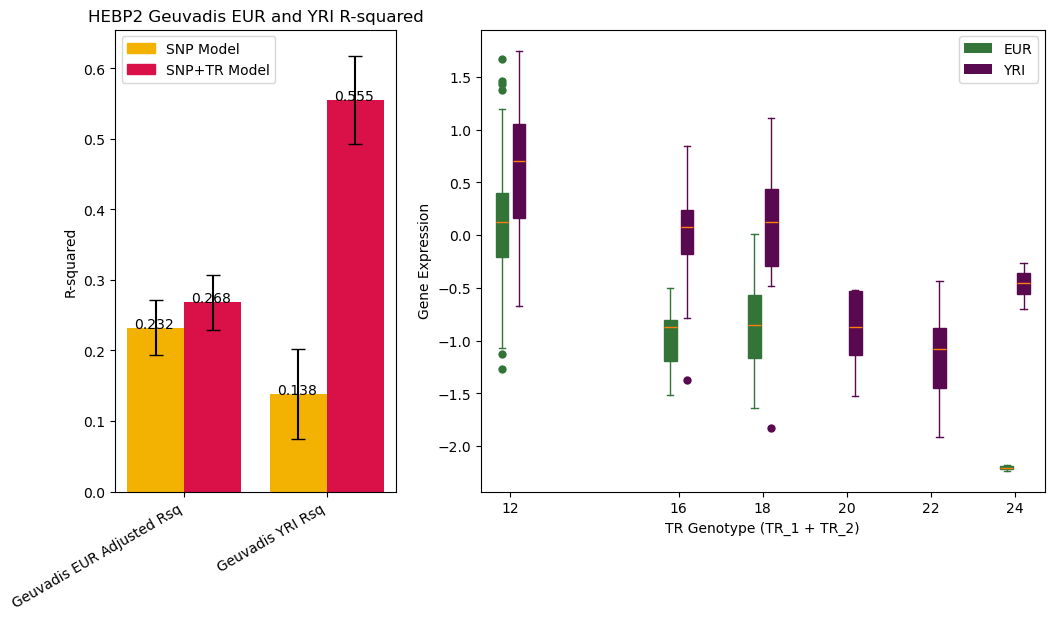

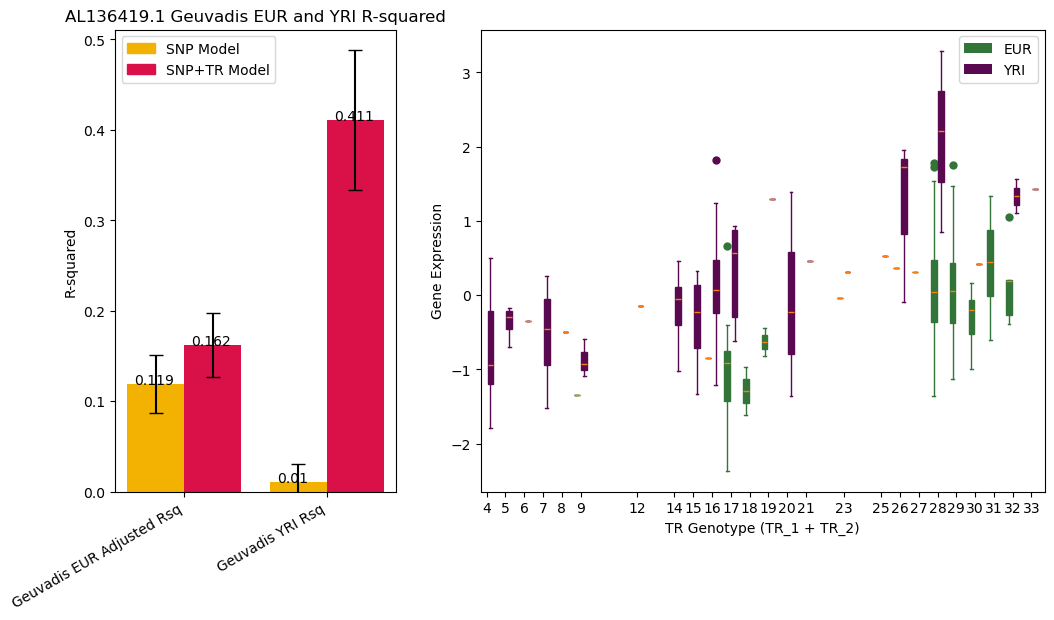

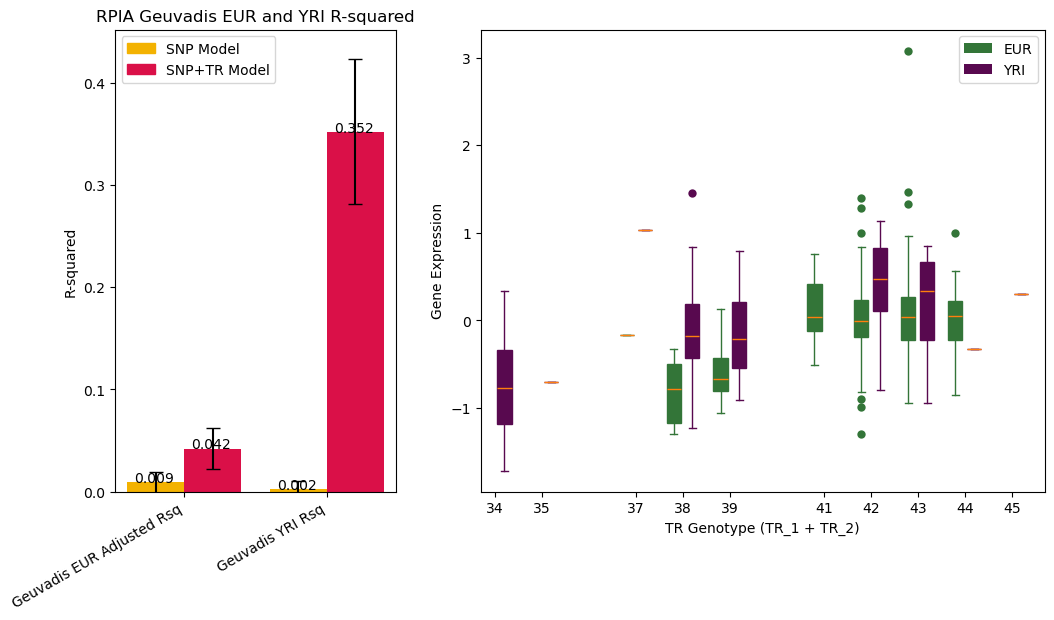

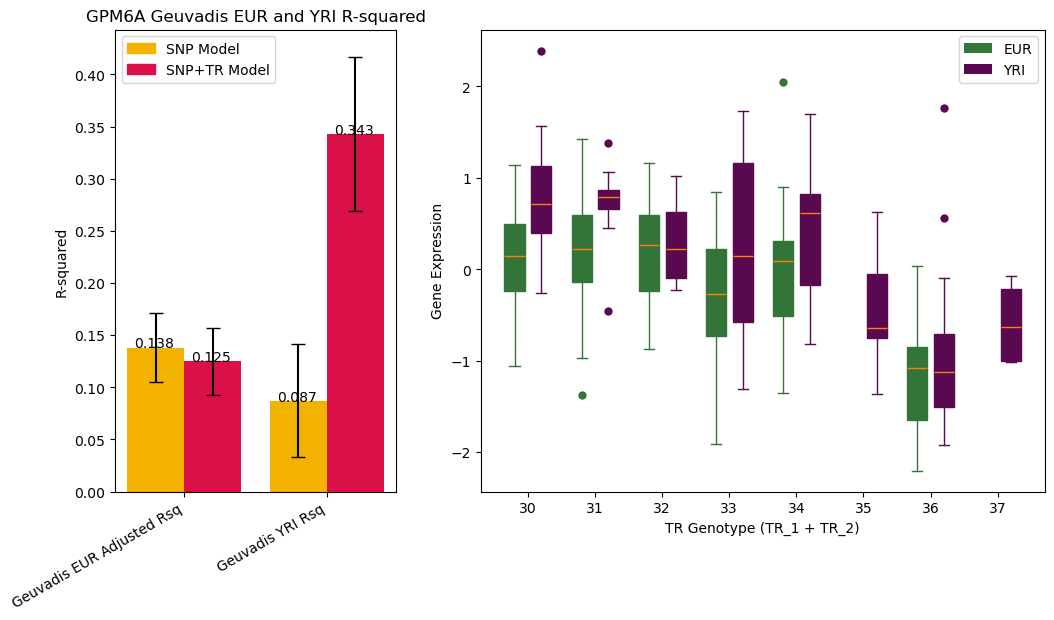

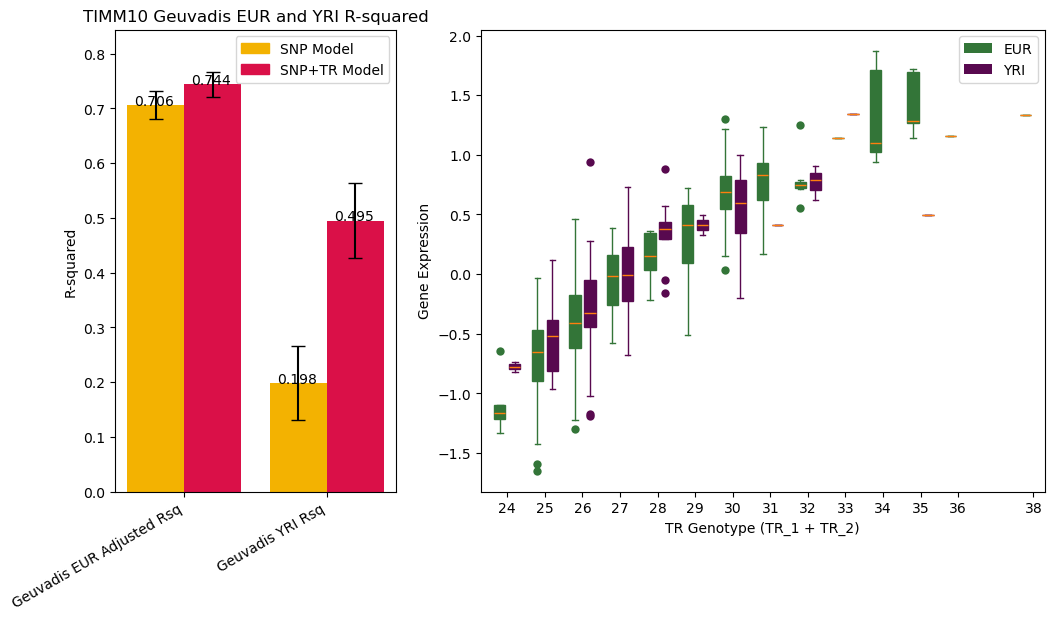

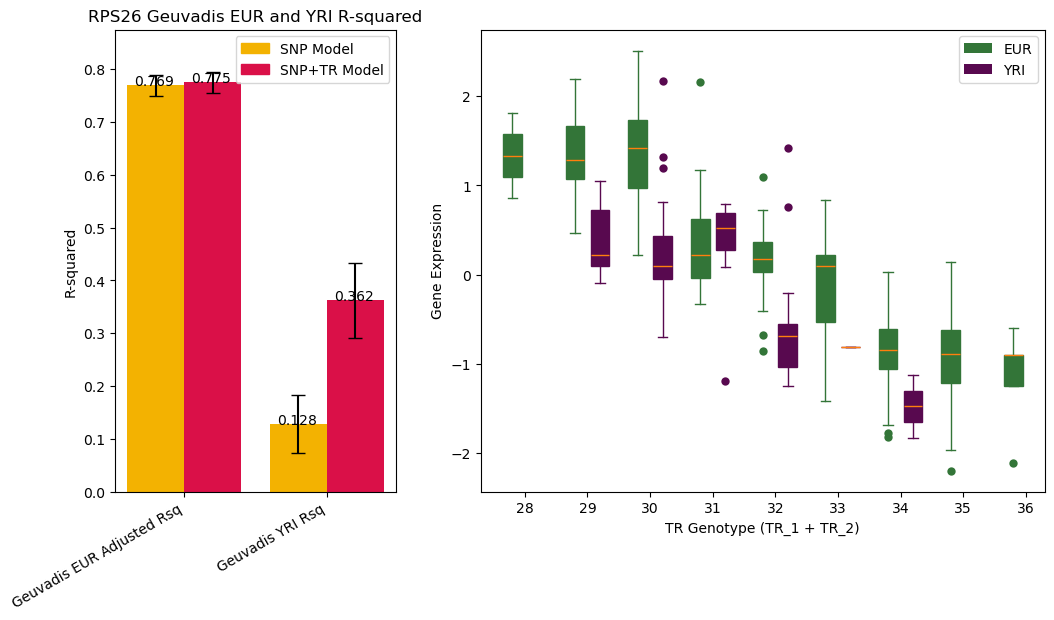

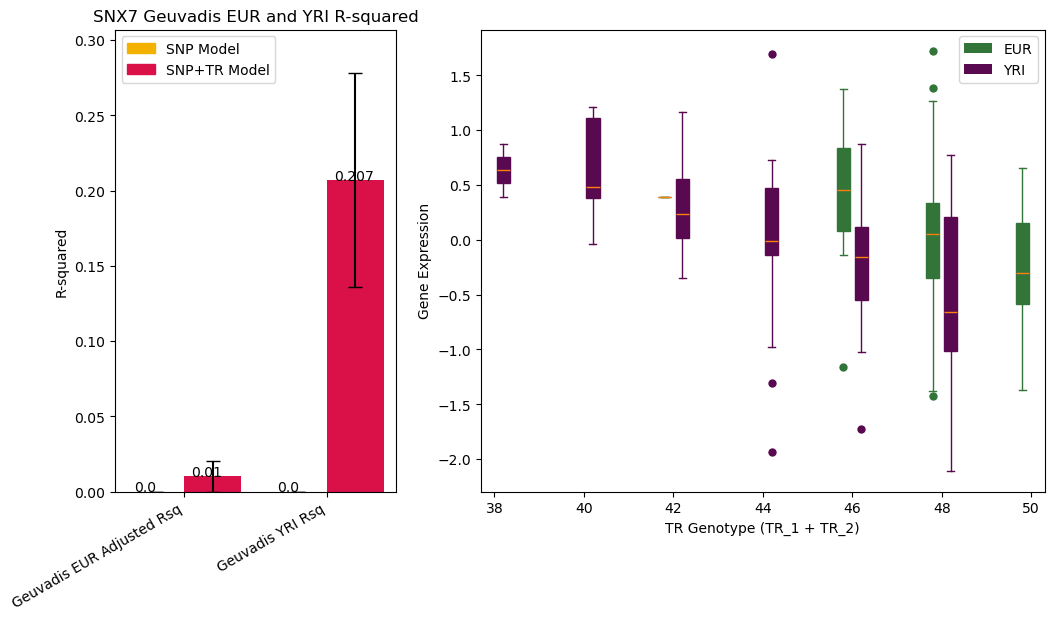

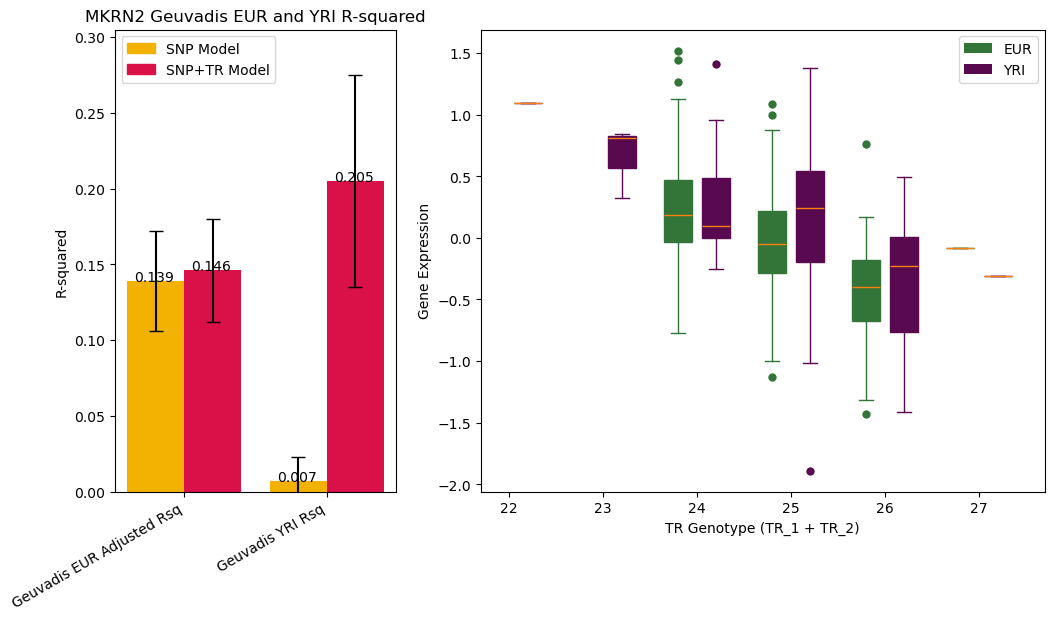

In [10]:
### Gain in AFR > EUR top genes and TRs #####

def plot_bar_and_expr(
    gene, 
    gene_id, 
    geuv_df, 
    eur_gts,
    afr_gts,
    eur_expr,
    afr_expr,
    output
):
    fig, axs = plt.subplots(1, 2, sharey=False, width_ratios=[1,2])
    fig.set_figheight(6)
    fig.set_figwidth(12)

    # Barplot
    create_geuv_afr_eur_gene_barplot(
        gene,
        gene_id,
        geuv_df,
        axs[0]
    )
    axs[0].set_xticklabels(axs[0].get_xticklabels(), rotation=30, ha='right')

    # Boxplots
    gt_box_plot(
        eur_gts,
        afr_gts,
        eur_expr,
        afr_expr,
        axs[1]
    )
    fig.savefig(output)
    return

def gt_box_plot(
    eur_gts,
    afr_gts,
    eur_expr,
    afr_expr,
    ax
):
    eur_pos = np.unique(eur_gts).astype(np.uint16)
    afr_pos = np.unique(afr_gts).astype(np.uint16)
    eur_expr_boxplot = []
    afr_expr_boxplot = []
    for unique_eur_gt in eur_pos:
        eur_expr_boxplot.append(eur_expr[eur_gts == unique_eur_gt])
    for unique_afr_gt in afr_pos:
        afr_expr_boxplot.append(afr_expr[afr_gts == unique_afr_gt])

    # merge afr and eur_pos to get x_tick positions
    total_pos = np.unique(np.concatenate((eur_pos, afr_pos)))

    # Plot gts vs expression
    for gts, expr, offset, color in zip([eur_pos, afr_pos], [eur_expr_boxplot, afr_expr_boxplot], [0, 0.4], [eur_color, afr_color]):
        box = ax.boxplot(
            expr, 
            positions=gts+offset, 
            patch_artist=True,
            flierprops=dict(markeredgewidth=0),
            widths=0.3
        )

        # Change colors in boxplot
        for entry in ['fliers', 'boxes']:
            for item in box[entry]:
                if entry == 'fliers':
                    item.set_markerfacecolor(color)
                else:
                    plt.setp(item, color=color)

        for entry in ['whiskers', 'caps']:
            for items in zip(box[entry][::2],box[entry][1::2]):
                plt.setp(items, color=color)

    eur_patch = mpatches.Patch(facecolor=eur_color, label='EUR')
    afr_patch = mpatches.Patch(facecolor=afr_color, label='YRI')
    ax.legend(handles=[eur_patch, afr_patch])
    ax.set_xticks(total_pos+0.2, labels=total_pos)
    ax.set_xlabel('TR Genotype (TR_1 + TR_2)')
    ax.set_ylabel('Gene Expression')
    return

path = "/gymreklab-tscc/mlamkin/" # Use for Snorlax
EUR_header_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_and_filtered_hg38.csv"
EUR_expr_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_filtered_final_residuals_hg38.csv"
AFR_header_file = path + "GeneExprPredictor_data/train_data/AFR_normalized_and_filtered_hg38.csv"
AFR_expr_file = path + "GeneExprPredictor_data/train_data/AFR_normalized_filtered_final_residuals_hg38.csv"
snp_file = path + "GeneExprPredictor_data/SNP_vcfs/SNP_{}_filtered.vcf.gz"
str_file = path + "GeneExprPredictor_data/STR_vcfs/ensemble_{}_filtered.vcf.gz"

# Get list of 2553 nonzero genes 
nonzero_gene_ids_file = path + "GeneExprPredictor_data/gene_sets/gtex/geuvadis_EUR_trained_genes.txt"
gene_ids = np.loadtxt(nonzero_gene_ids_file, dtype=object)
gene_ids = [
    'ENSG00000240344',
    'ENSG00000185156',
    'ENSG00000051620',
    'ENSG00000197775',
    'ENSG00000153574',
    'ENSG00000150625',
    'ENSG00000134809',
    'ENSG00000197728',
    'ENSG00000162627',
    'ENSG00000075975',
]



# Collect gain and number of feature information
gain_df = pd.read_csv(
    '/storage/mlamkin/data/GeneExprPredictor/paper_figures/trained_genes_table.csv', 
    delimiter=',', 
    usecols=['gene_name','gene','Num_SNPs','Num_TRs']
)

for gene_id in gene_ids:
    # Grab gene gain and num_snp info
    gain_gene_df = gain_df[gain_df['gene'] == gene_id]
    num_snps = gain_gene_df['Num_SNPs'].values[0]
    gene = gain_gene_df['gene_name'].values[0]
    geuv_gene_df = trained_rsq_df[trained_rsq_df['gene_name'] == gene]

    # Load SNP+TR Model Coefficients
    snp_tr_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs+STRs.pkl"
    with open(snp_tr_model_file, 'rb') as f:
        snp_tr_model = pickle.load(f)

    snp_tr_coeff = snp_tr_model.coef_
    tr_coeffs = np.abs(snp_tr_coeff[num_snps:])
    best_tr_ind = np.argmax(tr_coeffs)

    # If no TRs are used in the model don't put in plot
    if tr_coeffs[best_tr_ind] < 1e-8:
        continue

    # Load EUR and AFR data
    sample_ind = 5 # NOTE for GTEx sample_ind is 4
    gene_id_ind = 3
    gene_chrom_ind = 0
    gene_start_ind = 1
    gene_end_ind = 2

    eur_gene_expr_predictor = GeneExpressionPredictor(
        paramsearchfxn=None,
        model=None,
        model_params=None,
        hyperparams=None,
        gene_names=[gene_id],
        sample_ind=sample_ind,
        gene_id_ind=gene_id_ind,
        gene_chrom_ind=gene_chrom_ind,
        gene_start_ind=gene_start_ind,
        gene_end_ind=gene_end_ind,
        train_header_file=EUR_header_file,
        predict_header_file=None,
        snp_file=snp_file,
        str_file=str_file,
        train_expr_file=EUR_expr_file,
        predict_expr_file=None,
        param_shift=None,
        coeff_thresh=None,
        outpath=None,
        n_jobs=1,
        level="WARNING",
    )

    afr_gene_expr_predictor = GeneExpressionPredictor(
        paramsearchfxn=None,
        model=None,
        model_params=None,
        hyperparams=None,
        gene_names=[gene_id],
        sample_ind=sample_ind,
        gene_id_ind=gene_id_ind,
        gene_chrom_ind=gene_chrom_ind,
        gene_start_ind=gene_start_ind,
        gene_end_ind=gene_end_ind,
        train_header_file=AFR_header_file,
        predict_header_file=None,
        snp_file=snp_file,
        str_file=str_file,
        train_expr_file=AFR_expr_file,
        predict_expr_file=None,
        param_shift=None,
        coeff_thresh=None,
        outpath=None,
        n_jobs=1,
        level="WARNING",
    )

    eur_samples, header_genes = eur_gene_expr_predictor.prepare_header_info(eur_gene_expr_predictor.train_header_file)

    # Collect the variants
    eur_dataset, eur_expr = eur_gene_expr_predictor.collect_gts_gene_expr(
        gene_id,
        500,
        header_genes,
        eur_samples,
        snp_variants=None,
        str_variants=None,
        expr_file=eur_gene_expr_predictor.train_expr_file,
        header_file=eur_gene_expr_predictor.train_header_file,
    )

    eur_gts = eur_dataset[1]

    eur_variants = {}
    eur_vars = eur_gene_expr_predictor.variants[gene_id][:eur_dataset[1].shape[1]]
    for var_ind, var in enumerate(eur_vars):
        id = f"{var[0]}_{var[1]}_{var[2]}"
        eur_variants[id] = var_ind

    afr_samples, afr_header_genes = afr_gene_expr_predictor.prepare_header_info(afr_gene_expr_predictor.train_header_file)
    afr_dataset, afr_expr = afr_gene_expr_predictor.collect_gts_gene_expr(
        gene_id,
        500,
        afr_header_genes,
        afr_samples,
        snp_variants=eur_gene_expr_predictor.snp_variants[gene_id],
        str_variants=eur_gene_expr_predictor.str_variants[gene_id],
        expr_file=afr_gene_expr_predictor.train_expr_file,
        header_file=afr_gene_expr_predictor.train_header_file,
        filter_freq=False,
    )

    afr_gts = np.zeros((afr_dataset[1].shape[0], eur_dataset[1].shape[1]))
    afr_variants = afr_gene_expr_predictor.variants[gene_id][:afr_dataset[1].shape[1]]
    for afr_ind, afr_var in enumerate(afr_variants):
        id = f"{afr_var[0]}_{afr_var[1]}_{afr_var[2]}"
        afr_gts[:,eur_variants[id]] = afr_dataset[1][:,afr_ind]

    plot_bar_and_expr(
        gene, 
        gene_id, 
        geuv_gene_df, 
        eur_gts[:,num_snps+best_tr_ind],
        afr_gts[:,num_snps+best_tr_ind],
        eur_expr,
        afr_expr,
        f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/{gene}/{gene}_geuv_eur_afr_barplot_{eur_vars[num_snps+best_tr_ind][2]}_tr_expr.pdf"
    )


### iii. Nonlinear Improvement

In [4]:
print(np.sum(trained_rsq_df['EUR_nonlinear_adj_R_sq_Mean'] > trained_rsq_df['EUR_SNP_adj_R_sq_Mean']))
print(np.sum(trained_rsq_df['nonlin_adj_rsq_overall_diff'] > 0))

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title('EUR Nonlinear Gain Distribution')
ax.set_xlabel('Nonlinear Gain')
ax.set_ylabel('Counts')

ax.hist(
    trained_rsq_df['nonlin_adj_rsq_overall_diff'], 
    bins=40,
    alpha=0.5,
    color='gray'
)
ax.vlines(0,0,500, color='black', linestyle='dashed')
ax.set_ylim(0,500)

fig.savefig("/storage/mlamkin/data/GeneExprPredictor/paper_figures/eur_nonlinear_gain_histogram.pdf")
fig.show()

1159
737


In [7]:
### Genes with nonlinear improvement ###
improved_genes_df = trained_rsq_df[trained_rsq_df['nonlin_adj_rsq_overall_diff'] > 0]
afr_improved_genes_df = trained_rsq_df[trained_rsq_df['afr_nonlin_rsq_diff'] > 0]

print(np.sum(trained_rsq_df['nonlin_adj_rsq_overall_diff'] > 0.01))
### How many genes improved and what were the top genes for SNP vs SNP+STR ###
print(f"Total genes r-sq diff > 0 nonlinear Adjusted R-squared: {improved_genes_df.shape[0]}")
print("Top differences between adj r-squared of SNP Models and SNP+STRs")
# Sort by delta r-squared and print
sorted_improved_genes_df = improved_genes_df.sort_values(by='nonlin_adj_rsq_overall_diff', ascending=False)
sorted_improved_genes_df = sorted_improved_genes_df[[
        'gene_name', 
        'gene', 
        'hsq', 
        'hsq.pv', 
        'EUR_SNP_adj_R_sq_Mean', 
        'EUR_SNP_STR_adj_R_sq_Mean', 
        'EUR_nonlinear_adj_R_sq_Mean', 
        'nonlin_adj_rsq_overall_diff',
        'AFR_SNP_R_sq',
        'AFR_SNP_STR_R_sq',
        'AFR_nonlinear_R_sq',
        'afr_nonlin_rsq_diff',
    ]]
sorted_improved_genes_df.to_csv('/storage/mlamkin/data/GeneExprPredictor/paper_figures/nonlinear_improved_genes_table.csv', sep=',', index=False)

sorted_afr_improved_genes_df = afr_improved_genes_df.sort_values(by='afr_nonlin_rsq_diff', ascending=False)
sorted_afr_improved_genes_df = sorted_afr_improved_genes_df[[
        'gene_name', 
        'gene', 
        'hsq', 
        'hsq.pv', 
        'EUR_SNP_adj_R_sq_Mean', 
        'EUR_SNP_STR_adj_R_sq_Mean', 
        'EUR_nonlinear_adj_R_sq_Mean', 
        'nonlin_adj_rsq_overall_diff',
        'AFR_SNP_R_sq',
        'AFR_SNP_STR_R_sq',
        'AFR_nonlinear_R_sq',
        'afr_nonlin_rsq_diff',
    ]]

print(sorted_improved_genes_df.shape)
print(sorted_improved_genes_df.to_string())
print(sorted_afr_improved_genes_df.shape)
print(sorted_afr_improved_genes_df.to_string())

100
Total genes r-sq diff > 0 nonlinear Adjusted R-squared: 737
Top differences between adj r-squared of SNP Models and SNP+STRs
(737, 12)
             gene_name             gene       hsq        hsq.pv  EUR_SNP_adj_R_sq_Mean  EUR_SNP_STR_adj_R_sq_Mean  EUR_nonlinear_adj_R_sq_Mean  nonlin_adj_rsq_overall_diff  AFR_SNP_R_sq  AFR_SNP_STR_R_sq  AFR_nonlinear_R_sq  afr_nonlin_rsq_diff
3024500          CECR5  ENSG00000069998  0.086161  4.118000e-02               0.012350                   0.083278                     0.137187                     0.053909  4.315725e-02          0.067690        2.205237e-01         1.528337e-01
2639115          CARM1  ENSG00000142453  0.111705  3.004000e-08               0.048126                   0.052260                     0.105705                     0.053444  8.056168e-03          0.021783        3.639429e-02         1.461082e-02
2649586   CTD-2006C1.2  ENSG00000219665  0.177136  2.083000e-05               0.073567                   0.068241             

In [10]:
# Plot stratification plots from the TRs that had nonzero nonlinear coeffs in our model

def stratification_plot(str_info, str_gts, gene_expr, gene_name, output):
    # sort along cols (sorting along rows doesn't do it by the pairs but by values)
    str_gts = np.sort(str_gts, axis=1)
    str_linear_gts = np.sum(str_gts, axis=1)
    str_nonlinear_gts = np.sum(np.square(str_gts), axis=1)
    str_all_gts = np.column_stack((str_linear_gts, str_nonlinear_gts))    
    
    # standardize all data
    X_scaler = StandardScaler()
    norm_gts = X_scaler.fit_transform(str_all_gts)
    
    # Estimate the y-intercept for KIAA1274 using y_int = gene expr mean - (lin_coeff * norm_str_lin_gts + nonlin_coeff * str_nonlinear_gts)
    # lin_coeff = -5.493208812987814, nonlin_coeff = 0.2730153323863306
    # NOTE the nonlinear GTs are not normalized because we didn't do that when running association tests
    y_intercept = np.mean(gene_expr) + 5.4932*(np.mean(norm_gts[:,0])) - 0.273015*(np.mean(str_nonlinear_gts))

    # key is sample alleles, value is an array of linear normalized gts and nonlinear normalized gts
    allele_mapping = {}
    for allele_ind, allele_pair in enumerate(str_gts):
        allele_mapping[f'[{allele_pair[0]} {allele_pair[1]}]'] = norm_gts[allele_ind]

    # Flatten all alleles and grab all unique ones
    all_unique_alleles = np.unique(str_gts.flatten())

    # Figure out if one of the alleles only appears in one pair then remove that from the plot
    all_unique_allele_pairs = {}
    for allele_ind, allele in enumerate(all_unique_alleles):
        # Calculate nu
        unique_gts = (str_gts[:,0] == allele) | (str_gts[:,1] == allele)
        alternate_alleles = set()
        for allele_pair in str_gts[unique_gts,:]:
            if allele_pair[0] != allele:
                alternate_alleles.add(allele_pair[0])
            else:
                alternate_alleles.add(allele_pair[1])
        
        # Store alternate alleles if it contains more than 1 allele it pairs with
        if len(alternate_alleles) > 1:
            all_unique_allele_pairs[allele] = alternate_alleles

    unique_alleles = np.array(list(all_unique_allele_pairs.keys()), dtype=np.int32)

    # Calculate number of plots 
    num_plots = np.floor(np.sqrt(unique_alleles.shape[0]))
    first = num_plots
    second = num_plots
    while True:
        if first * second >= unique_alleles.shape[0]:
            break
        if first - second < 1:
            first += 1
        else:
            second += 1

    if (first * second) == 0:
        return

    fig, ax = plt.subplots(int(first), int(second), sharey=True)
    fig.set_figheight(7)
    fig.set_figwidth(9)
    for allele_ind, allele in enumerate(unique_alleles):
        unique_gts = (str_gts[:,0] == allele) | (str_gts[:,1] == allele)

        # Calculate Mean expression and boundaries for plot
        alternate_alleles = np.sort(list(all_unique_allele_pairs[allele]))
        expr = []
        min_expr = []
        max_expr = []
        for x_val in alternate_alleles:
            # Calculate mean, min, and max for each unique pairing
            mask = None
            if x_val < allele:
                mask = (str_gts[unique_gts, 0] == x_val) & (str_gts[unique_gts, 1] == allele)
            elif x_val > allele:
                mask = (str_gts[unique_gts, 1] == x_val) & (str_gts[unique_gts, 0] == allele)
            else:
                mask = (str_gts[unique_gts, 0] == x_val) & (str_gts[unique_gts, 1] == allele)

            filtered_expr = (gene_expr[unique_gts])[mask]
            expr.append(np.mean(filtered_expr))
            std_dev = np.std(filtered_expr)

            # 95% of data included in boundaries
            min_expr.append(expr[-1] - std_dev*2)
            max_expr.append(expr[-1] + std_dev*2)

        # Calculate which subplot these values are used in
        y_ind = allele_ind % int(second)
        x_ind = (allele_ind - y_ind) // int(second)

        # Get boundaries of x-axis
        min_allele = np.min(unique_alleles)
        max_allele = np.max(unique_alleles)

        # Plot alleles and mean gene expression
        # KIAA haploid trend
        # Normalized calculated by doing on entire sample population then grabbing those normalized with a particular allele pair
        norm_alleles = []
        for hap_allele in alternate_alleles:
            first_allele = np.min([allele, hap_allele])
            second_allele = np.max([allele, hap_allele])
            norm_alleles.append(allele_mapping[f'[{first_allele} {second_allele}]'])

        norm_alleles = np.array(norm_alleles)
        hap_trend = 0.31078 * np.abs(norm_alleles[:,1])
        ax[x_ind][y_ind].plot(alternate_alleles, hap_trend, 'o-', color='b')

        # Geuvadis learned association: gene_expr = -5.493208812987814 (X1+X2) + 0.2730153323863306 (X1**2+X2**2)
        assoc_hap_trend = 0.273015 * (allele**2 + np.square(alternate_alleles)) - 5.4932 * (allele + alternate_alleles) - y_intercept

        ax[x_ind][y_ind].plot(alternate_alleles, assoc_hap_trend, 'o-', color='g')
                        
        if int(first) == 1 and int(second) == 1:
            ax.plot(alternate_alleles, expr, 'o-', label=f"{allele}")
            ax.fill_between(alternate_alleles, min_expr, max_expr, alpha=0.3)
            ax.set_xlim(min_allele, max_allele)
            ax.set_xlabel("Allele 2")
            ax.set_ylabel("Mean Expression")
            ax.legend(title="Allele 1")
        elif int(second) == 1:
            ax[x_ind].plot(alternate_alleles, expr, 'o-', label=f"{allele}")
            ax[x_ind].fill_between(alternate_alleles, min_expr, max_expr, alpha=0.3)
            ax[x_ind].set_xlim(min_allele, max_allele)
            ax[x_ind].set_xlabel("Allele 2")
            ax[x_ind].set_ylabel("Mean Expression")
            ax[x_ind].legend(title="Allele 1")
        else:
            ax[x_ind][y_ind].plot(alternate_alleles, expr, 'o-', label=f"{allele}")
            ax[x_ind][y_ind].fill_between(alternate_alleles, min_expr, max_expr, alpha=0.3)
            ax[x_ind][y_ind].set_xlim(min_allele, max_allele)
            if x_ind == int(first)-1:
                ax[x_ind][y_ind].set_xlabel("Allele 2")
            if y_ind == 0:
                ax[x_ind][y_ind].set_ylabel("Mean Expression")
            ax[x_ind][y_ind].legend(title="Allele 1")

    plt.suptitle(f"Gene {gene_name} STR nonlin coeff {str_info['coeff']} chrom {str_info['chrom']} pos {str_info['pos']}")
    fig.savefig(output)

    return

path = "/gymreklab-tscc/mlamkin/" # Use for Snorlax
EUR_header_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_and_filtered_hg38.csv"
EUR_expr_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_filtered_final_residuals_hg38.csv"

sample_ind = 5 # NOTE for GTEx sample_ind is 4
gene_id_ind = 3
gene_chrom_ind = 0
gene_start_ind = 1
gene_end_ind = 2

for row_ind, row_info in sorted_improved_genes_df[['gene_name', 'gene']].iterrows():
    # Reset the snp and str paths 
    snp_file = path + "GeneExprPredictor_data/SNP_vcfs/SNP_{}_filtered.vcf.gz"
    str_file = path + "GeneExprPredictor_data/STR_vcfs/ensemble_{}_filtered.vcf.gz"

    # Load gene name and ENSG ID
    gene_name = row_info['gene_name']
    gene_id = row_info['gene']

    if not gene_name == 'KIAA1274': continue

    print(f"Generating plots for Gene: {gene_name} {gene_id}")

    # Load models
    model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs+STRs+NonlinearSTRs.pkl"

    eur_gene_expr_predictor = GeneExpressionPredictor(
        paramsearchfxn=None,
        model=None,
        model_params=None,
        hyperparams=None,
        gene_names=[gene_id],
        sample_ind=sample_ind,
        gene_id_ind=gene_id_ind,
        gene_chrom_ind=gene_chrom_ind,
        gene_start_ind=gene_start_ind,
        gene_end_ind=gene_end_ind,
        train_header_file=EUR_header_file,
        predict_header_file=None,
        snp_file=snp_file,
        str_file=str_file,
        train_expr_file=EUR_expr_file,
        predict_expr_file=None,
        param_shift=None,
        coeff_thresh=None,
        outpath=None,
        n_jobs=1,
        level="WARNING",
    )

    eur_samples, header_genes = eur_gene_expr_predictor.prepare_header_info(eur_gene_expr_predictor.train_header_file)

    # Collect the TR alleles
    chrom, gene_region = eur_gene_expr_predictor.collect_gene_region(eur_gene_expr_predictor.train_header_file, gene_id, 500)

    snp_file = eur_gene_expr_predictor.snp_file.format(chrom)
    str_file = eur_gene_expr_predictor.str_file.format(chrom)

    snp_gts, str_gts, eur_expr = eur_gene_expr_predictor.prepare_gene_data(
        snp_file,
        str_file,
        eur_samples,
        gene_id,
        header_genes,
        eur_gene_expr_predictor.train_expr_file,
        region=gene_region,
        snp_variants=None,
        str_variants=None,
        filter_freq=True,
    )


    snp_str_gts = Genotypes.merge_variants((snp_gts, str_gts), fname=None)
    eur_gene_expr_predictor.variants[gene_id] = snp_str_gts.variants
    eur_gene_expr_predictor.variants[gene_id] = np.concatenate((eur_gene_expr_predictor.variants[gene_id], str_gts.variants))

    with open(model_file, 'rb') as f:
        model = pickle.load(f)

    coeff = model.coef_

    # Grab all nonzero coefficients
    coef_filter, var_coef_filter, num_nonzero_coeff = eur_gene_expr_predictor.nonzero_coeff_filter(
        coeff, gene_id, 0
    )

    # Filtered variants
    num_trs = str_gts.data.shape[1]
    filtered_tr_var_info = str_gts.variants[coef_filter[-1*num_trs:]]
    nonlin_coeffs = coeff[-1*num_trs:]
    nonzero_nonlin_coeffs = nonlin_coeffs[coef_filter[-1*num_trs:]]
    nonzero_nonlin_tr_gts = str_gts.data[:,coef_filter[-1*num_trs:],:2]

    for tr_ind in range(nonzero_nonlin_coeffs.shape[0]):
        str_info = {
            'coeff':nonzero_nonlin_coeffs[tr_ind],
            'chrom':filtered_tr_var_info[tr_ind][1],
            'pos':filtered_tr_var_info[tr_ind][2]
        }
        print(str_info['pos'])
        if not str_info['pos'] == 70473892: continue # TODO REMOVE for all other models
        output = f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/{gene_name}/{gene_name}_tr_{str_info['chrom']}_{str_info['pos']}_strat_plot.pdf"
        stratification_plot(str_info, nonzero_nonlin_tr_gts[:,tr_ind,:], eur_expr, gene_name, output)



Generating plots for Gene: KIAA1274 ENSG00000107719


Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Lasso from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


70473892
-54.79388235060589
[1.84860235 0.69074235 0.93085735 1.71700235]
[ 0.69074235 -0.16120265 -0.46711765 -0.22700265  0.55914235]
[ 0.93085735 -0.22700265  0.01311235  0.79925735]
[1.71700235 0.55914235 0.79925735 1.58540235]


## Model Coefficient Analysis

### Box Plots Comparing each Threshold of Minimum Coefficient Size (0.01, 0.001, 10-8)

In [52]:
def level_of_sig(pval):
    if pval < 0.0001:
        return '****'
    elif pval < 0.001:
        return '***'
    elif pval < 0.01:
        return '**'
    elif pval < 0.05:
        return '*'
    else:
        return 'n.s.'

def minimum_coeff_size_box_plots(estr_coeff_df, title, output):
    # Plot all genes with eSTRs with color
    fig = plt.figure(figsize=(8,6))
    ax = fig.add_subplot(1,1,1)
    ax.set_title(title)
    ax.set_ylabel('Number of Non-zero Coefficients')

    snp_coeffs = [
        estr_coeff_df['EUR_SNP_avg_coeff_0.01'].values,
        estr_coeff_df['EUR_SNP_avg_coeff_0.001'].values,
        estr_coeff_df['EUR_SNP_avg_coeff_1e-08'].values,
    ]

    tr_coeffs = [
        estr_coeff_df['EUR_SNP_STR_avg_coeff_0.01'].values,
        estr_coeff_df['EUR_SNP_STR_avg_coeff_0.001'].values,
        estr_coeff_df['EUR_SNP_STR_avg_coeff_1e-08'].values,
    ]

    snp_boxes = ax.boxplot(
        snp_coeffs,
        positions=[0.8, 1.8, 2.8],
        patch_artist=True,
        flierprops=dict(markeredgewidth=0),
    )
    tr_boxes = ax.boxplot(
        tr_coeffs, 
        positions=[1.2, 2.2, 3.2],
        patch_artist=True,
        flierprops=dict(markeredgewidth=0),
    )

    for box, color, label in zip([snp_boxes, tr_boxes], [snp_model_color, snp_tr_model_color], ["SNP Model", "SNP+TR Model"]):
        ax.plot([], c=color, label=label)
        ax.legend()
        # Change colors in boxplot
        for entry in ['boxes', 'fliers']:
            for item in box[entry]:
                if entry == 'fliers':
                    item.set_markerfacecolor(color)
                else:
                    plt.setp(item, color=color)

        for entry in ['whiskers', 'caps']:
            for items in zip(box[entry][::2],box[entry][1::2]):
                plt.setp(items, color=color)
        
    ax.set_xticks([1,2,3], ["0.01 Coeff Threshold", "0.001 Coeff Threshold", "1e-08 Coeff Threshold"])
    ax.set_ylim((0,73))

    # Rank test     
    res1 = stats.wilcoxon(tr_coeffs[0], snp_coeffs[0], alternative='less')
    res2 = stats.wilcoxon(tr_coeffs[1], snp_coeffs[1], alternative='less')
    res3 = stats.wilcoxon(tr_coeffs[2], snp_coeffs[2], alternative='less')
    print("Mann Whitney U One Sided P-vals")
    print(res1.pvalue)
    print(res2.pvalue)
    print(res3.pvalue)
    plot_sigs = [f"{res.pvalue:.2e}" for res in [res1, res2, res3]] 
    plot_max = [max(max(tr_vals), max(snp_vals)) for tr_vals, snp_vals in zip(tr_coeffs, snp_coeffs)]

    ax.plot(
        [0.8, 0.8, 1.2, 1.2],
        [plot_max[0]+3, plot_max[0]+4, plot_max[0]+4, plot_max[0]+3],
        lw=1, 
        c='k'
    )
    ax.annotate(plot_sigs[0], (0.83, plot_max[0]+4.5))

    ax.plot(
        [1.8, 1.8, 2.2, 2.2],
        [plot_max[1]+3, plot_max[1]+4, plot_max[1]+4, plot_max[1]+3],
        lw=1, 
        c='k'
    )
    ax.annotate(plot_sigs[1], (1.83, plot_max[1]+4.5))

    ax.plot(
        [2.8, 2.8, 3.2, 3.2],
        [plot_max[2]+3, plot_max[2]+4, plot_max[2]+4, plot_max[2]+3],
        lw=1, 
        c='k'
    )
    ax.annotate(plot_sigs[2], (2.83, plot_max[2]+4.5))
 
    median_loc = 0
    for snp, tr in zip(snp_coeffs, tr_coeffs):
        # Plot Medians    
        snp_median = np.median(snp)
        snp_tr_median = np.median(tr)

        ax.annotate(f"{snp_median:.2f}", (0.7 + median_loc, snp_median-1))
        ax.annotate(f"{snp_tr_median:.2f}", (1.125 + median_loc, snp_tr_median-1))
        median_loc += 1

    # Annotate Number of Genes
    ax.annotate(f"Genes: {tr_coeffs[0].shape[0]}" ,(1.75, 66))

    fig.savefig(output)
    fig.show()
    return

#### i. Coefficient Box Plots with Moving Threshold for Adjusted R-squared Difference (0, 0.01, 0.02, 0.03, 0.04, 0.05)

Mann Whitney U One Sided P-vals
7.622930830230142e-30
1.2670001666752635e-41
2.011706466105232e-44
Mann Whitney U One Sided P-vals
3.3621249303466925e-35
1.5268383336238464e-39
4.4543162692052064e-41
Mann Whitney U One Sided P-vals
1.743390071727972e-30
1.2144258282691268e-32
8.1863697846423e-33
Mann Whitney U One Sided P-vals
1.7150275951115938e-21
5.457225043469824e-22
5.655989028977572e-22
Mann Whitney U One Sided P-vals
5.092653634416513e-17
3.980158839973415e-17
4.2335170635663916e-17
Mann Whitney U One Sided P-vals
7.304985157721399e-13
5.711781551083226e-13
6.730668404502753e-13


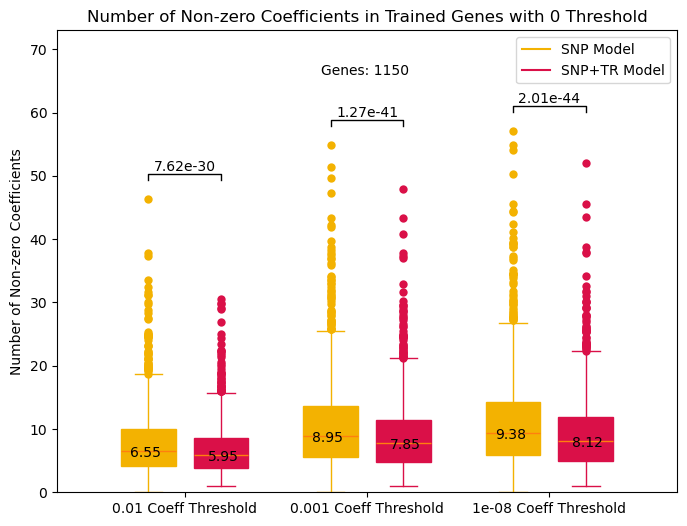

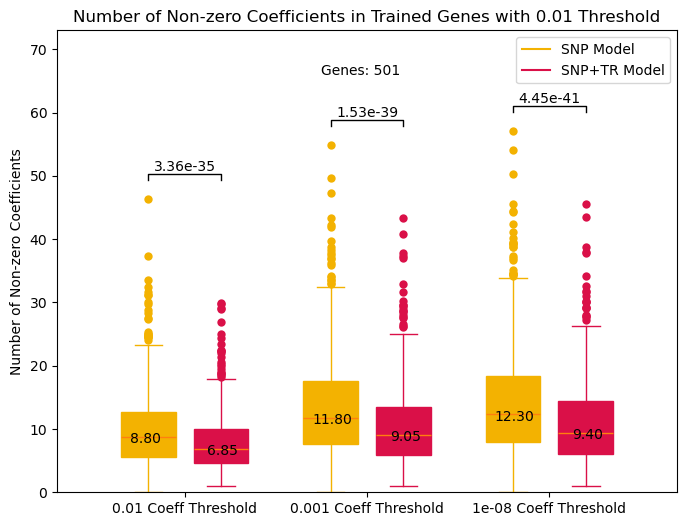

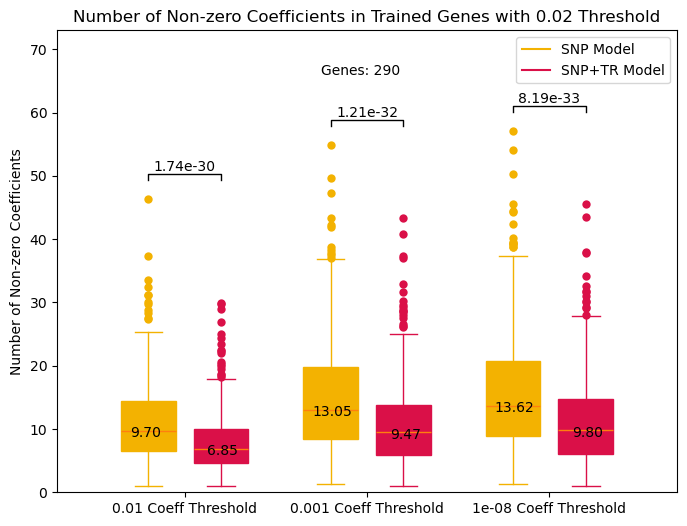

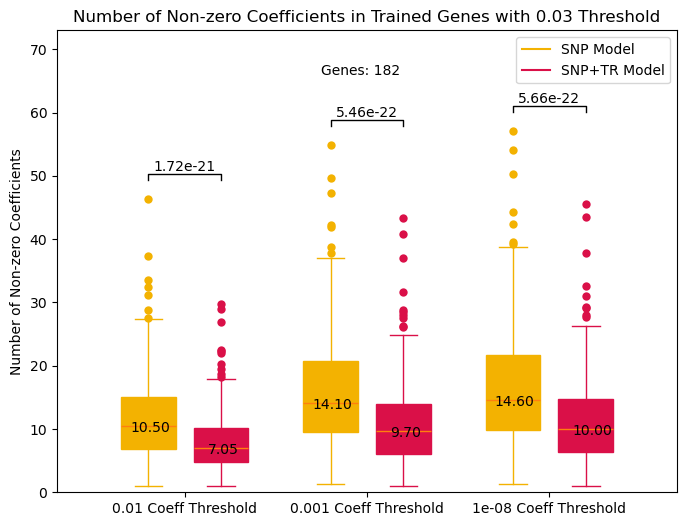

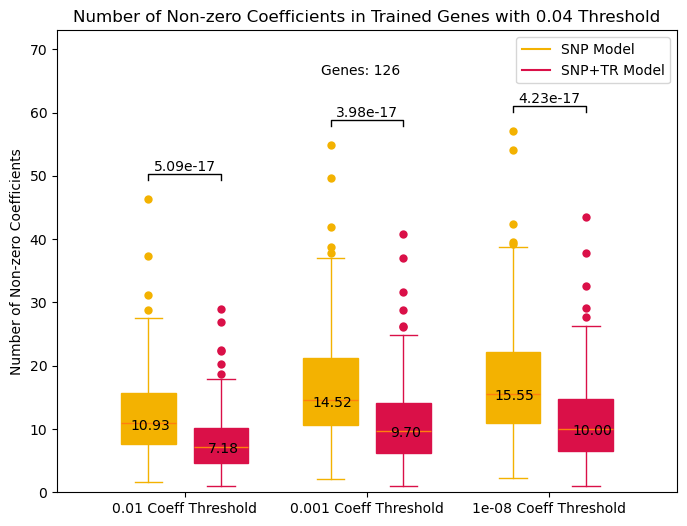

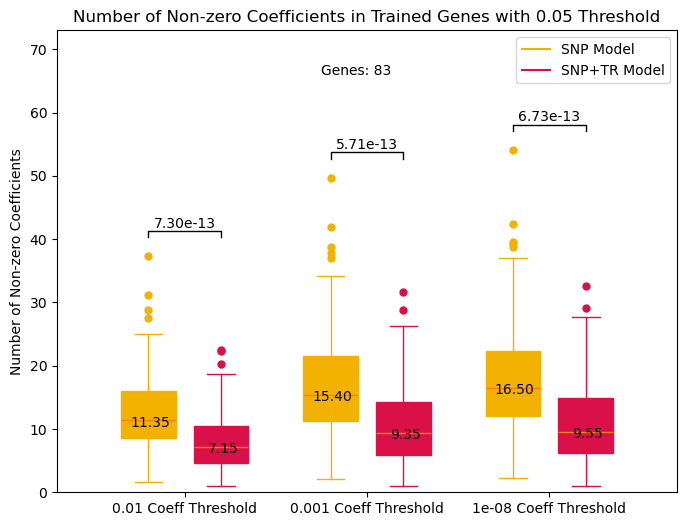

In [53]:
%matplotlib inline
# Create box plots where Y-axis is the number of coefficients and X-axis are each threshold size (For each threshold size plot SNP only and SNP+TR model right next to one another to show how they improve)
# This is to show that across each threshold we have an average decrease in coefficients in TR models 

for thresh in [0, 0.01, 0.02, 0.03, 0.04, 0.05]:
    title = f'Number of Non-zero Coefficients in Trained Genes with {thresh} Threshold'
    output = f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/simpler_models_trained_genes_{thresh}_threshold_comparison.pdf"
    filtered_trained_rsq_df = trained_rsq_df[trained_rsq_df['adj_rsq_diff'] > thresh]
    minimum_coeff_size_box_plots(filtered_trained_rsq_df, title, output)

/storage/mlamkin/tmp/ipykernel_1742/3591318995.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


2.011706466105232e-44


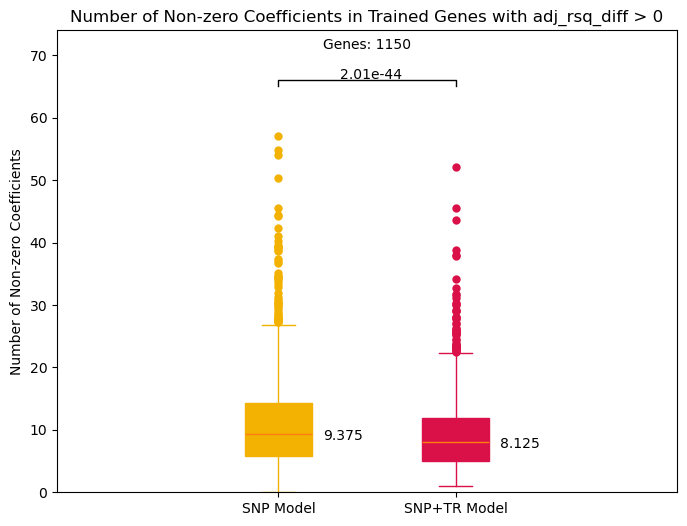

In [44]:
#### Make plot with only 1e-08 threshold ####
%matplotlib inline
# Create box plots where Y-axis is the number of coefficients and X-axis are each threshold size (For each threshold size plot SNP only and SNP+TR model right next to one another to show how they improve)
# This is to show that across each threshold we have an average decrease in coefficients in TR models 

filtered_trained_rsq_df = trained_rsq_df[trained_rsq_df['adj_rsq_diff'] > 0]
title = 'Number of Non-zero Coefficients in Trained Genes with adj_rsq_diff > 0'

# Plot all genes with eSTRs with color
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title(title)
ax.set_ylim((0,74))
ax.set_ylabel('Number of Non-zero Coefficients')

box = ax.boxplot(
    [
        filtered_trained_rsq_df['EUR_SNP_avg_coeff_1e-08'],
        filtered_trained_rsq_df['EUR_SNP_STR_avg_coeff_1e-08']
    ],
    positions=[0.8,1.2],
    labels=['SNP Model', 'SNP+TR Model'],
    patch_artist=True,
    flierprops=dict(markeredgewidth=0),
)

colors = [
    snp_model_color,
    snp_tr_model_color
] 

# Change colors in boxplot
for entry in ['boxes', 'fliers']:
    for item, color in zip(box[entry], colors):
        if entry == 'fliers':
            item.set_markerfacecolor(color)
        else:
            plt.setp(item, color=color)

for entry in ['whiskers', 'caps']:
    for items, color in zip(zip(box[entry][::2],box[entry][1::2]),colors):
        plt.setp(items, color=color)

res1 = stats.wilcoxon(
    filtered_trained_rsq_df['EUR_SNP_avg_coeff_1e-08'],
    filtered_trained_rsq_df['EUR_SNP_STR_avg_coeff_1e-08'],
    alternative='greater'
)
print(res1.pvalue)
ax.plot(
    [0.8, 0.8, 1.2, 1.2],
    [65, 66, 66, 65],
    lw=1, 
    c='k'
)
ax.annotate(f"{res1.pvalue:.2e}", (0.94, 66.2))

# Plot Medians    
snp_median = np.median(filtered_trained_rsq_df['EUR_SNP_avg_coeff_1e-08'])
snp_tr_median = np.median(filtered_trained_rsq_df['EUR_SNP_STR_avg_coeff_1e-08'])

ax.annotate(f"{snp_median}", (0.9, snp_median-1))
ax.annotate(f"{snp_tr_median}", (1.3, snp_tr_median-1))

# Annotate Number of Genes
ax.annotate(f"Genes: {filtered_trained_rsq_df['EUR_SNP_avg_coeff_1e-08'].shape[0]}" ,(0.90, 71))

output = f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/heritable_main_figure_simpler_models_comparison.pdf"
fig.savefig(output)
fig.show()

#### ii. Box plot of number of features for SNP only vs SNP+STR (#)

/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Lasso from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/storage/mlamkin/tmp/ipykernel_31884/1822273878.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trained_rsq_df["Num_SNPs"] = SNP_features
/storage/mlamkin/tmp/ipykernel_31884/1822273878.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value ins

5.751596864962557e-190


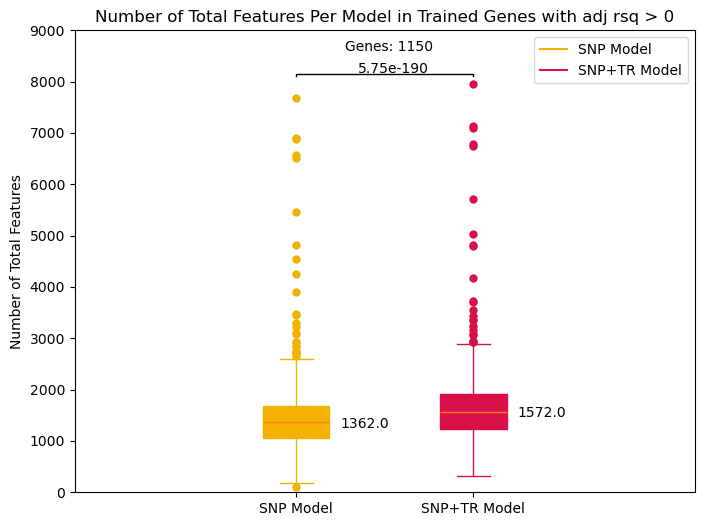

In [7]:
%matplotlib inline

# IE plot number of SNPs vs # SNPs + STRs 
output = '/storage/mlamkin/data/GeneExprPredictor/paper_figures/Models_Total_Coeff_Comparison_eSTR_Genes.pdf'

# load model files and grab coeffs
def load_model_coeffs(model_file):
    with open(model_file, 'rb') as f:
        model = pickle.load(f) 

    return model.coef_

# feature numbers
SNP_features = []
SNP_TR_features = []

# Load Genes
gene_ids = trained_rsq_df['gene']

for gene_id in gene_ids:
    # Load models
    snp_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs.pkl"
    snp_tr_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs+STRs.pkl"

    # Save coefficients
    try:
        SNP_features.append(load_model_coeffs(snp_model_file).shape[0])
        SNP_TR_features.append(load_model_coeffs(snp_tr_model_file).shape[0])
    except:
        continue

# Add num_features into trained_rsq_df
trained_rsq_df["Num_SNPs"] = SNP_features
trained_rsq_df["Num_TRs"] = np.array(SNP_TR_features) - np.array(SNP_features)

filtered_trained_rsq_df = trained_rsq_df[trained_rsq_df['adj_rsq_diff'] > 0]
SNP_features = filtered_trained_rsq_df['Num_SNPs']
SNP_TR_features = np.array(filtered_trained_rsq_df['Num_SNPs']) + np.array(filtered_trained_rsq_df["Num_TRs"])

# Plot boxplot
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title('Number of Total Features Per Model in Trained Genes with adj rsq > 0')
ax.set_ylabel('Number of Total Features')

snp_box = ax.boxplot(
    [
        SNP_features,
    ],
    positions=[0.8],
    labels=['SNP Model'],
    patch_artist=True,
    flierprops=dict(markeredgewidth=0),
)

tr_box = ax.boxplot(
    [
        SNP_TR_features,
    ],
    positions=[1.2],
    labels=['SNP+TR Model'],
    patch_artist=True,
    flierprops=dict(markeredgewidth=0),
)
ax.set_ylim(0,9000)

for box, color, label in zip([snp_box, tr_box], [snp_model_color, snp_tr_model_color], ["SNP Model", "SNP+TR Model"]):
    ax.plot([], c=color, label=label)
    ax.legend()
    # Change colors in boxplot
    for entry in ['boxes', 'fliers']:
        for item in box[entry]:
            if entry == 'fliers':
                item.set_markerfacecolor(color)
            else:
                plt.setp(item, color=color)

    for entry in ['whiskers', 'caps']:
        for items in zip(box[entry][::2],box[entry][1::2]):
            plt.setp(items, color=color)
    
res1 = stats.wilcoxon(
    SNP_features,
    SNP_TR_features,
    alternative='less'
)
print(res1.pvalue)
ax.plot(
    [0.8, 0.8, 1.2, 1.2],
    [8100, 8150, 8150, 8100],
    lw=1, 
    c='k'
)
ax.annotate(f"{res1.pvalue:.2e}", (0.94, 8160))

# Plot Medians
snp_median = np.median(SNP_features)
snp_tr_median = np.median(SNP_TR_features)

ax.annotate(f"{snp_median}", (0.9, snp_median-100))
ax.annotate(f"{snp_tr_median}", (1.3, snp_tr_median-100))

# Annotate Number of Genes
ax.annotate(f"Genes: {filtered_trained_rsq_df.shape[0]}" ,(0.91, 8600))

fig.savefig(output)
fig.show()


In [8]:
# Output table to be put in google sheet (NOTE Requires cells above to be run)
#      Cols: # SNP features, # TR features, # nonzero coeffs, hsq, hsq.pvalue, SNP_rsq_mean, SNP_TR_rsq_mean, AFR_SNP_rsq, AFR_SNP_TR_rsq, EUR Gain, AFR Gain, SNP Portability, SNP TR 
output_table_df = trained_rsq_df[[
    'gene_name',
    'gene',
    'Num_SNPs',
    'Num_TRs',
    'EUR_SNP_avg_coeff_1e-08',
    'EUR_SNP_STR_avg_coeff_1e-08',
    'hsq',
    'hsq.pv',
    'EUR_SNP_adj_R_sq_Mean',
    'EUR_SNP_STR_adj_R_sq_Mean',
    'EUR_nonlinear_adj_R_sq_Mean',
    'AFR_SNP_R_sq',
    'AFR_SNP_STR_R_sq',
    'AFR_nonlinear_R_sq',
    'adj_EUR_gain',
    'AFR_gain',
]]
outfile = '/storage/mlamkin/data/GeneExprPredictor/paper_figures/trained_genes_table.csv'
output_table_df.to_csv(outfile, index=False)


#### iii. Top Coefficient Values Boxplot

/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Lasso from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/storage/mlamkin/tmp/ipykernel_1742/3516586130.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  snp_box = ax.boxplot(
/storage/mlamkin/tmp/ipykernel_1742/3516586130.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  tr_box = ax.boxplot(


0.0844006509777036


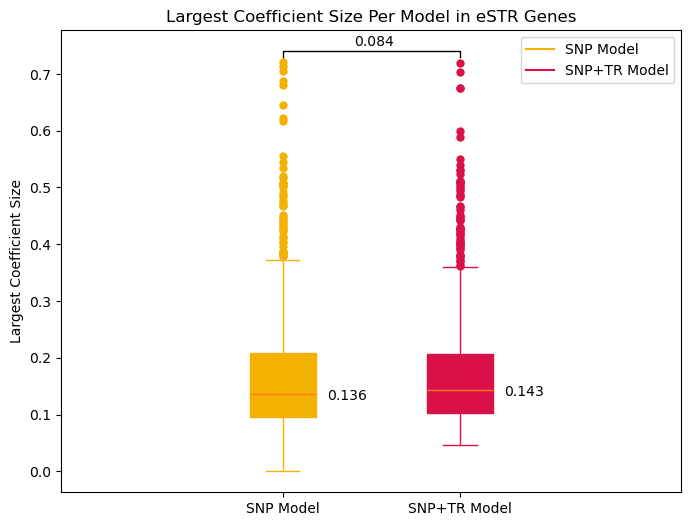

In [48]:
%matplotlib inline

output = '/storage/mlamkin/data/GeneExprPredictor/paper_figures/Models_Largest_Coeff_Comparison_eSTR_Genes.png'

# load model files and grab coeffs
def load_model_coeffs(model_file):
    with open(model_file, 'rb') as f:
        model = pickle.load(f)

    return model.coef_

# feature numbers
SNP_features = []
SNP_TR_features = []

# Load Genes
filtered_trained_rsq_df = trained_rsq_df[trained_rsq_df['adj_rsq_diff'] > 0]
gene_ids = filtered_trained_rsq_df['gene']

for gene_id in gene_ids:
    # Load models
    snp_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs.pkl"
    snp_tr_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs+STRs.pkl"

    # Save coefficients
    try:
        SNP_features.append(max(np.absolute(load_model_coeffs(snp_model_file))))
        SNP_TR_features.append(max(np.absolute(load_model_coeffs(snp_tr_model_file))))
    except:
        continue

SNP_features = np.array(SNP_features, dtype=np.float32)
SNP_TR_features = np.array(SNP_TR_features, dtype=np.float32)

# Plot boxplot
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title('Largest Coefficient Size Per Model in eSTR Genes')
ax.set_ylabel('Largest Coefficient Size')

snp_box = ax.boxplot(
    [
        SNP_features,
    ],
    positions=[0.8],
    labels=['SNP Model'],
    patch_artist=True,
    flierprops=dict(markeredgewidth=0),
)

tr_box = ax.boxplot(
    [
        SNP_TR_features
    ],
    positions=[1.2],
    labels=['SNP+TR Model'],
    patch_artist=True,
    flierprops=dict(markeredgewidth=0),
)

for box, color, label in zip([snp_box, tr_box], [snp_model_color, snp_tr_model_color], ["SNP Model", "SNP+TR Model"]):
    ax.plot([], c=color, label=label)
    ax.legend()
    # Change colors in boxplot
    for entry in ['boxes', 'fliers']:
        for item in box[entry]:
            if entry == 'fliers':
                item.set_markerfacecolor(color)
            else:
                plt.setp(item, color=color)

    for entry in ['whiskers', 'caps']:
        for items in zip(box[entry][::2],box[entry][1::2]):
            plt.setp(items, color=color)

res1 = stats.wilcoxon(
    SNP_features,
    SNP_TR_features,
    alternative='less'
)
print(res1.pvalue)

ax.plot(
    [0.8, 0.8, 1.2, 1.2],
    [0.73, 0.74, 0.74, 0.73],
    lw=1, 
    c='k'
)
ax.annotate(f"{res1.pvalue:.3f}", (0.96, 0.75))

# Plot Medians
snp_median = np.median(SNP_features)
snp_tr_median = np.median(SNP_TR_features)

ax.annotate(f"{snp_median:.3f}", (0.9, snp_median-.01))
ax.annotate(f"{snp_tr_median:.3f}", (1.3, snp_tr_median-.01))
    
fig.savefig(output)
fig.show()

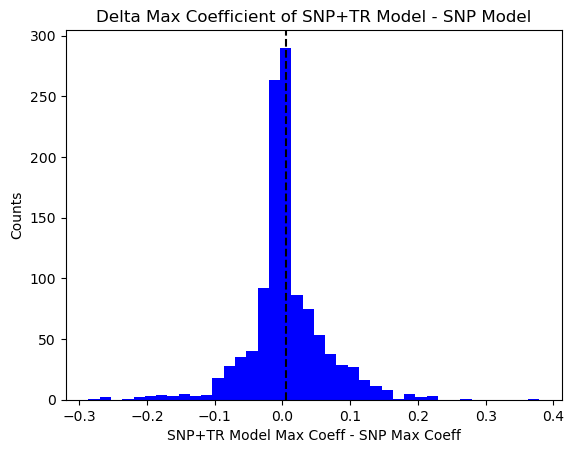

In [49]:
%matplotlib inline

output = '/storage/mlamkin/data/GeneExprPredictor/paper_figures/Models_Delta_Largest_Coeff_Distribution_eSTR_Genes.png'

# Distribution version of delta top coeff
delta_max_coeff = SNP_TR_features - SNP_features

fig = plt.figure()
ax = fig.add_subplot(1,1,1)
ax.set_title("Delta Max Coefficient of SNP+TR Model - SNP Model")
ax.set_xlabel("SNP+TR Model Max Coeff - SNP Max Coeff")
ax.set_ylabel("Counts")
ax.hist(delta_max_coeff, bins=40, color='blue')
ax.axvline(delta_max_coeff.mean(), color='k', linestyle="dashed")
fig.savefig(output)
fig.show()

In [17]:
##########  Collect Number of Nonzero Coefficients for SNPs and TRs  ##########
# Iterate over each gene and load each gene model coefficients

# load model files and grab coeffs
def load_model_coeffs(model_file):
    with open(model_file, 'rb') as f:
        model = pickle.load(f)

    return model.coef_

# feature numbers
SNP_features = []
SNP_TR_num_snps = []
SNP_TR_num_trs = []

# Load Genes
gene_ids = trained_rsq_df['gene']

for gene_id in gene_ids:
    # Load models
    snp_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs.pkl"
    snp_tr_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs+STRs.pkl"

    snp_coeffs = np.absolute(load_model_coeffs(snp_model_file))
    snp_tr_coeffs = np.absolute(load_model_coeffs(snp_tr_model_file))

    # Grab number of nonzero snp coeffs
    SNP_features.append(np.sum(snp_coeffs > 0))

    # Collect number of nonzero SNPs separately from number of nonzero TRs in SNP+TR Model
    SNP_TR_num_snps.append(np.sum(snp_tr_coeffs[:len(snp_coeffs)] > 0)) 
    SNP_TR_num_trs.append(np.sum(snp_tr_coeffs[len(snp_coeffs):] > 0))

# Output 
trained_rsq_df['best_SNP_model_num_coeff'] = SNP_features
trained_rsq_df['best_SNP_TR_model_num_snps'] = SNP_TR_num_snps
trained_rsq_df['best_SNP_TR_model_num_trs'] = SNP_TR_num_trs

outfile = '/storage/mlamkin/data/GeneExprPredictor/paper_figures/Geuv_trained_models_num_features.csv'
trained_rsq_df[['gene', 'best_SNP_model_num_coeff', 'best_SNP_TR_model_num_snps', 'best_SNP_TR_model_num_trs']].to_csv(outfile, index=False)


/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Lasso from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/storage/mlamkin/tmp/ipykernel_3877/163539247.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trained_rsq_df['best_SNP_model_num_coeff'] = SNP_features
/storage/mlamkin/tmp/ipykernel_3877/163539247.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer]

### Ball and Stick SNP vs SNP+TR Model Coefficient Comparison

In [21]:
def plot_model_coeffs(
    model_file, 
    gene_expr_predictor, 
    gene_id,
    ax, 
    orientation=1,
    gts=None,
    expr=None,
    gene_name=None,
    afr_gts=None,
    afr_expr=None,
    tr_coeff_file=None,
):
    # Load prior trained models
    with open(model_file, 'rb') as f:
        model = pickle.load(f)

    coeff = model.coef_

    # Grab all nonzero coefficients
    coef_filter, var_coef_filter, num_nonzero_coeff = gene_expr_predictor.nonzero_coeff_filter(
        coeff, gene_id, 0.01
    )

    # Filtered variants
    num_snps = len(gene_expr_predictor.snp_variants[gene_id])
    num_trs = len(gene_expr_predictor.str_variants[gene_id])
    wanted_vars = num_snps + num_trs
    var_coef_filter = var_coef_filter[:wanted_vars]
    vars = gene_expr_predictor.variants[gene_id][:wanted_vars]
    snp_nonzero_vars = vars[:num_snps][var_coef_filter[:num_snps]]
    tr_nonzero_vars = vars[num_snps:][var_coef_filter[num_snps:]]
    training_boundary = [vars[0][2], vars[-1][2]]
    #nonzero_vars = vars[var_coef_filter] # print this out to know what the nonzero vars are

    # Filtered Coefficients
    snp_coeffs = coeff[:num_snps]
    snp_coeffs = snp_coeffs[coef_filter[:num_snps]]
    tr_coeffs = coeff[num_snps:]
    tr_coeffs = tr_coeffs[coef_filter[num_snps:]]

    # Plot strongest TR coefficient
    if (gts is not None) and (expr is not None):
        # Find TR using tr_coeffs index and plot
        best_tr_inds = np.arange(coeff[num_snps:].shape[0])
        best_tr_inds = best_tr_inds[np.abs(coeff[num_snps:]) > 0] + num_snps

        for best_tr_ind, best_tr_coeff in zip(best_tr_inds, tr_coeffs):
            if tr_coeff_file is not None:
                tr_coeff_file.write(f'{gene_name}\t{gene_id}\t{vars[best_tr_ind][1]}\t{vars[best_tr_ind][2]}\t{best_tr_coeff}\n')
            fig = plt.figure(figsize=(16,12))
            eTR_ax = fig.add_subplot(1,1,1)
            # Plot gts vs expression
            # Filter out genotypes > 500
            tr_gts = gts[:,best_tr_ind]
            mask = tr_gts < 500
            eTR_ax.scatter(tr_gts[mask], expr[mask], color='g')
            eTR_ax.set_title(f'{gene_name} {vars[best_tr_ind][1]} {vars[best_tr_ind][2]} coeff size: {best_tr_coeff:.4f} Gene Expr Association')
            eTR_ax.set_xlabel('TR Genotype (TR_1 + TR_2)')
            eTR_ax.set_ylabel('Gene Expression')
            outpath = f'/storage/mlamkin/data/GeneExprPredictor/paper_figures/{gene_name}/'
            fig.savefig(outpath + f'{gene_name}_{vars[best_tr_ind][1]}_{vars[best_tr_ind][2]}_best_tr_assoc.pdf')

            # afr and eur expression plot
            # TODO update AFR colors
            if (afr_gts is not None) and (afr_expr is not None):
                # Filter out gts > 500
                afr_tr_gts = afr_gts[:,best_tr_ind]
                afr_mask = afr_tr_gts < 500

                fig = plt.figure(figsize=(16,12))
                eTR_ax = fig.add_subplot(1,1,1)
                # Plot gts vs expression
                eTR_ax.scatter(tr_gts[mask], expr[mask], color=eur_color, label='EUR')
                eTR_ax.scatter(afr_tr_gts[afr_mask], afr_expr[afr_mask], color=afr_color, label='AFR')
                eTR_ax.set_title(f'{gene_name} {vars[best_tr_ind][1]} {vars[best_tr_ind][2]} AFR EUR Gene Expr Association')
                eTR_ax.set_xlabel('TR Genotype (TR_1 + TR_2)')
                eTR_ax.set_ylabel('Gene Expression')
                eTR_ax.legend(loc='upper right')
                outpath = f'/storage/mlamkin/data/GeneExprPredictor/paper_figures/{gene_name}/'
                fig.savefig(outpath + f'{gene_name}_{vars[best_tr_ind][1]}_{vars[best_tr_ind][2]}_afr_eur_tr_assoc.pdf')

    # So if np.sum(var_coef_filter[len(gene_expr_predictor.snp_variants[gene_name]):]) is > 0 then it contains STRs and you can add the additional search
    num_sig_strs = np.sum(var_coef_filter[len(gene_expr_predictor.snp_variants[gene_id]):])
    if num_sig_strs > 0:
        # Collect SNP and TR coords
        snp_coords = [coord[2] for coord in snp_nonzero_vars]
        tr_coords = [coord[2] for coord in tr_nonzero_vars]
        
        # End figure with SNP+STR on -Y-axis
        ax.scatter(snp_coords, orientation*np.abs(snp_coeffs), color=snp_color, s=20)
        ax.scatter(tr_coords, orientation*np.abs(tr_coeffs), color=tr_color, label=f"TR", s=20)
        ax.vlines(snp_coords, 0, orientation*np.abs(snp_coeffs), color='black', linestyle="dashed")
        ax.vlines(tr_coords, 0, orientation*np.abs(tr_coeffs), color='black', linestyle="dashed")
        ax.plot(
            [
                training_boundary[0],
                training_boundary[1]
            ], 
            [0,0], 
            color='black',
        )
        
    else:
        model_coords = [coord[2] for coord in snp_nonzero_vars]
        ax.scatter(model_coords, orientation*np.abs(snp_coeffs), color=snp_color, label=f"SNP", s=20)
        ax.vlines(model_coords, 0, orientation*np.abs(snp_coeffs), color='black', linestyle="dashed")
        ax.plot(
            [
                training_boundary[0],
                training_boundary[1]
            ], 
            [0,0], 
            color='black',
        )
    
    # Set Plot Limits
    ax.set_xlim(training_boundary)
    ax.set_ylim(-1, 1)

    chrom = vars[0][1]
    return chrom

def plot_coeff_comparison(
    gene_id, 
    gene_name,
    tss_start,
    tss_end,
    tss_strand,
    top_gene_expr_predictor,
    bot_gene_expr_predictor,
    top_file, 
    bot_file,
    output,
    afr_expr_predictor=None,
    tr_coeff_file=None,
    ax=None,
):
    eur_samples, header_genes = top_gene_expr_predictor.prepare_header_info(top_gene_expr_predictor.train_header_file)

    # Collect the variants
    train_dataset, train_expr = top_gene_expr_predictor.collect_gts_gene_expr(
        gene_id,
        500,
        header_genes,
        eur_samples,
        snp_variants=None,
        str_variants=None,
        expr_file=top_gene_expr_predictor.train_expr_file,
        header_file=top_gene_expr_predictor.train_header_file,
    )

    eur_variants = {}
    eur_vars = top_gene_expr_predictor.variants[gene_id][:train_dataset[1].shape[1]]
    for var_ind, var in enumerate(eur_vars):
        id = f"{var[0]}_{var[1]}_{var[2]}"
        eur_variants[id] = var_ind

    afr_gts = None
    afr_expr = None
    if afr_expr_predictor is not None:
        afr_samples, afr_header_genes = afr_expr_predictor.prepare_header_info(afr_expr_predictor.train_header_file)
        afr_dataset, afr_expr = afr_expr_predictor.collect_gts_gene_expr(
            gene_id,
            500,
            afr_header_genes,
            afr_samples,
            snp_variants=top_gene_expr_predictor.snp_variants[gene_id],
            str_variants=top_gene_expr_predictor.str_variants[gene_id],
            expr_file=afr_expr_predictor.train_expr_file,
            header_file=afr_expr_predictor.train_header_file,
        )

        afr_gts = np.zeros((afr_dataset[1].shape[0], train_dataset[1].shape[1]))
        afr_variants = afr_expr_predictor.variants[gene_id][:afr_dataset[1].shape[1]]
        for afr_ind, afr_var in enumerate(afr_variants):
            id = f"{afr_var[0]}_{afr_var[1]}_{afr_var[2]}"
            afr_gts[:,eur_variants[id]] = afr_dataset[1][:,afr_ind]

    if ax == None:
        fig = plt.figure(figsize=(16,12))
        ax = fig.add_subplot(1,1,1)
    ax.set_title(f"{gene_name} Coefficient Comparison")
    ax.set_ylabel("Lasso Model Coefficient Value")
        
    # Plot TSS start and end keeping account of strand orientation
    # Find where true gene start is based on strand
    if tss_strand == '+':
        gene_start = tss_start
        gene_end = tss_end
        dir = 1
    else:
        gene_start = tss_end
        gene_end = tss_start
        dir = -1
    
    # Plot an arrow for gene start
    ax.plot([gene_start, gene_start], [-0.02, 0.02], color='black')
    ax.annotate("", xy=(gene_start + (dir*20000), 0.02), xytext=(gene_start, 0.02),
            arrowprops=dict(arrowstyle="->"))

    # Plot end of gene
    ax.plot([gene_end, gene_end], [-0.02, 0.02], color='black')

    # grab coeffs from snp only model
    chrom = plot_model_coeffs(
        top_file, 
        top_gene_expr_predictor, 
        gene_id,
        ax,
    )
    
    ax.set_xlabel(f"{chrom} Coords")

    if top_gene_expr_predictor != bot_gene_expr_predictor:
        eur_samples, header_genes = bot_gene_expr_predictor.prepare_header_info(bot_gene_expr_predictor.train_header_file)

        # Collect the variants
        train_dataset, train_expr = bot_gene_expr_predictor.collect_gts_gene_expr(
            gene_id,
            500,
            header_genes,
            eur_samples,
            snp_variants=None,
            str_variants=None,
            expr_file=bot_gene_expr_predictor.train_expr_file,
            header_file=bot_gene_expr_predictor.train_header_file,
        )
    else:
        bot_gene_expr_predictor = top_gene_expr_predictor

    # Get coeff from snp_str model
    gts = None # TODO remove to plot gts vs expression
    train_expr = None
    chrom = plot_model_coeffs(
        bot_file, 
        bot_gene_expr_predictor, 
        gene_id,
        ax,
        orientation=-1, # If it will be on top or bottom of figure (-1 = bottom)
        gts=train_dataset[1], # 1 = snp + tr gts (0 = snp only, 2 = snp + tr + tr^2)
        expr=train_expr,
        gene_name=gene_name,
        afr_gts=afr_gts,
        afr_expr=afr_expr,
        tr_coeff_file=tr_coeff_file,
    )

    ax.legend()
    #fig.savefig(output)
    return

In [13]:
def ball_and_stick(gene_id, gene_name, ax=None, skip_genes=False, tr_coeff_file=None):
    if not os.path.exists(f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/{gene_name}/"):
        os.mkdir(f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/{gene_name}/")
    elif skip_genes:
        return

    # Load gene start and end coordinates
    TSS_file = "/storage/mlamkin/data/GeneExprPredictor/train_data/GRCh38_V38_TSS.tsv"
    TSS_df = pd.read_csv(TSS_file, delimiter='\t', usecols=['strand', 'name2'])
    TSS_df.columns = ['strand', 'gene']
    TSS_gene = TSS_df[TSS_df['gene'] == gene_name]
    strand = '+'
    try:
        strand = TSS_gene['strand'].iloc[0]
    except:
        print(f"Could not find strand orientation for gene: {gene_name} (Assuming '+' Direction)")

    # Load required genotypes and gene expression to collect coefficients
    #path = "/expanse/projects/gymreklab/mlamkin/" # Use for Expanse
    path = "/gymreklab-tscc/mlamkin/" # Use for Snorlax
    EUR_header_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_and_filtered_hg38.csv"
    EUR_expr_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_filtered_final_residuals_hg38.csv"
    AFR_header_file = path + "GeneExprPredictor_data/train_data/AFR_normalized_and_filtered_hg38.csv"
    AFR_expr_file = path + "GeneExprPredictor_data/train_data/AFR_normalized_filtered_final_residuals_hg38.csv"
    snp_file = path + "GeneExprPredictor_data/SNP_vcfs/SNP_{}_filtered.vcf.gz"
    str_file = path + "GeneExprPredictor_data/STR_vcfs/ensemble_{}_filtered.vcf.gz"

    # Load gene start and end
    gene_info_df = pd.read_csv(EUR_header_file, delimiter='\t', usecols=['start', 'end', 'gene_id'])
    gene_info_df['gene_id'] = gene_info_df['gene_id'].str.split('.').str[0]
    gene_info = gene_info_df[gene_info_df['gene_id'] == gene_id]
    gene_start = gene_info['start'].iloc[0] 
    gene_end = gene_info['end'].iloc[0] 

    # Load models
    snp_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs.pkl"
    snp_str_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs+STRs.pkl"

    sample_ind = 5 # NOTE for GTEx sample_ind is 4
    gene_id_ind = 3
    gene_chrom_ind = 0
    gene_start_ind = 1
    gene_end_ind = 2

    geuv_gene_expr_predictor = GeneExpressionPredictor(
        paramsearchfxn=None,
        model=None,
        model_params=None,
        hyperparams=None,
        gene_names=[gene_name],
        sample_ind=sample_ind,
        gene_id_ind=gene_id_ind,
        gene_chrom_ind=gene_chrom_ind,
        gene_start_ind=gene_start_ind,
        gene_end_ind=gene_end_ind,
        train_header_file=EUR_header_file,
        predict_header_file=None,
        snp_file=snp_file,
        str_file=str_file,
        train_expr_file=EUR_expr_file,
        predict_expr_file=None,
        param_shift=None,
        coeff_thresh=None,
        outpath=None,
        n_jobs=1,
        level="WARNING",
    )

    afr_gene_expr_predictor = None
    # afr_gene_expr_predictor = GeneExpressionPredictor(
    #     paramsearchfxn=None,
    #     model=None,
    #     model_params=None,
    #     hyperparams=None,
    #     gene_names=[gene_name],
    #     sample_ind=sample_ind,
    #     gene_id_ind=gene_id_ind,
    #     gene_chrom_ind=gene_chrom_ind,
    #     gene_start_ind=gene_start_ind,
    #     gene_end_ind=gene_end_ind,
    #     train_header_file=AFR_header_file,
    #     predict_header_file=None,
    #     snp_file=snp_file,
    #     str_file=str_file,
    #     train_expr_file=AFR_expr_file,
    #     predict_expr_file=None,
    #     param_shift=None,
    #     coeff_thresh=None,
    #     outpath=None,
    #     n_jobs=1,
    #     level="WARNING",
    # )

    plot_coeff_comparison(
        gene_id,
        gene_name,
        gene_start,
        gene_end,
        strand,
        geuv_gene_expr_predictor,
        geuv_gene_expr_predictor,
        top_file=snp_model_file,
        bot_file=snp_str_model_file,
        output=f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/{gene_name}/{gene_name}_model_coefficient_comparison.pdf",
        afr_expr_predictor=afr_gene_expr_predictor,
        tr_coeff_file=tr_coeff_file,
        ax=ax
    )


Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
The current variant in the VCF only has one allele per sample.
The current variant in the VCF only has one allele per sample.
The current variant in the VCF only has one 

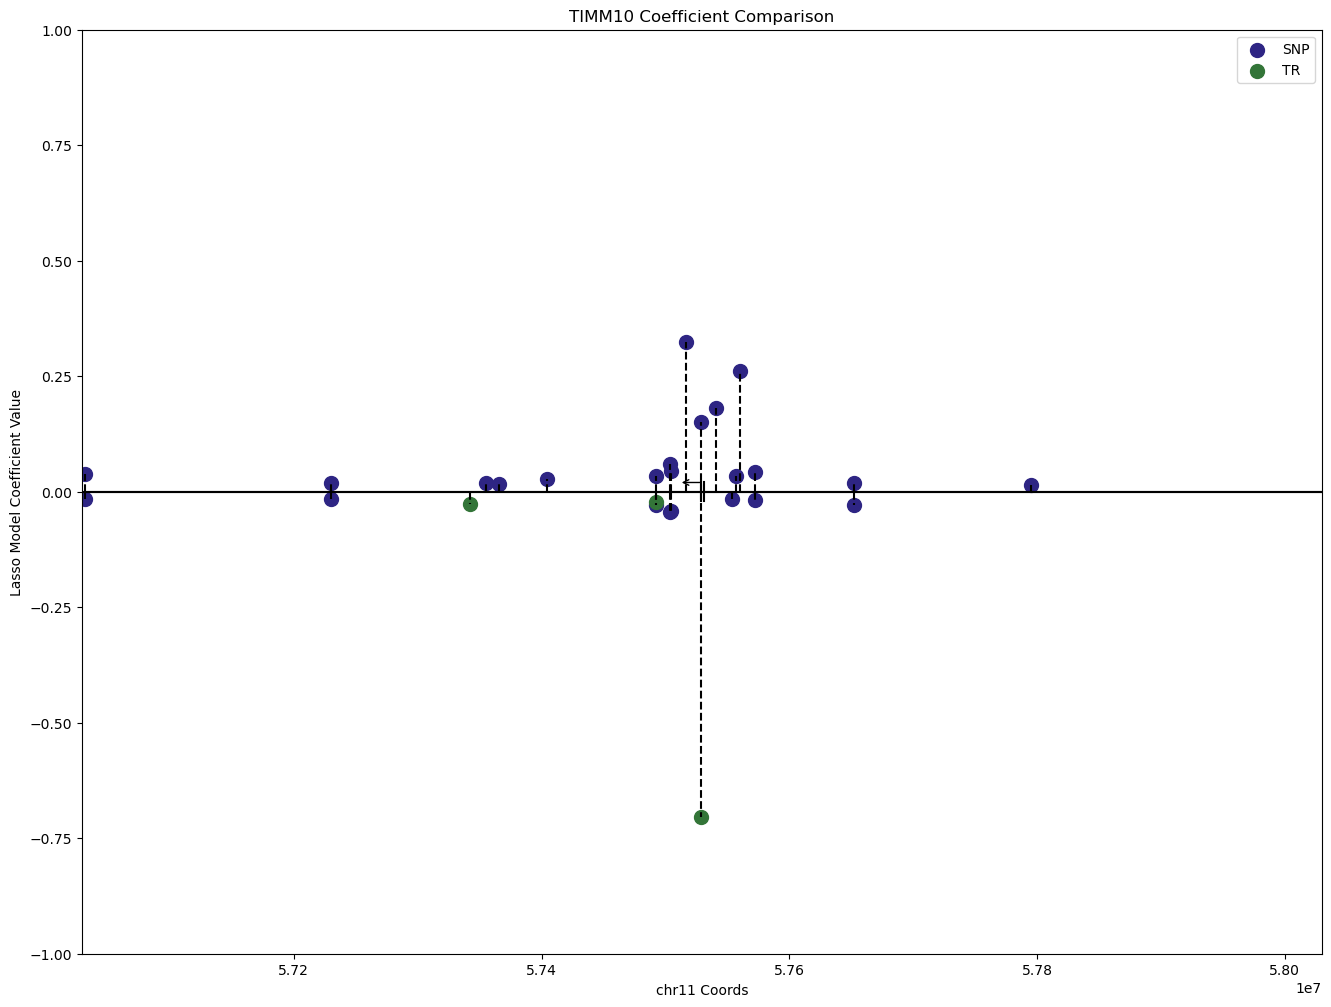

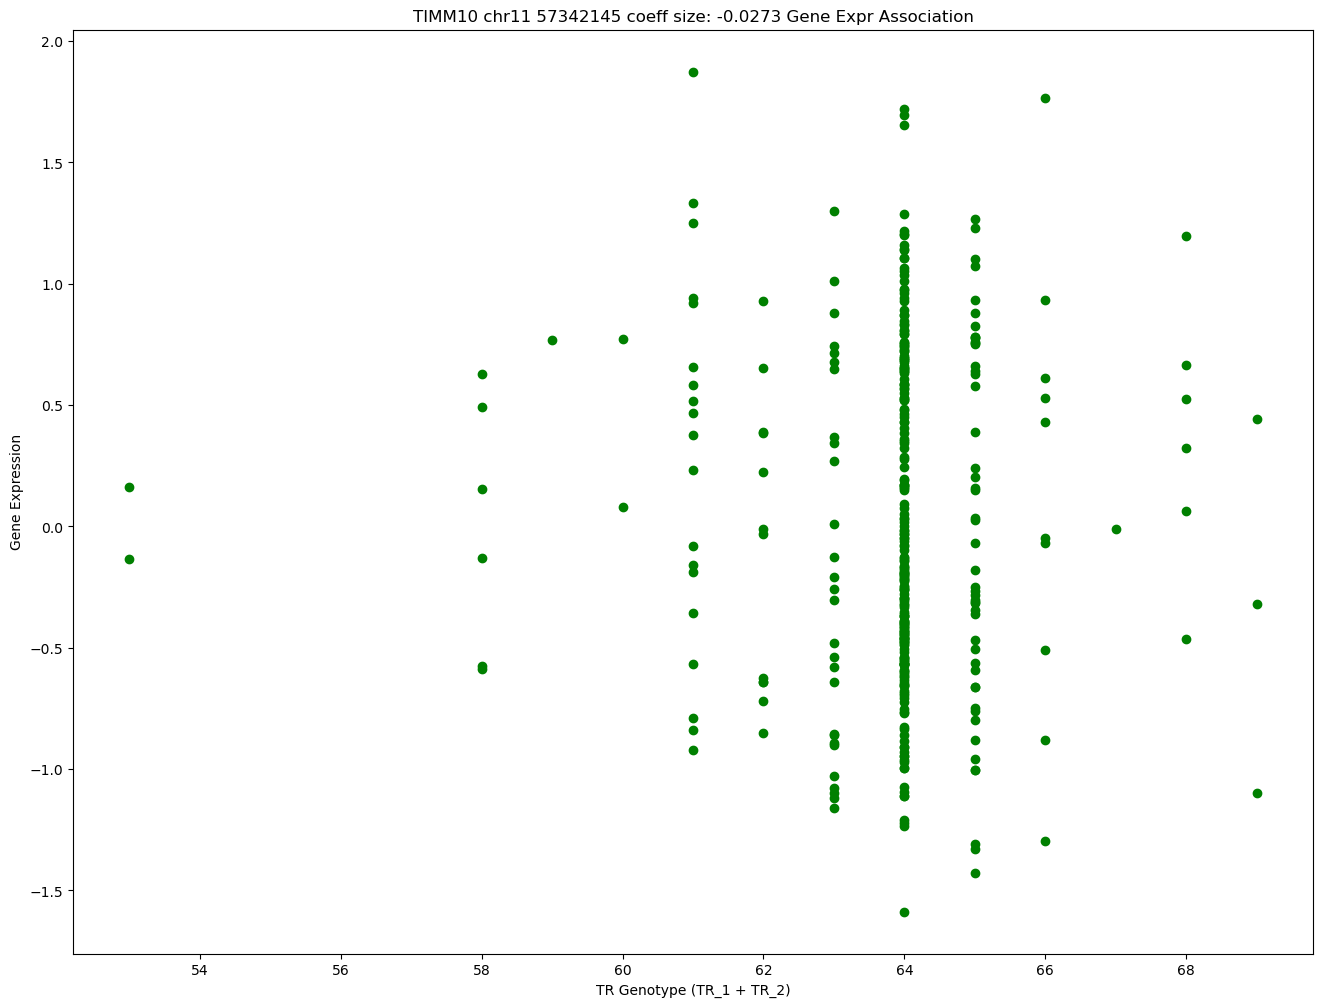

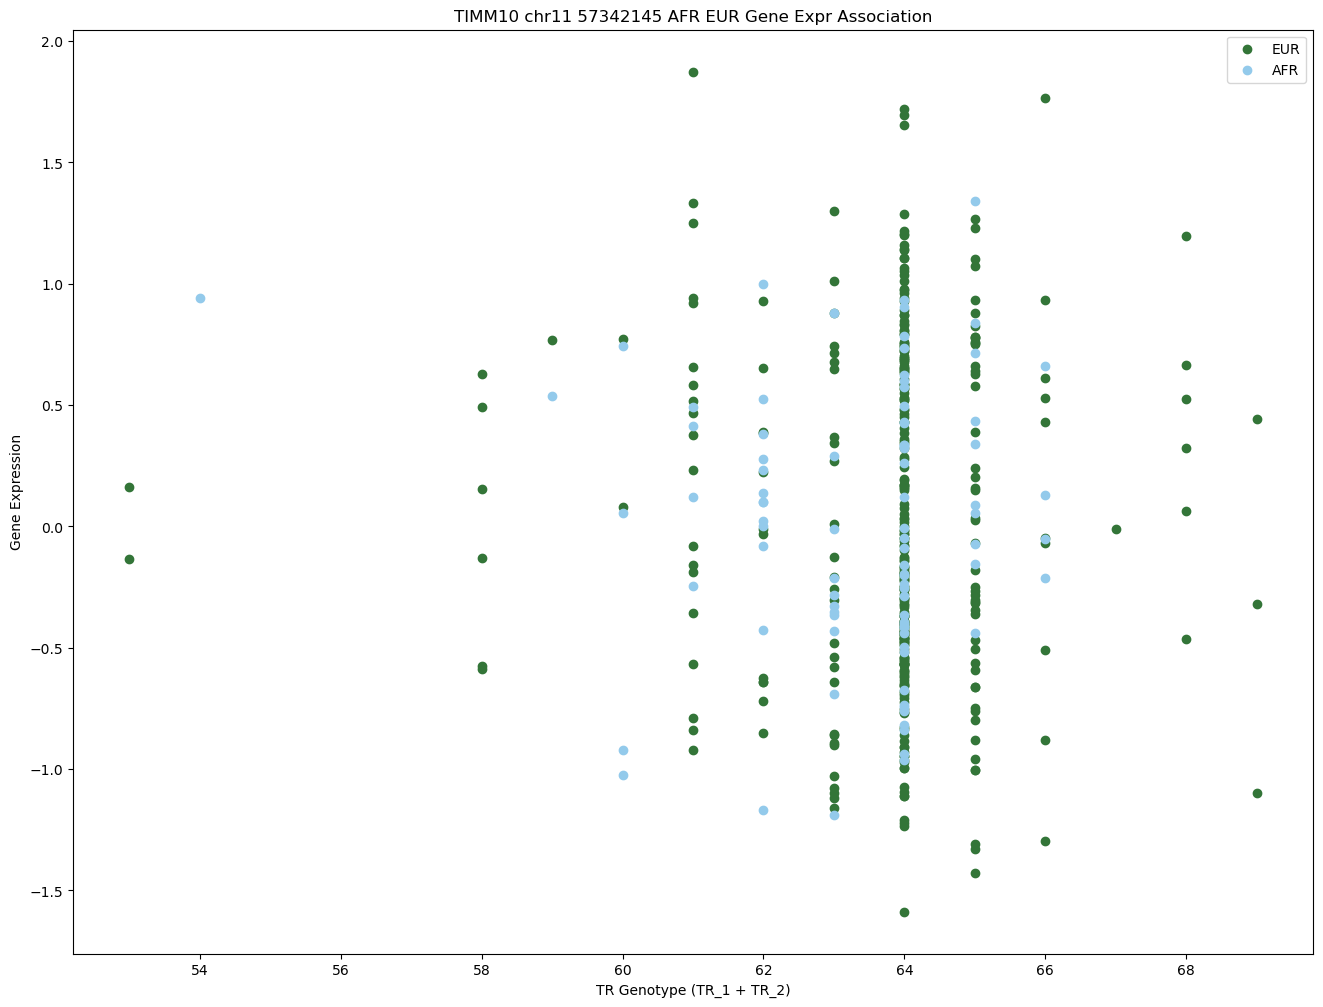

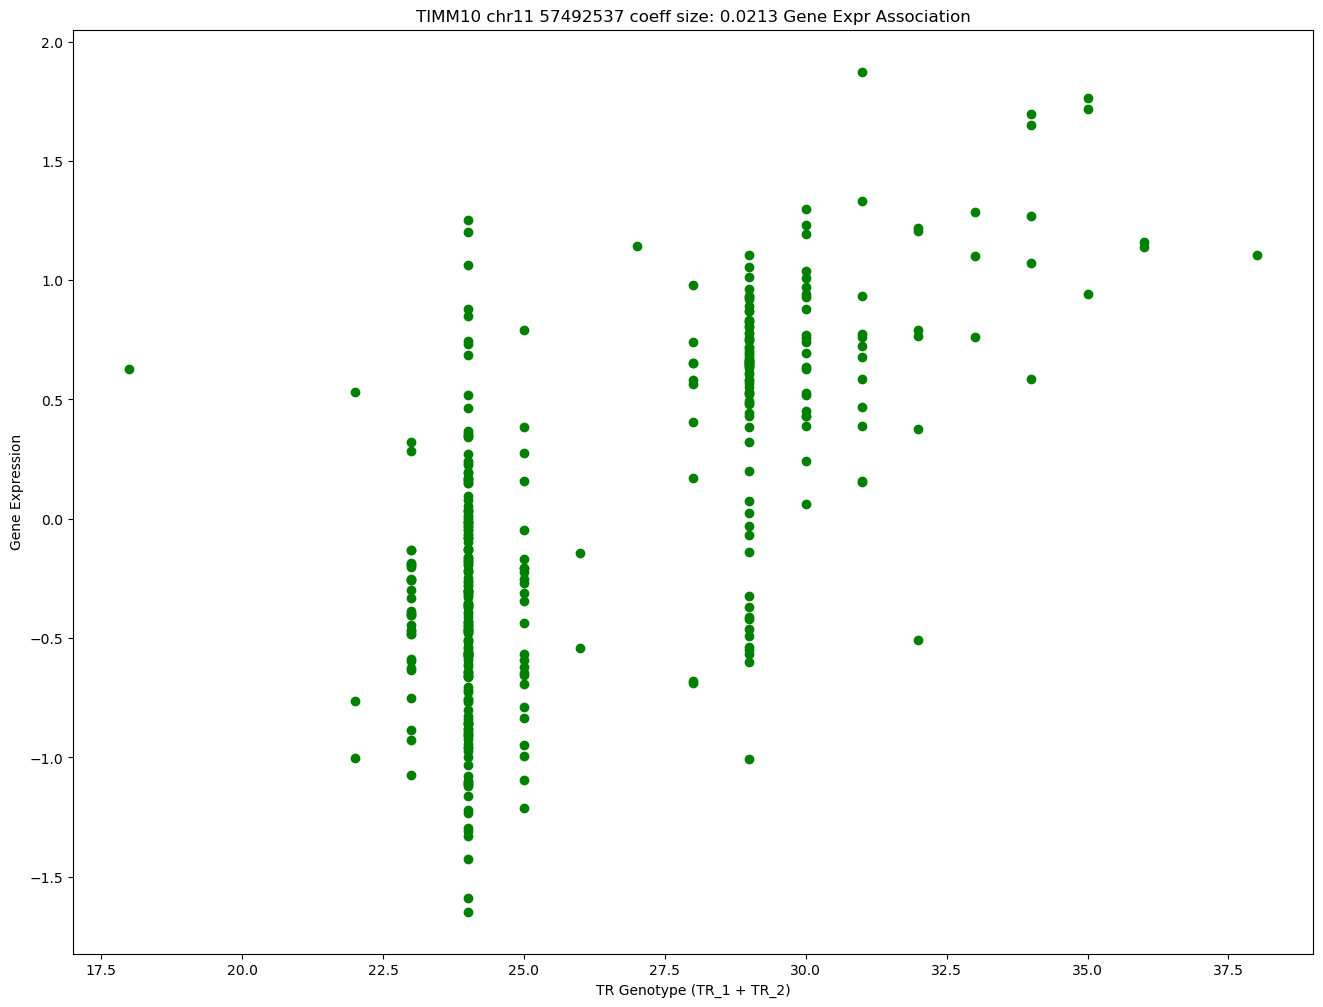

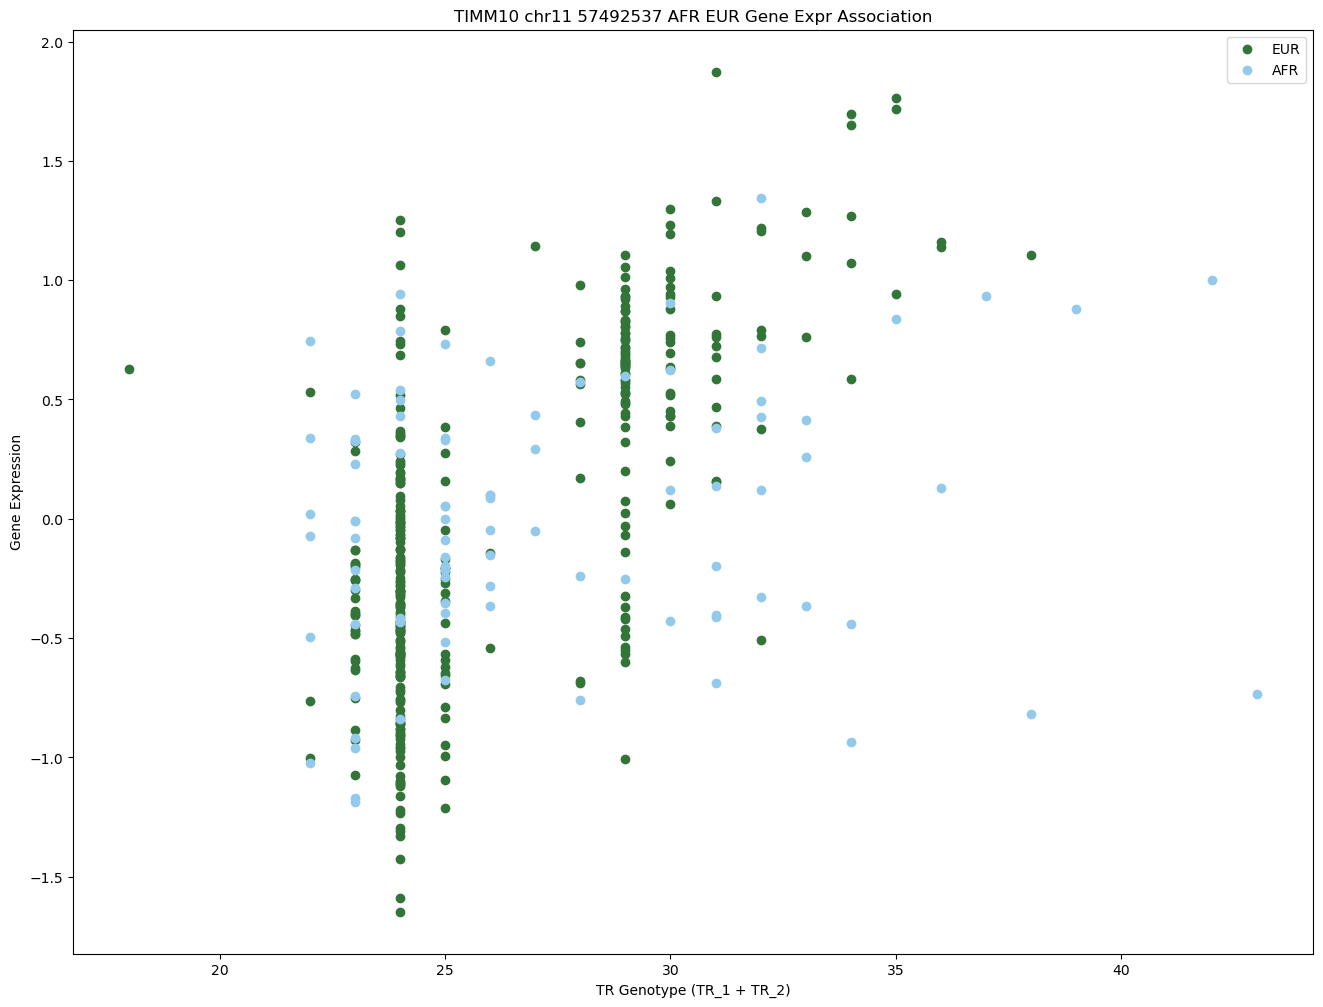

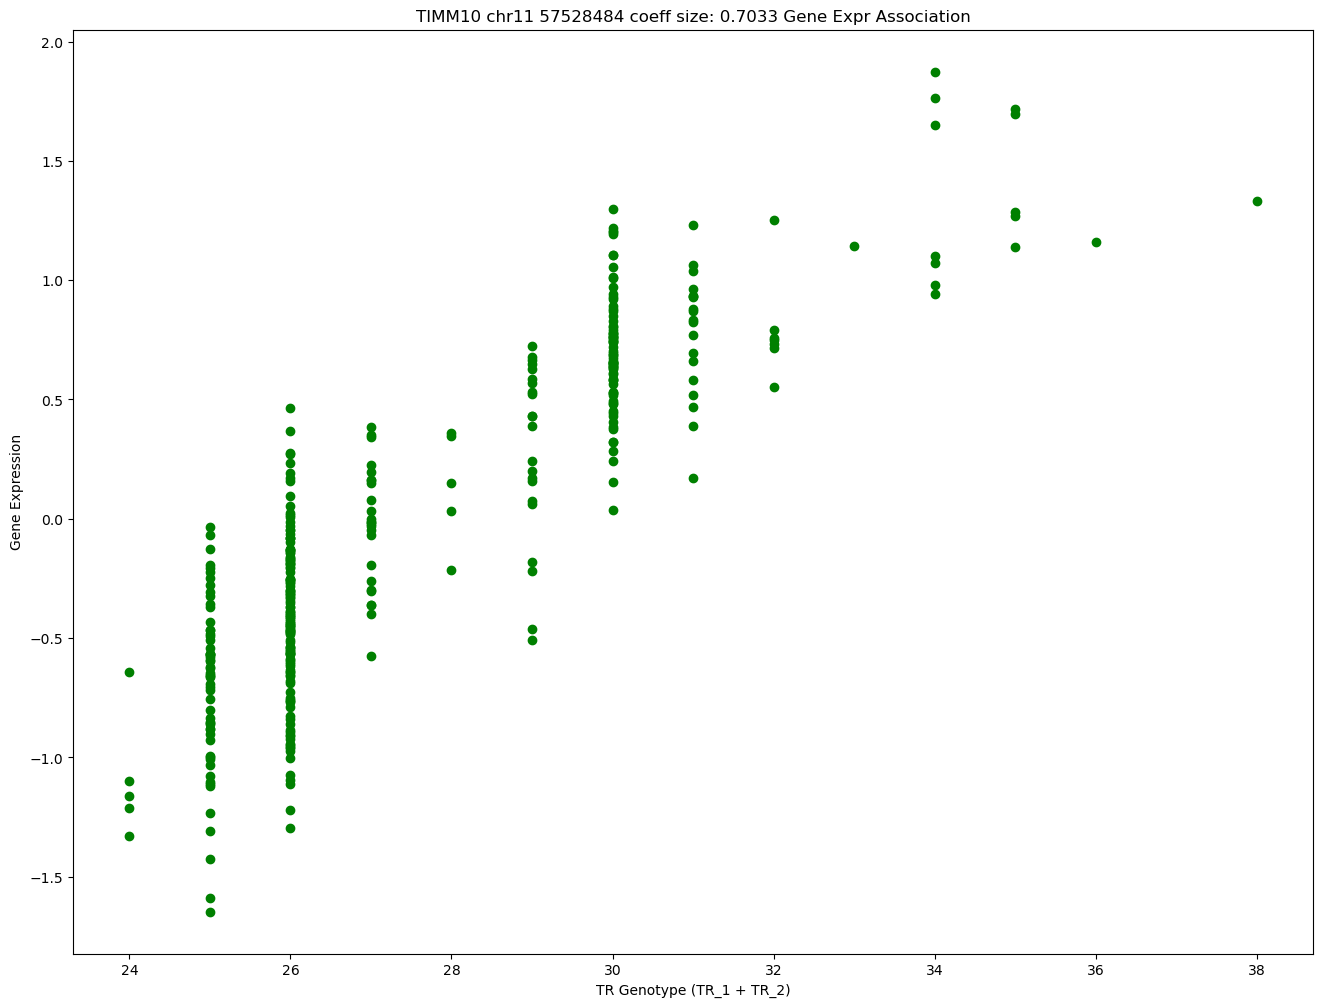

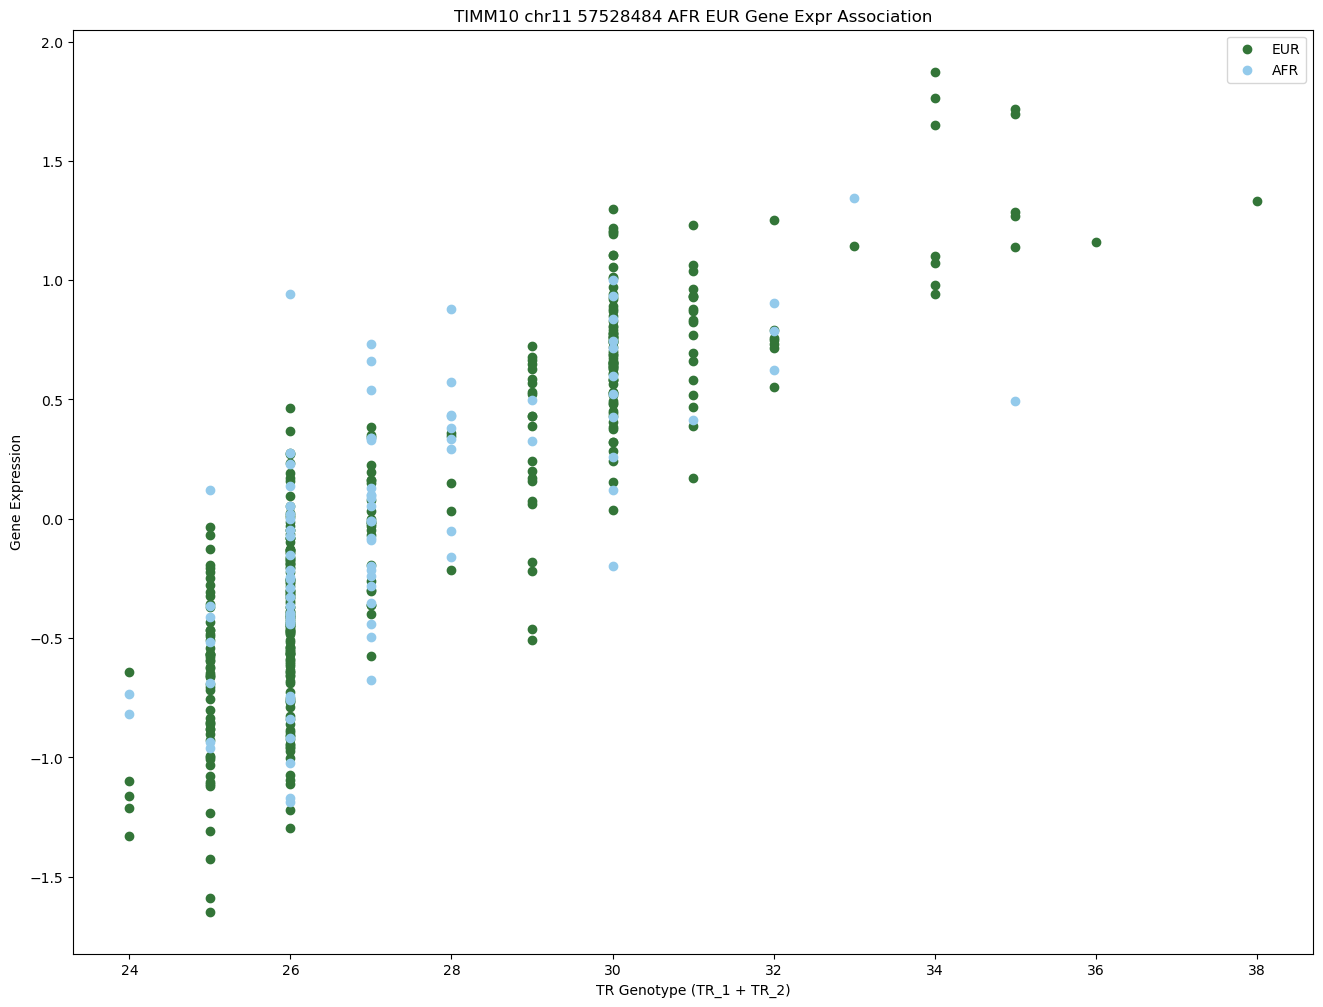

In [8]:
# Create expr and ball and stick plots for all 2533 genes
tr_coeff_output = "/storage/mlamkin/data/GeneExprPredictor/paper_figures/Trained_models_TR_coeffs.tsv"
with open(tr_coeff_output, 'w') as tr_coeff_file:
    tr_coeff_file.write(f'Gene_Name\tGene_ID\tChrom\tStart\tTR_Model_Coeff\n')
    for row_ind, row_info in trained_rsq_df[['gene_name', 'gene']].iterrows():
        ball_and_stick(row_info['gene'], row_info['gene_name'], skip_genes=False, tr_coeff_file=tr_coeff_file)

## Geuvadis and GTEx GTs vs Expression Box Plots

Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!


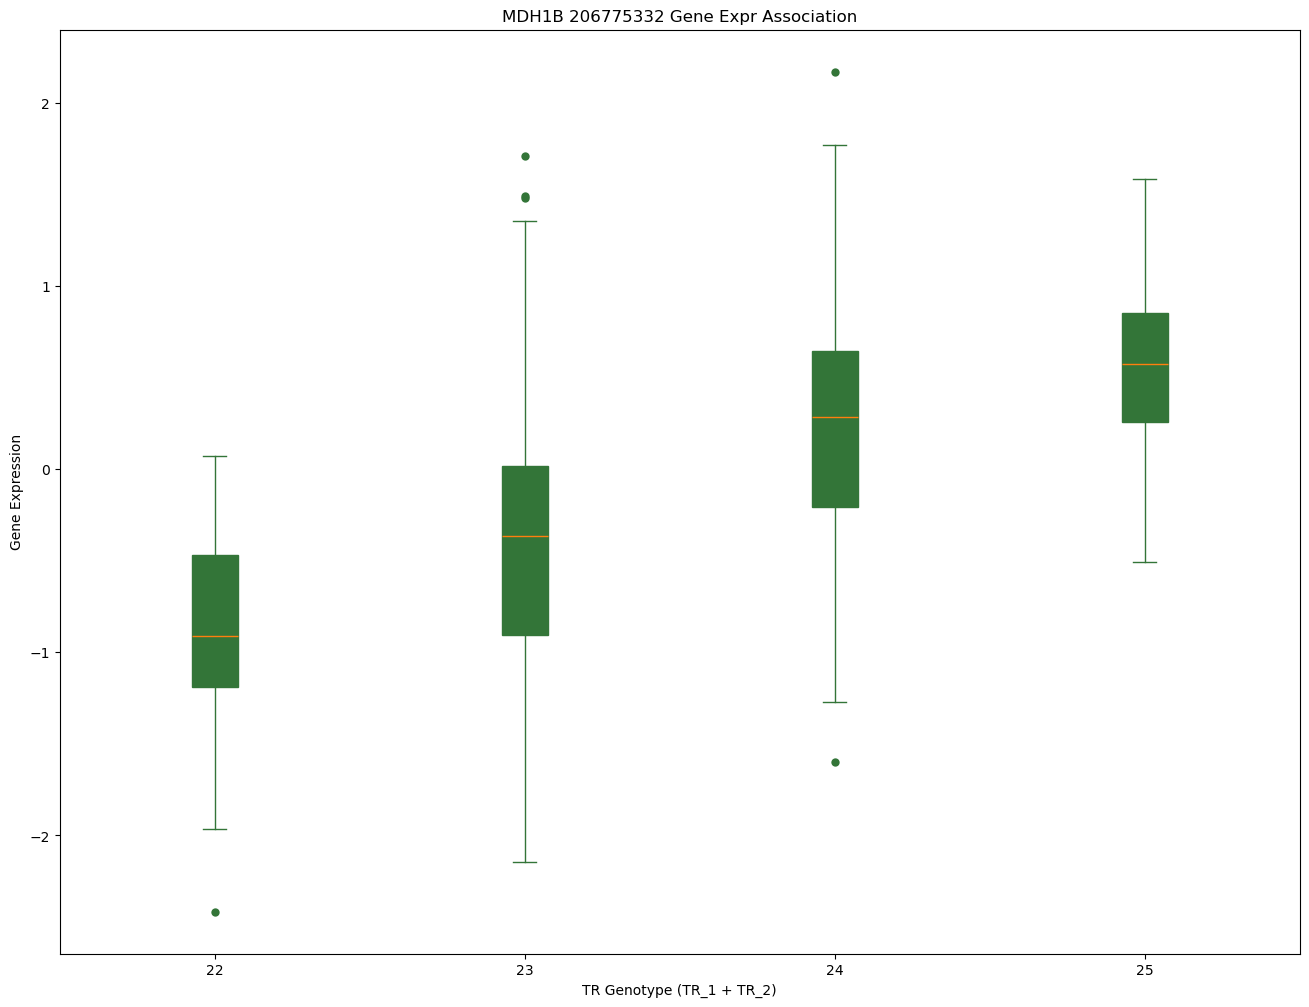

In [17]:
%matplotlib inline

from haptools.data import GenotypesTR

def filter_maf(gts, threshold=0.1):
    # filter maf 
    num_strands = 2 * gts.data.shape[0]
    common_variants = np.zeros((gts.data.shape[1],)).astype(np.bool_)
    # NOTE Uses Heterozygosity measure (1 - sum_i (freqs_i^2)) instead of MAF
    for variant in range(gts.data.shape[1]):
        v_data = gts.data[:, variant, :2]
        alleles, counts = np.unique(v_data, return_counts=True)
        sum_freq_sq = np.sum(np.square(counts/num_strands))
        heterozygosity = 1 - sum_freq_sq
        common_variants[variant] = heterozygosity > threshold
    gts.data = gts.data[:,common_variants,:]
    gts.variants = gts.variants[common_variants]
    return gts

def prepare_header_data(header_file, chrom=None, gene=None):
    # Collect samples names and gene names from original expression file EUR_normalized_and_filtered_hg38.csv
    header_data = np.loadtxt(header_file, delimiter="\t", dtype=str)
    eur_samples = list(header_data[0][5:])
    all_genes = header_data[1:,3]

    if gene:
        genes = [gene]
    elif chrom:
        genes = header_data[header_data[:,0] == chrom, 3]
    else:
        genes = header_data[1:,3]
    del header_data

    return eur_samples, all_genes, genes

def collect_gene_region(gene_name, dist):
    """
    Grab region spanning gene with a distance upstream and downstream from 
    gene region of length dist.
    eg. gene coordinates are chr10:1000000-1010000 and dist is 200kb
        region = chr10:800000-1210000

    Parameters
    ----------
    gene_name: str
        Name of gene to collect coordinates from header file
    dist: float
        Distance in kilobases upstream and downstream of gene to collect SNPs/STRs from

    Returns
    -------
    chrom: str
        chromosome of region used for grabbing correct file. eg. chr10
    region: str
        region to collect SNPs and STRs from eg. chr10:800000-1210000
    """
    header_data = np.loadtxt(header_file, delimiter="\t", dtype=str)[1:,:5]
    gene_data = header_data[header_data[:,3] == gene_name].flatten()
    chrom = gene_data[0]
    cis_dist = dist*1000
    region = f"{chrom}:{max(int(gene_data[2]) - cis_dist, 1)}-{int(gene_data[2]) + cis_dist}"
    return chrom, region

def prepare_gene_data(
    expr_file,
    str_file,
    gene_name,
    genes,
    samples,
    region=None,
    delimiter=" ",
    het_thresh=0.1,
    str_variants=None,
):
    # NOTE gene expression data normalized, filtered, and PEER factor residuals removed
    expr_data = np.loadtxt(expr_file, delimiter=delimiter, dtype=np.float32)
    gene_expr_data = expr_data[:, genes == gene_name].flatten()

    # Load STR Genotypes
    str_gts = GenotypesTR(str_file, vcftype='hipstr')
    str_gts.read(region=region, samples=samples, variants=str_variants)
    str_gts = filter_maf(str_gts, het_thresh)
    str_gts.subset(samples=samples, inplace=True)

    assert list(str_gts.samples) == samples

    return gene_expr_data, str_gts

def gt_box_plot(
    gts, 
    expr, 
    tr_loc, 
    gene_name
):
    fig = plt.figure(figsize=(16,12))
    eTR_ax = fig.add_subplot(1,1,1)
    # Plot gts vs expression
    # Filter out genotypes > 500
    mask = gts < 500
    filtered_gts = gts[mask]
    filtered_expr = expr[mask]
    for gt in np.unique(filtered_gts):
        gt_mask = filtered_gts == gt
        box = eTR_ax.boxplot(
            filtered_expr[gt_mask], 
            positions=[gt], 
            patch_artist=True,
            flierprops=dict(markeredgewidth=0),
        )
        colors = [tr_color]
        # Change colors in boxplot
        for entry in ['boxes', 'fliers']:
            for item, color in zip(box[entry], colors):
                if entry == 'fliers':
                    item.set_markerfacecolor(color)
                else:
                    plt.setp(item, color=color)

        for entry in ['whiskers', 'caps']:
            for items, color in zip(zip(box[entry][::2],box[entry][1::2]),colors):
                plt.setp(items, color=color)

    eTR_ax.set_title(f'{gene_name} {tr_loc} Gene Expr Association')
    eTR_ax.set_xlabel('TR Genotype (TR_1 + TR_2)')
    eTR_ax.set_ylabel('Gene Expression')
    #outpath = f'/storage/mlamkin/data/GeneExprPredictor/paper_figures/{gene_name}/'
    #fig.savefig(outpath + f'{gene_name}_{vars[best_tr_ind][1]}_{vars[best_tr_ind][2]}_best_tr_assoc.pdf')

path = "/gymreklab-tscc/mlamkin/" # Use for Snorlax
geuv_header_file = "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/train_data/EUR_normalized_and_filtered_hg38.csv"
geuv_EUR_expr_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_filtered_final_residuals_hg38.csv"
#gtex_EUR_expr_file = 
geuv_str_file = path + "GeneExprPredictor_data/STR_vcfs/ensemble_chr2_filtered.vcf.gz"

# Load TRs
# Do for MDH1B
gene_name = 'MDH1B'
gene_id = 'ENSG00000138400.8'
tr_loc = 206775332
gene_region = f"chr2:{tr_loc}-{tr_loc+1}"

eur_samples, all_genes, gene_names = prepare_header_data(geuv_header_file, "chr2")
gene_expr_res, all_str_gts = prepare_gene_data(
    geuv_EUR_expr_file,
    geuv_str_file,
    gene_id,
    all_genes,
    eur_samples,
    region=gene_region,
)

str_gts = np.squeeze(all_str_gts.data[:, all_str_gts.variants["pos"] == tr_loc, :2])
if len(str_gts.shape) == 3:
    str_gts = np.squeeze(str_gts[:, 0, :])
str_gts = np.sum(str_gts, axis=1)

gt_box_plot(
    str_gts, 
    gene_expr_res, 
    tr_loc, 
    gene_name
)

In [10]:
##### TIMM10 Association Test for AFR in Geuvadis #####
import statsmodels.api as sm

gene = 'TIMM10'
gene_id = 'ENSG00000134809'

path = "/gymreklab-tscc/mlamkin/" # Use for Snorlax
EUR_header_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_and_filtered_hg38.csv"
EUR_expr_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_filtered_final_residuals_hg38.csv"
AFR_header_file = path + "GeneExprPredictor_data/train_data/AFR_normalized_and_filtered_hg38.csv"
AFR_expr_file = path + "GeneExprPredictor_data/train_data/AFR_normalized_filtered_final_residuals_hg38.csv"
snp_file = path + "GeneExprPredictor_data/SNP_vcfs/SNP_{}_filtered.vcf.gz"
str_file = path + "GeneExprPredictor_data/STR_vcfs/ensemble_{}_filtered.vcf.gz"

# Get list of 2553 nonzero genes 
nonzero_gene_ids_file = path + "GeneExprPredictor_data/gene_sets/gtex/geuvadis_EUR_trained_genes.txt"
gene_ids = np.loadtxt(nonzero_gene_ids_file, dtype=object)

# Collect 
gain_df = pd.read_csv(
    '/storage/mlamkin/data/GeneExprPredictor/paper_figures/trained_genes_table.csv', 
    delimiter=',', 
    usecols=['gene_name','gene','Num_SNPs','Num_TRs','adj_EUR_gain','AFR_gain']
)

# Results used to plot [gene_id, LD measure for EUR TR and SNP, LD for AFR TR and SNP, EUR gain, and AFR - EUR gain]
plot_data = []

# Grab gene gain and num_snp info
gain_gene_df = gain_df[gain_df['gene'] == gene_id]
num_snps = gain_gene_df['Num_SNPs'].values[0]

# Load SNP+TR Model Coefficients
snp_tr_model_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/model_results/saved_models/geuvadis/{gene_id}_SNPs+STRs.pkl"
with open(snp_tr_model_file, 'rb') as f:
    snp_tr_model = pickle.load(f)

snp_tr_coeff = snp_tr_model.coef_
tr_coeffs = np.abs(snp_tr_coeff[num_snps:])
best_tr_ind = np.argmax(tr_coeffs)

# Load EUR and AFR data
sample_ind = 5 # NOTE for GTEx sample_ind is 4
gene_id_ind = 3
gene_chrom_ind = 0
gene_start_ind = 1
gene_end_ind = 2

eur_gene_expr_predictor = GeneExpressionPredictor(
    paramsearchfxn=None,
    model=None,
    model_params=None,
    hyperparams=None,
    gene_names=[gene_id],
    sample_ind=sample_ind,
    gene_id_ind=gene_id_ind,
    gene_chrom_ind=gene_chrom_ind,
    gene_start_ind=gene_start_ind,
    gene_end_ind=gene_end_ind,
    train_header_file=EUR_header_file,
    predict_header_file=None,
    snp_file=snp_file,
    str_file=str_file,
    train_expr_file=EUR_expr_file,
    predict_expr_file=None,
    param_shift=None,
    coeff_thresh=None,
    outpath=None,
    n_jobs=1,
    level="WARNING",
)

afr_gene_expr_predictor = GeneExpressionPredictor(
    paramsearchfxn=None,
    model=None,
    model_params=None,
    hyperparams=None,
    gene_names=[gene_id],
    sample_ind=sample_ind,
    gene_id_ind=gene_id_ind,
    gene_chrom_ind=gene_chrom_ind,
    gene_start_ind=gene_start_ind,
    gene_end_ind=gene_end_ind,
    train_header_file=AFR_header_file,
    predict_header_file=None,
    snp_file=snp_file,
    str_file=str_file,
    train_expr_file=AFR_expr_file,
    predict_expr_file=None,
    param_shift=None,
    coeff_thresh=None,
    outpath=None,
    n_jobs=1,
    level="WARNING",
)

eur_samples, header_genes = eur_gene_expr_predictor.prepare_header_info(eur_gene_expr_predictor.train_header_file)

# Collect the variants
eur_dataset, eur_expr = eur_gene_expr_predictor.collect_gts_gene_expr(
    gene_id,
    500,
    header_genes,
    eur_samples,
    snp_variants=None,
    str_variants=None,
    expr_file=eur_gene_expr_predictor.train_expr_file,
    header_file=eur_gene_expr_predictor.train_header_file,
)

eur_gts = eur_dataset[1]
eur_gt_scaler = StandardScaler()
norm_eur_gts = eur_gt_scaler.fit_transform(eur_gts)

eur_variants = {}
eur_vars = eur_gene_expr_predictor.variants[gene_id][:eur_dataset[1].shape[1]]
for var_ind, var in enumerate(eur_vars):
    id = f"{var[0]}_{var[1]}_{var[2]}"
    eur_variants[id] = var_ind

afr_samples, afr_header_genes = afr_gene_expr_predictor.prepare_header_info(afr_gene_expr_predictor.train_header_file)
afr_dataset, afr_expr = afr_gene_expr_predictor.collect_gts_gene_expr(
    gene_id,
    500,
    afr_header_genes,
    afr_samples,
    snp_variants=eur_gene_expr_predictor.snp_variants[gene_id],
    str_variants=eur_gene_expr_predictor.str_variants[gene_id],
    expr_file=afr_gene_expr_predictor.train_expr_file,
    header_file=afr_gene_expr_predictor.train_header_file,
    filter_freq=False,
)

afr_gts = np.zeros((afr_dataset[1].shape[0], eur_dataset[1].shape[1]))
afr_variants = afr_gene_expr_predictor.variants[gene_id][:afr_dataset[1].shape[1]]
for afr_ind, afr_var in enumerate(afr_variants):
    id = f"{afr_var[0]}_{afr_var[1]}_{afr_var[2]}"
    afr_gts[:,eur_variants[id]] = afr_dataset[1][:,afr_ind]

afr_gt_scaler = StandardScaler()
norm_afr_gts = afr_gt_scaler.fit_transform(afr_gts)

# Collect 
best_norm_afr_gt = norm_afr_gts[:,num_snps+best_tr_ind]
X = np.stack((best_norm_afr_gt, np.ones(best_norm_afr_gt.shape))).transpose()
Y = afr_expr.flatten()

# Create and fit the linear regression model
res_ols = sm.OLS(Y, X, missing='drop').fit()

# Since constant is first value we take second for STR variable
pval = res_ols.pvalues[0]
slope = res_ols.params[0]
err = res_ols.bse[0]

print(f"AFR assoc TIMM10 slope: {slope} pvalue: {pval}")

/storage/mlamkin/anaconda3/envs/nonlinear/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Lasso from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
The current variant in the VCF only has one allele per sample.
The current variant in the VCF only has one allele per sample.
The current variant in the VCF only has one 

[[-0.65410292  1.        ]
 [ 0.32430313  1.        ]
 [-0.65410292  1.        ]
 [ 0.32430313  1.        ]
 [-0.16489989  1.        ]
 [-0.16489989  1.        ]
 [-0.65410292  1.        ]
 [-0.16489989  1.        ]
 [-0.65410292  1.        ]
 [-1.14330594  1.        ]
 [-0.16489989  1.        ]
 [-0.65410292  1.        ]
 [-0.16489989  1.        ]
 [-0.65410292  1.        ]
 [-0.65410292  1.        ]
 [-0.16489989  1.        ]
 [ 0.81350615  1.        ]
 [ 1.30270917  1.        ]
 [ 1.30270917  1.        ]
 [-0.65410292  1.        ]
 [ 0.81350615  1.        ]
 [ 0.32430313  1.        ]
 [-1.14330594  1.        ]
 [-0.65410292  1.        ]
 [-0.16489989  1.        ]
 [-1.14330594  1.        ]
 [-0.16489989  1.        ]
 [-0.16489989  1.        ]
 [-0.16489989  1.        ]
 [-0.16489989  1.        ]
 [-0.65410292  1.        ]
 [ 1.30270917  1.        ]
 [ 1.79191219  1.        ]
 [ 2.28111521  1.        ]
 [ 1.30270917  1.        ]
 [-0.65410292  1.        ]
 [ 3.74872428  1.        ]
 

## Quantile Plots (NOTE these showed no good trends)

In [23]:
def plot_quantiles(x_data, y_data, x_label, y_label, title, output, num_quantiles=4):
    # NOTE data assumed to be sorted should probably sort here 
    
    # Split x_data and y_data into quantiles
    x_quantiles = np.array_split(x_data, num_quantiles)
    y_quantiles = np.array_split(y_data, num_quantiles)

    # Get ranges of x_quantiles for x_ticks
    x_ranges = []
    for quantile in x_quantiles:
        x_ranges.append(f"{quantile[0]:.3f}-{quantile[-1]:.3f}")

    fig = plt.figure(figsize=(16,12))
    ax = fig.add_subplot(1,1,1)
    ax.set_title(title)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.boxplot(y_quantiles, labels=x_ranges)
    fig.savefig(output)
    return

def multi_allelic_quantile_plot(
        data_df, 
        title,
        output,
        common_allele_thresh=0.05,
    ):
    # From association file grab all TRs for each gene found in snp_str_meandiff_adj_r2
    # Find all associations for genes in EUR_sig_genes
    heterozygosity = []
    num_common_alleles = []

    # grab delta r-squared
    unique_data_df = data_df.drop_duplicates('gene')
    delta_rsq = unique_data_df['adj_rsq_diff']

    # Collect  heterozygosity and num_common_alleles from most significant TR for each gene
    for gene in pd.unique(data_df['gene']):
        variants_df = data_df[data_df['gene'] == gene]
        most_sig_var = variants_df[variants_df['p.linear'] == variants_df['p.linear'].min()]
        heterozygosity.append(most_sig_var['het_EUR'].max())
        alleles = json.loads(most_sig_var['afreq_EUR'].max())
        num_common_alleles.append(np.sum(np.array(list(alleles.values()), dtype=np.float32) >= common_allele_thresh))

        #common_alleles = []
        #for tr in variants_df['afreq_EUR']:
        #    try: 
        #        alleles = json.loads(tr)
        #        common_alleles.append(np.sum(np.array(list(alleles.values()), dtype=np.float32) >= common_allele_thresh))
        #    except: # filter out nan values
        #        continue

        #num_common_alleles.append(max(common_alleles))

    # Plot heterozygosity vs delta rsq
    het_rsq = np.corrcoef(heterozygosity, delta_rsq)[0,1] ** 2
    common_alleles_rsq = np.corrcoef(num_common_alleles, delta_rsq)[0,1] ** 2
    print(f"Heterozygosity R-squared:{het_rsq}")
    print(f"Number of common alleles R-squared: {common_alleles_rsq}")
    
    # Sort data before we split into quantiles
    heterozygosity = np.array(heterozygosity, dtype=np.float32)
    delta_rsq = np.array(delta_rsq, dtype=np.float32)
    # Print TIMM10
    #print(f"TIMM10 Heterozygosity: {heterozygosity[sig_genes == 'ENSG00000134809']}")
    het_sorted_inds = np.argsort(heterozygosity)
    sorted_het = heterozygosity[het_sorted_inds]
    delta_adj_r2_sorted_het = delta_rsq[het_sorted_inds]
    plot_quantiles(
        sorted_het, delta_adj_r2_sorted_het, "Heterozygosity",
        "Delta Adjusted R-sqaured (SNP+TR - SNP)", title.format("Heterozygosity"), 
        output.format("heterozygosity"),
        num_quantiles=10,
    )

    num_common_alleles = np.array(num_common_alleles, dtype=np.uint32)
    #print(f"TIMM10 num_common_alleles: {num_common_alleles[sig_genes == 'ENSG00000134809']}")
    comm_alleles_sorted_inds = np.argsort(num_common_alleles)
    sorted_num_comm_alleles = num_common_alleles[comm_alleles_sorted_inds]
    delta_adj_r2_sorted_comm_alleles = delta_rsq[comm_alleles_sorted_inds]
    plot_quantiles(
        sorted_num_comm_alleles, delta_adj_r2_sorted_comm_alleles, 
        f"Number of Common Alleles >= {common_allele_thresh}",
        "Delta Adjusted R-sqaured (SNP+TR - SNP)", title.format("Number of Common Alleles"), 
        output.format("common_alleles"),
        num_quantiles=10,
    )

    return

/storage/mlamkin/tmp/ipykernel_20344/1134673408.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trained_allele_rsq_df['adj_rsq_diff'] = trained_allele_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] - trained_allele_rsq_df['EUR_SNP_adj_R_sq_Mean']
/storage/mlamkin/tmp/ipykernel_20344/1134673408.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trained_allele_rsq_df.dropna(inplace=True)


Heterozygosity R-squared:0.0013408332935321936
Number of common alleles R-squared: 0.0005481645877710227


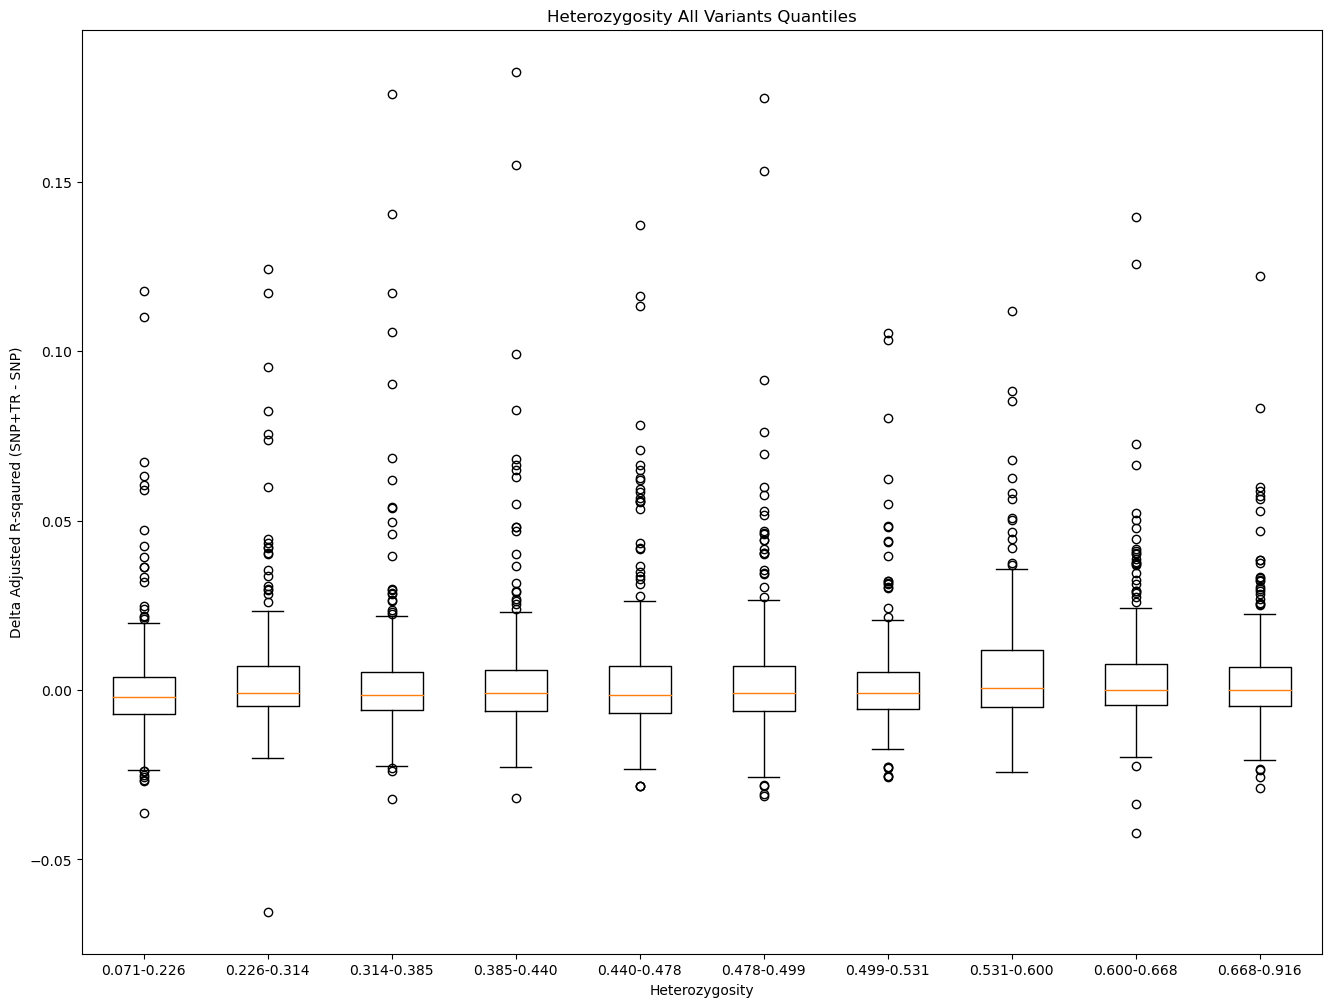

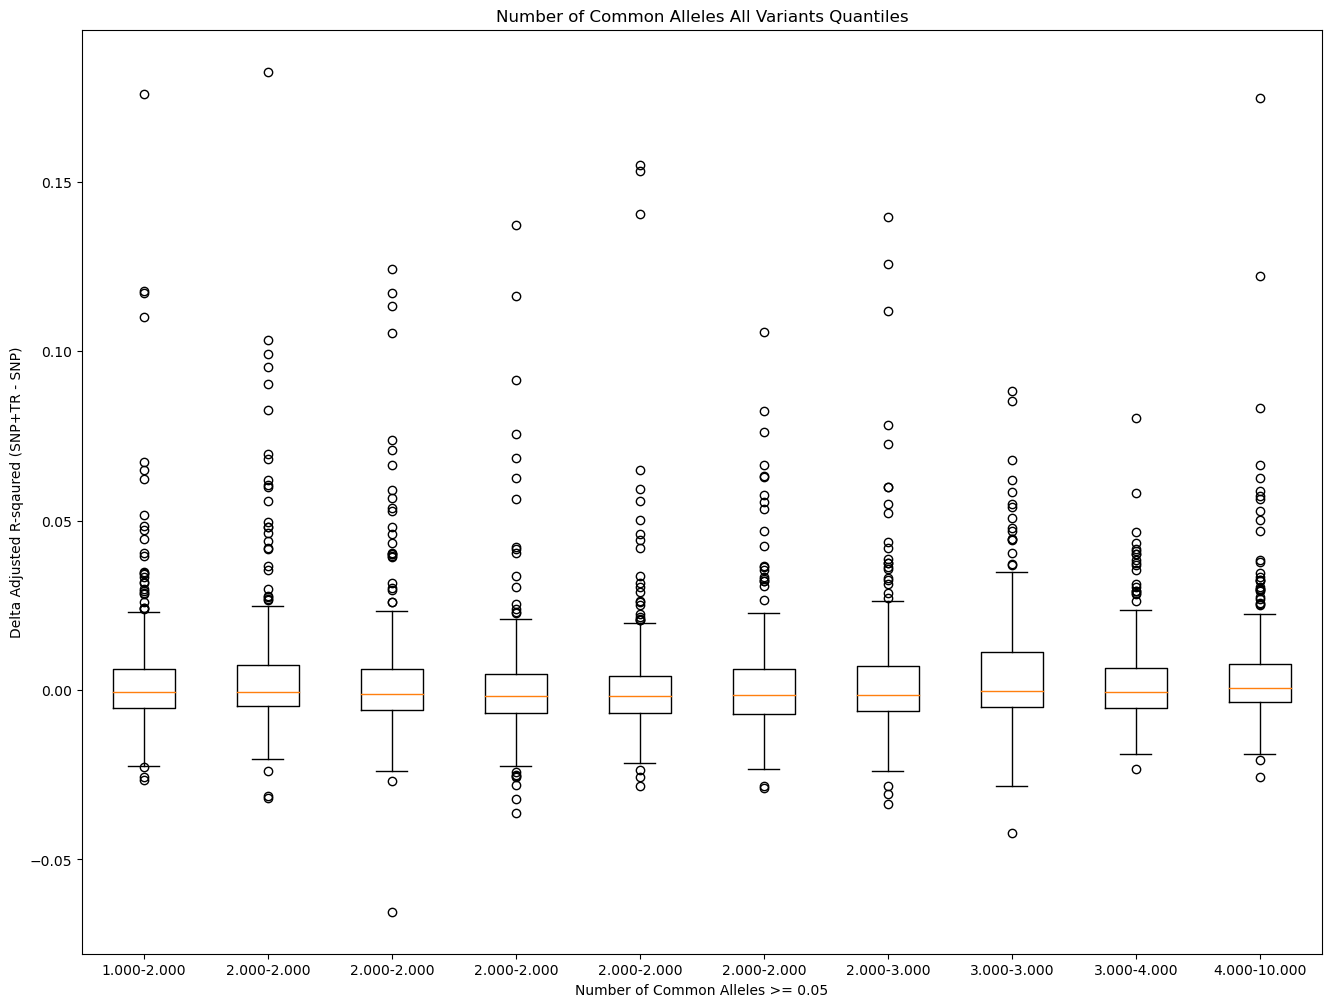

In [24]:
%matplotlib inline

# Load Master Table (gene, p.linear, EUR_alleles, EUR_het, snp_adj_r_squared, snp_str_adj_r_squared)
allele_rsq_df = pd.read_csv(
    master_table, 
    delimiter='\t', 
    usecols=[
        'gene_name',
        'gene',
        'str.start',
        'p.linear',
        'afreq_EUR', 
        'het_EUR',
        'hsq', 
        'hsq.pv',
        'EUR_SNP_adj_R_sq_Mean', 
        'EUR_SNP_STR_adj_R_sq_Mean',
    ]
)

#### Genes that trained ####
# NOTE trained_rsq_df is the finalized df we work with for downstream analyses all others are for comparison purposes
# Filter out genes that didnt train (negative for both) and report these updated numbers under the filtering
trained_allele_rsq_df = allele_rsq_df[(allele_rsq_df['EUR_SNP_adj_R_sq_Mean'] > 0) | (allele_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] > 0)]
trained_allele_rsq_df.loc[trained_allele_rsq_df['EUR_SNP_adj_R_sq_Mean'] < 0, 'EUR_SNP_adj_R_sq_Mean'] = 0
trained_allele_rsq_df.loc[trained_allele_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] < 0, 'EUR_SNP_STR_adj_R_sq_Mean'] = 0
trained_allele_rsq_df['adj_rsq_diff'] = trained_allele_rsq_df['EUR_SNP_STR_adj_R_sq_Mean'] - trained_allele_rsq_df['EUR_SNP_adj_R_sq_Mean']
trained_allele_rsq_df.dropna(inplace=True)

# Plot quantiles and save figures
title = "{} Trained Model Gene Variants Quantiles"
output = "/storage/mlamkin/data/GeneExprPredictor/paper_figures/{}_trained_genes_quantiles.png"
multi_allelic_quantile_plot(
    trained_allele_rsq_df,
    title,
    output,
    common_allele_thresh=0.05,
)

## RPKM Median

In [ ]:
# Calculate median of RPKM data and output

# Load EUR samples from header
EUR_sample_file = "/storage/mlamkin/workspace/TWAS-str/EUR_normalized_and_filtered_hg38.csv"
with open(EUR_sample_file, 'r') as EUR_file:
    EUR_samples = EUR_file.readline()
    EUR_samples = EUR_samples.split('\t')[5:]

# Load EUR gene names
geuv_gene_names = []
with open(EUR_sample_file, 'r') as EUR_file:
    EUR_file.readline()
    for line in EUR_file:
        gene_name = line.strip().split('\t')[3].split('.')[0]
        geuv_gene_names.append(gene_name)

# Load header samples to filter
rpkm_file = "/storage/mlamkin/data/TWAS-str/RPKM_data/GD660.GeneQuantRPKM.txt.gz"
rpkm_header = np.loadtxt(rpkm_file, delimiter="\t", max_rows=1, dtype=np.str_)

# limit to only EUR samples
samples = rpkm_header[4:]
geuv_split_samples = np.char.split(samples, sep='.')
samples = np.array([geuv_split_samples[i][0] for i in range(geuv_split_samples.shape[0])], dtype=object)
overlapping, rpkm_samples, EUR_subset_samples = np.intersect1d(samples, EUR_samples, return_indices=True)

# Load genes that are identical to what we have in our geuvadis data
rpkm_genes = np.loadtxt(rpkm_file, delimiter="\t", skiprows=1, usecols=(0), dtype=np.str_)
rpkm_split_genes = np.char.split(rpkm_genes, sep='.')
rpkm_genes = np.array([rpkm_split_genes[i][0] for i in range(rpkm_split_genes.shape[0])], dtype=object)

# Limit genes to only those in expr data
overlapping, gene_filter, EUR_subset_genes = np.intersect1d(rpkm_genes, np.array(geuv_gene_names), return_indices=True)
rpkm_genes = rpkm_genes[gene_filter]

# Load data and filter all non autosomes
rpkm_data = np.loadtxt(rpkm_file, delimiter="\t", skiprows=1, usecols=np.arange(4, rpkm_header.shape[0]), dtype=np.float32)
rpkm_data = rpkm_data[gene_filter,:]
rpkm_data = rpkm_data[:,rpkm_samples]

# Take median
rpkm_median = np.median(rpkm_data, axis=1)
rpkm_out = np.transpose(np.stack((rpkm_genes, rpkm_median)))
rpkm_out_header = 'GeneID\tRPKM_Median'

np.savetxt("/storage/mlamkin/data/TWAS-str/RPKM_data/geuvadis_EUR_rpkm_median.txt", rpkm_out, fmt='%s', delimiter='\t', comments='', header=rpkm_out_header)

## Gene Expression Imputation Validation

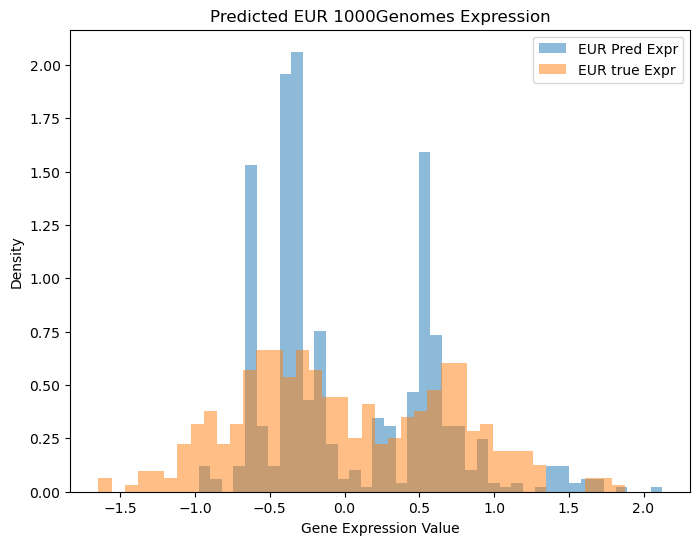

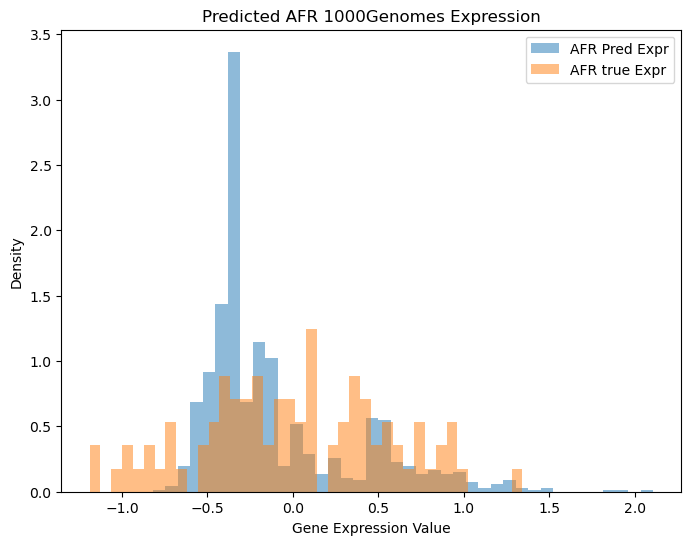

In [2]:
%matplotlib inline

def plot_expr_hist(title, xlabel, ylabel, pred_expr, true_expr, pop, output):
    fig = plt.figure(figsize=(8,6))
    ax = fig.add_subplot(1,1,1)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.hist(
        pred_expr, 
        label=f'{pop} Pred Expr',
        bins=40,
        alpha=0.5,
        density=True,
    )
    ax.hist(
        true_expr,
        label=f"{pop} true Expr",
        bins=40,
        alpha=0.5,
        density=True,
    )
    ax.legend()
    fig.savefig(output)
    plt.show()

def collect_expr(index_file, expr_file, gene_id, gene_id_col):
    # Load EUR Expr
    genes = np.loadtxt(index_file, usecols=gene_id_col, skiprows=1, dtype=str)
    split_genes = np.char.split(genes, sep='.') # Creates numpy array of lists that we need to convert
    genes = np.array([split_genes[i][0] for i in range(split_genes.shape[0])], dtype=object)
    all_expr = np.loadtxt(expr_file, dtype=np.float32)

    # Grab index from EUR genes to load corrected gene expression residuals
    expr = all_expr[:, genes == gene_id]
    return expr

# Gene ID for what expression we're using
gene_id = "ENSG00000134809"

# Load imputed expression
snp_tr_imputed_expression_file = f"/storage/mlamkin/data/GeneExprPredictor/imputed_expression/{gene_id}_snp_tr_predicted_expr.csv"
imp_expr = np.loadtxt(snp_tr_imputed_expression_file, dtype=np.float32)

# Load Sample Names
sample_file = "/storage/mlamkin/data/GeneExprPredictor/imputed_expression/snp_samples.txt"
imp_expr_samples = np.loadtxt(sample_file, dtype=object)

# Load Samples and their super population
sample_metadata_file = "/storage/mlamkin/data/GeneExprPredictor/train_data/igsr_samples.tsv"
sample_metadata = pd.read_csv(sample_metadata_file, delimiter='\t')[["Sample name", "Superpopulation code"]]

# Separate expression samples via superpopulation codes
separated_expr = {}
for sample_ind, sample in enumerate(imp_expr_samples):
    super_code = sample_metadata[sample_metadata["Sample name"] == sample]["Superpopulation code"].item()
    if separated_expr.get(super_code, None) is None:
        separated_expr[super_code] = [imp_expr[sample_ind]]
    else:
        separated_expr[super_code].append(imp_expr[sample_ind])


EUR_true_expr = collect_expr(
    '/storage/mlamkin/data/GeneExprPredictor/train_data/EUR_normalized_and_filtered_hg38.csv',
    '/storage/mlamkin/data/GeneExprPredictor/train_data/EUR_normalized_filtered_final_residuals_hg38.csv',
    gene_id,
    gene_id_col=3
)

# Plot for EUR
plot_expr_hist(
    'Predicted EUR 1000Genomes Expression',
    'Gene Expression Value',
    'Density',
    separated_expr['EUR'],
    EUR_true_expr,
    'EUR',
    '/storage/mlamkin/data/GeneExprPredictor/paper_figures/EUR_1000Genomes_pred_vs_true_expression_hist.pdf'
)


# Load True AFR Expression
AFR_true_expr = collect_expr(
    '/storage/mlamkin/data/GeneExprPredictor/train_data/AFR_normalized_and_filtered_hg38.csv',
    '/storage/mlamkin/data/GeneExprPredictor/train_data/AFR_normalized_filtered_final_residuals_hg38.csv',
    gene_id,
    gene_id_col=3
)

plot_expr_hist(
    'Predicted AFR 1000Genomes Expression',
    'Gene Expression Value',
    'Density',
    separated_expr['AFR'],
    AFR_true_expr,
    'AFR',
    '/storage/mlamkin/data/GeneExprPredictor/paper_figures/AFR_1000Genomes_pred_vs_true_expression_hist.pdf'
)